<a href="https://colab.research.google.com/github/GeonwooBae/plasma-etch-virtual-metrology/blob/main/notebooks/plasma_etch_virtual_metrology.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# Cell 1. Environment Setup
# Plasma Etch Virtual Metrology Project
# ============================================================

!pip -q install netCDF4 xarray openpyxl

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

from pathlib import Path

# 프로젝트 폴더 생성
PROJECT_DIR = Path("/content/plasma_etch_vm")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Environment setup complete.")

Project directory: /content/plasma_etch_vm
Environment setup complete.


In [ ]:
# ============================================================
# Cell 2. Download Core Dataset
# ============================================================

BASE_URL = "https://zenodo.org/records/17122442/files"

files_to_download = [
    "Process_data.nc",
    "Si_Oxide_etch_89_points.csv",
    "Si_Oxide_etch_9_points.csv",
    "Lot_status.xlsx",
]

for filename in files_to_download:

    url = f"{BASE_URL}/{filename}?download=1"
    save_path = PROJECT_DIR / filename

    if not save_path.exists():
        print(f"Downloading: {filename}")
        !wget -q --show-progress "$url" -O "$save_path"
    else:
        print(f"Already exists: {filename}")

print("\nDownload complete.")

Downloading: Process_data.nc
/content/plasma_etc 100%[===================>]   8.41M   966KB/s    in 9.1s    
Downloading: Si_Oxide_etch_89_points.csv
/content/plasma_etc 100%[===================>] 632.57K   643KB/s    in 1.0s    
Downloading: Si_Oxide_etch_9_points.csv
/content/plasma_etc 100%[===================>]  45.85K   193KB/s    in 0.2s    
Downloading: Lot_status.xlsx
/content/plasma_etc 100%[===================>]  11.67K  --.-KB/s    in 0.007s  

Download complete.


In [ ]:
# ============================================================
# Cell 3. Check Downloaded Files
# ============================================================

for file_path in PROJECT_DIR.iterdir():

    size_mb = (
        file_path.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{file_path.name:<35}"
        f"{size_mb:>8.2f} MB"
    )

Si_Oxide_etch_89_points.csv            0.62 MB
Si_Oxide_etch_9_points.csv             0.04 MB
Process_data.nc                        8.41 MB
Lot_status.xlsx                        0.01 MB


In [ ]:
# ============================================================
# Cell 4. Inspect Process Data Structure
# ============================================================

process_file = PROJECT_DIR / "Process_data.nc"

process_ds = xr.open_dataset(process_file)

print("=== Process Dataset ===")
print(process_ds)

print("\n=== Dimensions ===")
print(process_ds.sizes)

print("\n=== Coordinates ===")
print(list(process_ds.coords))

print("\n=== Data Variables ===")
print(list(process_ds.data_vars))

=== Process Dataset ===
<xarray.Dataset> Size: 0B
Dimensions:  ()
Data variables:
    *empty*

=== Dimensions ===
Frozen({})

=== Coordinates ===
[]

=== Data Variables ===
[]


In [ ]:
# ============================================================
# Cell 5. Inspect NetCDF Internal Groups
# ============================================================

import h5py

with h5py.File(process_file, "r") as f:

    print("=== Top-level Groups / Objects ===")

    top_keys = list(f.keys())
    print(top_keys)

    print("\nNumber of top-level objects:", len(top_keys))

    print("\n=== First-level Structure ===")

    for key in top_keys:
        obj = f[key]

        print(
            f"{key:<30} "
            f"{type(obj).__name__}"
        )

=== Top-level Groups / Objects ===
['Day_2024_07_02_Wafer_01', 'Day_2024_07_02_Wafer_02', 'Day_2024_07_02_Wafer_03', 'Day_2024_07_02_Wafer_04', 'Day_2024_07_02_Wafer_05', 'Day_2024_07_02_Wafer_06', 'Day_2024_07_02_Wafer_07', 'Day_2024_07_02_Wafer_08', 'Day_2024_07_02_Wafer_09', 'Day_2024_07_02_Wafer_10', 'Day_2024_07_05_Wafer_01', 'Day_2024_07_05_Wafer_02', 'Day_2024_07_05_Wafer_03', 'Day_2024_07_05_Wafer_04', 'Day_2024_07_05_Wafer_05', 'Day_2024_07_05_Wafer_06', 'Day_2024_07_05_Wafer_07', 'Day_2024_07_05_Wafer_08', 'Day_2024_07_05_Wafer_09', 'Day_2024_07_05_Wafer_10', 'Day_2024_07_09_Wafer_01', 'Day_2024_07_09_Wafer_02', 'Day_2024_07_09_Wafer_03', 'Day_2024_07_09_Wafer_04', 'Day_2024_07_09_Wafer_05', 'Day_2024_07_09_Wafer_06', 'Day_2024_07_09_Wafer_07', 'Day_2024_07_09_Wafer_08', 'Day_2024_07_09_Wafer_09', 'Day_2024_07_09_Wafer_10', 'Day_2024_07_11_Wafer_01', 'Day_2024_07_11_Wafer_02', 'Day_2024_07_11_Wafer_03', 'Day_2024_07_11_Wafer_04', 'Day_2024_07_11_Wafer_05', 'Day_2024_07_11_Waf

### Process Data 구조 확인

`Process_data.nc`의 Root에는 직접적인 Data Variable이 존재하지 않고, 각 Wafer의 공정 데이터가 개별 Group으로 저장되어 있다.

총 90개의 Wafer Group이 존재하며, Group 이름은 `Day_YYYY_MM_DD_Wafer_XX` 형태로 구성되어 있어 공정 날짜와 Wafer 처리 순서를 확인할 수 있다.

이 구조는 이후 각 Wafer의 공정 Sensor Data를 Etch 후 Measurement와 연결하고, 동일 Day 내 Wafer 처리 순서에 따른 Process / Chamber State 변화를 분석하는 데 활용한다.

In [ ]:
# ============================================================
# Cell 6. Inspect One Wafer Group
# ============================================================

with h5py.File(process_file, "r") as f:

    # 첫 번째 Wafer Group 선택
    first_group_name = list(f.keys())[0]
    wafer_group = f[first_group_name]

    print("=== Selected Wafer Group ===")
    print(first_group_name)

    print("\n=== Group Attributes ===")
    if len(wafer_group.attrs) == 0:
        print("No attributes")
    else:
        for key, value in wafer_group.attrs.items():
            print(f"{key}: {value}")

    print("\n=== Objects inside Wafer Group ===")

    for key in wafer_group.keys():

        obj = wafer_group[key]

        if isinstance(obj, h5py.Dataset):
            print(
                f"{key:<35}"
                f"Dataset | "
                f"shape={obj.shape} | "
                f"dtype={obj.dtype}"
            )

        elif isinstance(obj, h5py.Group):
            print(
                f"{key:<35}"
                f"Group | "
                f"{len(obj.keys())} objects"
            )

=== Selected Wafer Group ===
Day_2024_07_02_Wafer_01

=== Group Attributes ===
No attributes

=== Objects inside Wafer Group ===
time                               Dataset | shape=(3245,) | dtype=>f4
times                              Dataset | shape=(3245,) | dtype=float64
feature                            Dataset | shape=(44,) | dtype=object
data                               Dataset | shape=(3245, 44) | dtype=uint16


### Wafer별 Process Data 구조

각 Wafer Group에는 공정 중 수집된 Time-series Process Data가 저장되어 있다.

첫 번째 Wafer를 확인한 결과 총 3,245개의 시간 지점과 44개의 Feature가 존재하며, `data`는 `(time × feature)` 형태의 행렬로 구성되어 있다.

따라서 이후 각 Wafer의 Time-series Process Data에서 통계적·시간적 Feature를 추출하여 Wafer 단위의 Process Feature Vector로 변환한다.

In [ ]:
# ============================================================
# Cell 7. Inspect Process Feature Names
# ============================================================

with h5py.File(process_file, "r") as f:

    first_group_name = list(f.keys())[0]
    wafer_group = f[first_group_name]

    raw_features = wafer_group["feature"][:]

    feature_names = []

    for feature in raw_features:

        if isinstance(feature, bytes):
            feature = feature.decode("utf-8")

        feature_names.append(str(feature))

    print("=== Number of Features ===")
    print(len(feature_names))

    print("\n=== Process Feature Names ===")

    for i, name in enumerate(feature_names):
        print(f"{i:02d}: {name}")

=== Number of Features ===
44

=== Process Feature Names ===
00: Stat3_Etch_MV_EpdIntensity
01: Stat3_Etch_MV_ForeLinePressure
02: Stat3_Etch_MV_Gas1Flow
03: Stat3_Etch_MV_Gas2Flow
04: Stat3_Etch_MV_Gas3Flow
05: Stat3_Etch_MV_Gas4Flow
06: Stat3_Etch_MV_Gas5Flow
07: Stat3_Etch_MV_Gas6Flow
08: Stat3_Etch_MV_Gas7Flow
09: Stat3_Etch_MV_Gas8Flow
10: Stat3_Etch_MV_Heater1Temp
11: Stat3_Etch_MV_Heater2Temp
12: Stat3_Etch_MV_Heater3Temp
13: Stat3_Etch_MV_Heater4Temp
14: Stat3_Etch_MV_Heater5Temp
15: Stat3_Etch_MV_Heater6Temp
16: Stat3_Etch_MV_Heater7Temp
17: Stat3_Etch_MV_Heater8Temp
18: Stat3_Etch_MV_HeliumBPFlow
19: Stat3_Etch_MV_HeliumBPPressure
20: Stat3_Etch_MV_PlatenDcBias
21: Stat3_Etch_MV_PlatenRFLoadCapacitor
22: Stat3_Etch_MV_PlatenRFLoadPower
23: Stat3_Etch_MV_PlatenRFPeakToPeak
24: Stat3_Etch_MV_PlatenRFReflectedPower
25: Stat3_Etch_MV_PlatenRFTuningCapacitor
26: Stat3_Etch_MV_Pressure
27: Stat3_Etch_MV_SourceRF2LoadCapacitor
28: Stat3_Etch_MV_SourceRF2LoadPower
29: Stat3_Etch_MV_S

### Process Feature 구성

각 Wafer의 Etch 공정에서는 총 44개의 Process Feature가 Time-series 형태로 기록되어 있다.

주요 변수에는 Gas Flow, Chamber/Foreline Pressure, Heater 및 Thermocouple Temperature, Backside Helium, Platen Bias/RF, Source RF 및 Endpoint 관련 신호가 포함되어 있다.

따라서 본 프로젝트에서는 이러한 공정 신호의 시간적 특성을 Wafer 단위 Feature로 변환하고, 공정 후 측정된 Etch 결과와 연결하여 Virtual Metrology Model의 입력으로 활용한다.

각 Process Feature의 중요도는 사전에 가정하지 않고, 이후 모델 성능과 SHAP 및 Drift Analysis 결과를 기반으로 분석한다.

In [ ]:
# ============================================================
# Cell 8. Inspect Raw Process Values
# ============================================================

with h5py.File(process_file, "r") as f:

    first_group_name = list(f.keys())[0]
    wafer_group = f[first_group_name]

    # Feature names
    raw_features = wafer_group["feature"][:]

    feature_names = [
        x.decode("utf-8") if isinstance(x, bytes)
        else str(x)
        for x in raw_features
    ]

    # Time and process data
    time_values = wafer_group["time"][:]
    times_values = wafer_group["times"][:]
    process_values = wafer_group["data"][:]


print("=== Selected Wafer ===")
print(first_group_name)

print("\n=== Shapes ===")
print("time :", time_values.shape)
print("times:", times_values.shape)
print("data :", process_values.shape)

print("\n=== First 10 time values ===")
print(time_values[:10])

print("\n=== First 10 'times' values ===")
print(times_values[:10])

print("\n=== Data dtype ===")
print(process_values.dtype)


# DataFrame 생성
first_wafer_process_df = pd.DataFrame(
    process_values,
    columns=feature_names
)

print("\n=== First 5 Rows ===")
display(
    first_wafer_process_df.head()
)


# 각 Feature의 기본 통계
feature_summary_df = pd.DataFrame({
    "min": first_wafer_process_df.min(),
    "max": first_wafer_process_df.max(),
    "mean": first_wafer_process_df.mean(),
    "std": first_wafer_process_df.std(),
    "n_unique": first_wafer_process_df.nunique()
})

print("\n=== Feature Summary ===")
display(feature_summary_df)

=== Selected Wafer ===
Day_2024_07_02_Wafer_01

=== Shapes ===
time : (3245,)
times: (3245,)
data : (3245, 44)

=== First 10 time values ===
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

=== First 10 'times' values ===
[92.76999998 92.96999979 93.16999984 93.36999989 93.56999993 93.76999998
 93.96999979 94.16999984 94.36999989 94.56999993]

=== Data dtype ===
uint16

=== First 5 Rows ===


,Stat3_Etch_MV_EpdIntensity,Stat3_Etch_MV_ForeLinePressure,Stat3_Etch_MV_Gas1Flow,Stat3_Etch_MV_Gas2Flow,Stat3_Etch_MV_Gas3Flow,Stat3_Etch_MV_Gas4Flow,Stat3_Etch_MV_Gas5Flow,Stat3_Etch_MV_Gas6Flow,Stat3_Etch_MV_Gas7Flow,Stat3_Etch_MV_Gas8Flow,...,Stat3_Etch_MV_SourceRFPeakToPeak,Stat3_Etch_MV_SourceRFReflectedPower,Stat3_Etch_MV_SourceRFTuningCapacitor,Stat3_Etch_MV_ThermoCouple1Temp,Stat3_Etch_MV_ThermoCouple2Temp,Stat3_Etch_MV_ThermoCouple3Temp,Stat3_Etch_MV_ThermoCouple4Temp,Stat3_Etch_MV_attenuatorRatio,Stat3_Etch_MV_moriInnerCurrent,Stat3_Etch_MV_moriOuterCurrent
0,43788,8815,1522,2986,619,3105,619,619,2627,619,...,619,1210,2811,619,619,619,619,1767,619,619
1,43788,8968,1550,2981,619,3109,619,619,2594,619,...,619,619,2811,619,619,619,619,1767,619,619
2,43788,8968,1550,2981,619,3109,619,619,2594,619,...,619,619,2811,619,619,619,619,1767,619,619
3,43788,8968,1550,2981,619,3109,619,619,2594,619,...,619,619,2811,619,619,619,619,1767,619,619
4,43788,8968,1550,2981,619,3109,619,619,2594,619,...,619,619,2811,619,619,619,619,1767,619,619



=== Feature Summary ===


,min,max,mean,std,n_unique
Stat3_Etch_MV_EpdIntensity,1407,43788,2399.590447,6410.491701,2
Stat3_Etch_MV_ForeLinePressure,5190,25917,22170.168875,5179.724155,194
Stat3_Etch_MV_Gas1Flow,619,27631,2461.185516,4887.244025,45
Stat3_Etch_MV_Gas2Flow,2916,3026,2990.184592,16.308717,76
Stat3_Etch_MV_Gas3Flow,619,619,619.000000,0.000000,1
Stat3_Etch_MV_Gas4Flow,619,31223,8896.707550,12633.361719,473
Stat3_Etch_MV_Gas5Flow,619,40753,28830.028043,17606.809840,407
Stat3_Etch_MV_Gas6Flow,619,619,619.000000,0.000000,1
Stat3_Etch_MV_Gas7Flow,2470,2633,2588.425270,22.247079,29
Stat3_Etch_MV_Gas8Flow,619,619,619.000000,0.000000,1


### Raw Process Signal 확인

첫 번째 Wafer에는 3,245개의 Time-series Sample과 44개의 Process Feature가 존재한다.

일부 Feature는 공정 중 지속적으로 변화하는 반면, 일부 Feature는 특정 Wafer에서 거의 일정하게 유지된다. 단, 한 Wafer에서 값이 일정하더라도 다른 Wafer 또는 다른 공정 조건에서는 변화할 수 있으므로 현 단계에서는 Feature를 제거하지 않는다.

또한 Process Data가 `uint16` 형태로 저장되어 있으므로, 실제 모델링에 사용하기 전에 Raw Value의 Encoding 및 Scaling 여부와 Time 변수의 의미를 추가적으로 확인한다.

In [ ]:
# ============================================================
# Cell 9. Inspect Time Structure and Dataset Attributes
# ============================================================

with h5py.File(process_file, "r") as f:

    first_group_name = list(f.keys())[0]
    wafer_group = f[first_group_name]

    print("=== Selected Wafer ===")
    print(first_group_name)

    # --------------------------------------------------------
    # 1. Dataset attributes
    # --------------------------------------------------------
    print("\n=== Dataset Attributes ===")

    for dataset_name in [
        "time",
        "times",
        "feature",
        "data"
    ]:

        ds = wafer_group[dataset_name]

        print(f"\n[{dataset_name}]")

        if len(ds.attrs) == 0:
            print("No attributes")
        else:
            for key, value in ds.attrs.items():
                print(f"{key}: {value}")

    # --------------------------------------------------------
    # 2. time structure
    # --------------------------------------------------------
    time_values = wafer_group["time"][:]
    times_values = wafer_group["times"][:]

    print("\n=== 'time' Summary ===")
    print("min :", np.min(time_values))
    print("max :", np.max(time_values))
    print("unique count :", len(np.unique(time_values)))
    print("unique values (first 30):")
    print(np.unique(time_values)[:30])

    print("\n=== 'times' Summary ===")
    print("min :", np.min(times_values))
    print("max :", np.max(times_values))
    print(
        "duration :",
        np.max(times_values) -
        np.min(times_values)
    )

    # sampling interval
    times_diff = np.diff(times_values)

    print("\n=== 'times' Interval ===")
    print("median interval :", np.median(times_diff))
    print("mean interval   :", np.mean(times_diff))
    print("min interval    :", np.min(times_diff))
    print("max interval    :", np.max(times_diff))

    # --------------------------------------------------------
    # 3. Where 'time' changes
    # --------------------------------------------------------
    change_idx = np.where(
        np.diff(time_values) != 0
    )[0]

    print("\n=== 'time' Change Points ===")
    print("number of changes:", len(change_idx))

    print("\nFirst 20 change points:")

    for idx in change_idx[:20]:
        print(
            f"index {idx:4d} -> {idx+1:4d} | "
            f"time: {time_values[idx]} -> "
            f"{time_values[idx+1]} | "
            f"times: {times_values[idx]:.2f} -> "
            f"{times_values[idx+1]:.2f}"
        )

=== Selected Wafer ===
Day_2024_07_02_Wafer_01

=== Dataset Attributes ===

[time]
CLASS: b'DIMENSION_SCALE'
NAME: b'This is a netCDF dimension but not a netCDF variable.      3245'
_Netcdf4Dimid: 1
REFERENCE_LIST: [(<HDF5 object reference>, 0) (<HDF5 object reference>, 0)]

[times]
_Netcdf4Coordinates: [1]
units: b'seconds since 1970-01-01 00:00:00 UTC'
calendar: b'standard'
DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)]
_Netcdf4Dimid: 1

[feature]
_Netcdf4Coordinates: [0]
CLASS: b'DIMENSION_SCALE'
NAME: b'feature'
_Netcdf4Dimid: 0
REFERENCE_LIST: [(<HDF5 object reference>, 1)]

[data]
_Netcdf4Coordinates: [1 0]
DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
_Netcdf4Dimid: 1

=== 'time' Summary ===
min : 0.0
max : 0.0
unique count : 1
unique values (first 30):
[0.]

=== 'times' Summary ===
min : 92.76999998092651
max : 784.25
duration : 691.4800000190735

=== 'times' Interval ===
median interval : 0.20

### Process Data Encoding

`Process_data.nc`의 Process Signal은 실제 센서값이 직접 저장된 형태가 아니라, 데이터 압축을 위해 16-bit Dictionary Encoding이 적용되어 있다.

따라서 `data`에 저장된 `uint16` 값은 실제 Pressure, Gas Flow, RF Power 등의 물리적 측정값이 아니라 `Dictionary_process.nc`의 값을 참조하기 위한 Index이다.

이후 분석에서는 Dictionary를 이용하여 원래 Process Signal 값으로 복원한 뒤 Feature Engineering과 Virtual Metrology Modeling을 수행한다.

또한 `time`은 NetCDF 내부 Dimension이며, 실제 Process 시간축으로는 약 5 Hz로 기록된 `times` 변수를 사용한다.

In [ ]:
# ============================================================
# Cell 10. Download Process Dictionary
# ============================================================

dictionary_filename = "Dictionary_process.nc"

dictionary_url = (
    f"https://zenodo.org/records/17122442/files/"
    f"{dictionary_filename}?download=1"
)

dictionary_path = PROJECT_DIR / dictionary_filename

if not dictionary_path.exists():

    print("Downloading:", dictionary_filename)

    !wget -q --show-progress \
        "$dictionary_url" \
        -O "$dictionary_path"

else:

    print("Already exists:", dictionary_filename)


size_kb = (
    dictionary_path.stat().st_size
    / 1024
)

print(
    f"\n{dictionary_filename}: "
    f"{size_kb:.2f} KB"
)

Downloading: Dictionary_process.nc
/content/plasma_etc 100%[===================>]  86.02K   337KB/s    in 0.3s    

Dictionary_process.nc: 86.02 KB


In [ ]:
# ============================================================
# Cell 11. Decode Process Data
# ============================================================

from netCDF4 import Dataset, num2date

dictionary_path = (
    PROJECT_DIR
    / "Dictionary_process.nc"
)

process_file = (
    PROJECT_DIR
    / "Process_data.nc"
)


# ------------------------------------------------------------
# 1. Load Decoder
# ------------------------------------------------------------

with Dataset(
    dictionary_path,
    "r"
) as dict_ds:

    process_decoder = (
        dict_ds["data"][:]
    )


print(
    "Decoder shape:",
    process_decoder.shape
)


# ------------------------------------------------------------
# 2. Decode First Wafer
# ------------------------------------------------------------

with Dataset(
    process_file,
    "r"
) as ds:

    wafer_names = list(
        ds.groups.keys()
    )

    first_wafer_name = (
        wafer_names[0]
    )

    grp = (
        ds.groups[
            first_wafer_name
        ]
    )

    # Encoded uint16 values
    encoded_data = (
        grp["data"][:]
    )

    # Dictionary decoding
    decoded_data = (
        process_decoder[
            encoded_data
        ]
    )

    # Actual timestamps
    decoded_times = num2date(
        grp["times"][:],
        grp["times"].units,
        grp["times"].calendar,
        only_use_cftime_datetimes=False,
        only_use_python_datetimes=True
    )

    # Process feature names
    decoded_features = (
        grp["feature"][:]
    )


# ------------------------------------------------------------
# 3. DataFrame
# ------------------------------------------------------------

decoded_process_df = pd.DataFrame(
    decoded_data,
    index=decoded_times,
    columns=decoded_features
)


print(
    "=== Selected Wafer ==="
)

print(
    first_wafer_name
)

print(
    "\nShape:",
    decoded_process_df.shape
)

print(
    "\n=== Decoded Process Data ==="
)

display(
    decoded_process_df.head()
)


print(
    "\n=== Decoded Feature Summary ==="
)

decoded_summary_df = (
    decoded_process_df
    .describe()
    .T
)

display(
    decoded_summary_df
)

Decoder shape: (49290,)
=== Selected Wafer ===
Day_2024_07_02_Wafer_01

Shape: (3245, 44)

=== Decoded Process Data ===


,Stat3_Etch_MV_EpdIntensity,Stat3_Etch_MV_ForeLinePressure,Stat3_Etch_MV_Gas1Flow,Stat3_Etch_MV_Gas2Flow,Stat3_Etch_MV_Gas3Flow,Stat3_Etch_MV_Gas4Flow,Stat3_Etch_MV_Gas5Flow,Stat3_Etch_MV_Gas6Flow,Stat3_Etch_MV_Gas7Flow,Stat3_Etch_MV_Gas8Flow,...,Stat3_Etch_MV_SourceRFPeakToPeak,Stat3_Etch_MV_SourceRFReflectedPower,Stat3_Etch_MV_SourceRFTuningCapacitor,Stat3_Etch_MV_ThermoCouple1Temp,Stat3_Etch_MV_ThermoCouple2Temp,Stat3_Etch_MV_ThermoCouple3Temp,Stat3_Etch_MV_ThermoCouple4Temp,Stat3_Etch_MV_attenuatorRatio,Stat3_Etch_MV_moriInnerCurrent,Stat3_Etch_MV_moriOuterCurrent
1970-01-01 00:01:32.770,791.590942,36.011841,0.23,4.12,0.0,4.94,0.0,0.0,2.10,0.0,...,0.0,0.061037,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1970-01-01 00:01:32.970,791.590942,37.232582,0.26,4.08,0.0,4.97,0.0,0.0,2.01,0.0,...,0.0,0.000000,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1970-01-01 00:01:33.170,791.590942,37.232582,0.26,4.08,0.0,4.97,0.0,0.0,2.01,0.0,...,0.0,0.000000,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1970-01-01 00:01:33.370,791.590942,37.232582,0.26,4.08,0.0,4.97,0.0,0.0,2.01,0.0,...,0.0,0.000000,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1970-01-01 00:01:33.570,791.590942,37.232582,0.26,4.08,0.0,4.97,0.0,0.0,2.01,0.0,...,0.0,0.000000,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0



=== Decoded Feature Summary ===


,count,mean,std,min,25%,50%,75%,max
Stat3_Etch_MV_EpdIntensity,3245.0,18.659691,119.718208,0.123000,0.123000,0.123000,0.123000,791.590942
Stat3_Etch_MV_ForeLinePressure,3245.0,127.439751,34.898701,20.752586,90.945160,148.014771,151.676987,157.475510
Stat3_Etch_MV_Gas1Flow,3245.0,7.207150,35.034973,0.000000,0.170000,0.230000,0.280000,200.000000
Stat3_Etch_MV_Gas2Flow,3245.0,4.158323,0.114073,3.670000,4.090000,4.170000,4.240000,4.440000
Stat3_Etch_MV_Gas3Flow,3245.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Stat3_Etch_MV_Gas4Flow,3245.0,71.433914,121.889542,0.000000,0.020000,0.140000,107.860001,300.019989
Stat3_Etch_MV_Gas5Flow,3245.0,408.115601,270.488037,0.000000,0.000000,599.989990,600.000000,600.030029
Stat3_Etch_MV_Gas6Flow,3245.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Stat3_Etch_MV_Gas7Flow,3245.0,2.002841,0.035908,1.850000,1.980000,2.000000,2.020000,2.130000
Stat3_Etch_MV_Gas8Flow,3245.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


### Process Signal Decoding 결과

`Dictionary_process.nc`를 이용하여 압축된 Process Data를 실제 Signal 값으로 복원하였다.

첫 번째 Wafer에서는 약 0.2초 간격으로 총 3,245개의 Process Sample이 기록되어 있으며, 약 691초의 공정 구간을 포함한다.

`times` 변수는 `seconds since 1970-01-01` 형식으로 저장되어 있으나 실제 공정 날짜는 각 Wafer Group 이름에서 확인할 수 있다. 따라서 이후 Time-series 분석에서는 각 Wafer의 첫 Sample을 기준으로 한 Elapsed Time을 사용한다.

일부 Process Channel은 특정 Wafer에서 0 또는 일정한 값을 유지하지만, 다른 Wafer에서 사용될 가능성이 있으므로 전체 Wafer를 확인한 뒤 Feature 사용 여부를 결정한다.

In [ ]:
# ============================================================
# Cell 12. Check All Wafer Process Data
# ============================================================

wafer_process_records = []


with Dataset(process_file, "r") as ds:

    wafer_names = list(ds.groups.keys())

    for wafer_name in wafer_names:

        grp = ds.groups[wafer_name]

        encoded_data = grp["data"][:]
        times = grp["times"][:]

        decoded_data = (
            process_decoder[
                encoded_data
            ]
        )

        # Sampling interval
        time_diff = np.diff(times)

        median_interval = (
            np.median(time_diff)
            if len(time_diff) > 0
            else np.nan
        )

        duration = (
            times[-1] - times[0]
            if len(times) > 1
            else 0
        )

        wafer_process_records.append({

            "wafer_name":
                wafer_name,

            "n_samples":
                decoded_data.shape[0],

            "n_features":
                decoded_data.shape[1],

            "duration_sec":
                duration,

            "median_interval_sec":
                median_interval,

            "nan_count":
                np.isnan(decoded_data).sum(),

            "inf_count":
                np.isinf(decoded_data).sum()
        })


wafer_process_check_df = pd.DataFrame(
    wafer_process_records
)


print("=== Number of Wafers ===")
print(len(wafer_process_check_df))


print("\n=== Process Data Structure Summary ===")
display(
    wafer_process_check_df.describe()
)


print("\n=== First 10 Wafers ===")
display(
    wafer_process_check_df.head(10)
)


print("\n=== Feature Count Distribution ===")
print(
    wafer_process_check_df[
        "n_features"
    ].value_counts()
)


print("\n=== Missing / Infinite Values ===")
print(
    "Total NaN:",
    wafer_process_check_df[
        "nan_count"
    ].sum()
)

print(
    "Total Inf:",
    wafer_process_check_df[
        "inf_count"
    ].sum()
)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


=== Number of Wafers ===
96

=== Process Data Structure Summary ===


,n_samples,n_features,duration_sec,median_interval_sec,nan_count,inf_count
count,96.000000,96.000000,96.000000,96.0,96.0,96.0
mean,3262.177083,32.354167,682.312812,0.2,0.0,0.0
std,67.733533,3.992043,22.112324,0.0,0.0,0.0
min,3193.000000,31.000000,638.400000,0.2,0.0,0.0
25%,3246.000000,31.000000,659.552500,0.2,0.0,0.0
50%,3247.000000,31.000000,690.680000,0.2,0.0,0.0
75%,3297.000000,31.000000,691.712500,0.2,0.0,0.0
max,3835.000000,44.000000,766.800000,0.2,0.0,0.0



=== First 10 Wafers ===


,wafer_name,n_samples,n_features,duration_sec,median_interval_sec,nan_count,inf_count
0,Day_2024_07_02_Wafer_01,3245,44,691.48,0.2,0,0
1,Day_2024_07_02_Wafer_02,3298,44,701.97,0.2,0,0
2,Day_2024_07_02_Wafer_03,3247,44,691.44,0.2,0,0
3,Day_2024_07_02_Wafer_04,3247,44,691.50,0.2,0,0
4,Day_2024_07_02_Wafer_05,3298,44,701.99,0.2,0,0
5,Day_2024_07_02_Wafer_06,3246,44,691.40,0.2,0,0
6,Day_2024_07_02_Wafer_07,3247,44,691.77,0.2,0,0
7,Day_2024_07_02_Wafer_08,3298,44,701.71,0.2,0,0
8,Day_2024_07_02_Wafer_09,3246,44,691.44,0.2,0,0
9,Day_2024_07_02_Wafer_10,3247,44,694.20,0.2,0,0



=== Feature Count Distribution ===
n_features
31    86
44    10
Name: count, dtype: int64

=== Missing / Infinite Values ===
Total NaN: 0
Total Inf: 0


### 전체 Wafer Process Data 구조 확인

전체 `Process_data.nc`에는 총 96개의 Wafer Process Record가 존재하며, 모든 Wafer에서 약 0.2초 간격의 Time-series Signal이 기록되어 있다. NaN 및 Infinite Value는 확인되지 않았다.

다만 Wafer별 Process Feature 수를 확인한 결과 86개 Wafer는 31개 Feature, 10개 Wafer는 44개 Feature를 포함하고 있었다.

따라서 서로 다른 실험 조건에서 Sensor Channel 구성이 달라졌을 가능성을 고려하여, 모델링에 앞서 전체 Wafer에서 공통으로 존재하는 Process Feature와 특정 Wafer에서만 존재하는 Feature를 구분한다.

In [ ]:
# ============================================================
# Runtime Cleanup
# ============================================================

import gc

try:
    process_ds.close()
except:
    pass

gc.collect()

print("Cleanup complete.")

Cleanup complete.


In [ ]:
# ============================================================
# Cell 13. Compare Process Feature Sets Across Wafers
# ============================================================

wafer_feature_records = []
wafer_feature_sets = {}


with Dataset(process_file, "r") as ds:

    wafer_names = list(ds.groups.keys())

    for wafer_name in wafer_names:

        grp = ds.groups[wafer_name]

        raw_features = grp["feature"][:]

        feature_names = [
            x.decode("utf-8")
            if isinstance(x, bytes)
            else str(x)
            for x in raw_features
        ]

        wafer_feature_sets[wafer_name] = set(
            feature_names
        )

        wafer_feature_records.append({

            "wafer_name":
                wafer_name,

            "n_features":
                len(feature_names),

            "date":
                wafer_name.split("_Wafer_")[0],

            "wafer_number":
                wafer_name.split("_Wafer_")[1]
        })


wafer_feature_df = pd.DataFrame(
    wafer_feature_records
)


# ------------------------------------------------------------
# 1. Feature 수별 Wafer
# ------------------------------------------------------------

print("=== Feature Count Distribution ===")

display(
    wafer_feature_df[
        "n_features"
    ].value_counts()
    .sort_index()
    .rename("wafer_count")
    .to_frame()
)


print("\n=== Wafers with 44 Features ===")

display(
    wafer_feature_df[
        wafer_feature_df["n_features"] == 44
    ]
)


print("\n=== Wafers with 31 Features ===")

display(
    wafer_feature_df[
        wafer_feature_df["n_features"] == 31
    ].head(20)
)


# ------------------------------------------------------------
# 2. 날짜별 Feature 수 확인
# ------------------------------------------------------------

print("\n=== Feature Count by Date ===")

feature_by_date = pd.crosstab(
    wafer_feature_df["date"],
    wafer_feature_df["n_features"]
)

display(
    feature_by_date
)


# ------------------------------------------------------------
# 3. 전체 Wafer 공통 / 전체 Feature
# ------------------------------------------------------------

all_feature_sets = list(
    wafer_feature_sets.values()
)

common_features = set.intersection(
    *all_feature_sets
)

union_features = set.union(
    *all_feature_sets
)


print("\n=== Common Features Across ALL Wafers ===")
print(
    "Number of common features:",
    len(common_features)
)

for name in sorted(common_features):
    print(name)


print("\n=== Union of ALL Features ===")
print(
    "Number of total unique features:",
    len(union_features)
)


# ------------------------------------------------------------
# 4. 44-feature Wafer에만 존재하는 Feature
# ------------------------------------------------------------

example_44 = (
    wafer_feature_df[
        wafer_feature_df["n_features"] == 44
    ]["wafer_name"].iloc[0]
)

example_31 = (
    wafer_feature_df[
        wafer_feature_df["n_features"] == 31
    ]["wafer_name"].iloc[0]
)


extra_in_44 = (
    wafer_feature_sets[example_44]
    -
    wafer_feature_sets[example_31]
)

missing_from_44 = (
    wafer_feature_sets[example_31]
    -
    wafer_feature_sets[example_44]
)


print(
    "\n=== Features Present in 44-feature Wafer "
    "but NOT 31-feature Wafer ==="
)

print(
    "Count:",
    len(extra_in_44)
)

for name in sorted(extra_in_44):
    print(name)


print(
    "\n=== Features Present in 31-feature Wafer "
    "but NOT 44-feature Wafer ==="
)

print(
    "Count:",
    len(missing_from_44)
)

for name in sorted(missing_from_44):
    print(name)

=== Feature Count Distribution ===


,wafer_count
n_features,
31,86
44,10



=== Wafers with 44 Features ===


,wafer_name,n_features,date,wafer_number
0,Day_2024_07_02_Wafer_01,44,Day_2024_07_02,01
1,Day_2024_07_02_Wafer_02,44,Day_2024_07_02,02
2,Day_2024_07_02_Wafer_03,44,Day_2024_07_02,03
3,Day_2024_07_02_Wafer_04,44,Day_2024_07_02,04
4,Day_2024_07_02_Wafer_05,44,Day_2024_07_02,05
5,Day_2024_07_02_Wafer_06,44,Day_2024_07_02,06
6,Day_2024_07_02_Wafer_07,44,Day_2024_07_02,07
7,Day_2024_07_02_Wafer_08,44,Day_2024_07_02,08
8,Day_2024_07_02_Wafer_09,44,Day_2024_07_02,09
9,Day_2024_07_02_Wafer_10,44,Day_2024_07_02,10



=== Wafers with 31 Features ===


,wafer_name,n_features,date,wafer_number
10,Day_2024_07_05_Wafer_01,31,Day_2024_07_05,01
11,Day_2024_07_05_Wafer_02,31,Day_2024_07_05,02
12,Day_2024_07_05_Wafer_03,31,Day_2024_07_05,03
13,Day_2024_07_05_Wafer_04,31,Day_2024_07_05,04
14,Day_2024_07_05_Wafer_05,31,Day_2024_07_05,05
15,Day_2024_07_05_Wafer_06,31,Day_2024_07_05,06
16,Day_2024_07_05_Wafer_07,31,Day_2024_07_05,07
17,Day_2024_07_05_Wafer_08,31,Day_2024_07_05,08
18,Day_2024_07_05_Wafer_09,31,Day_2024_07_05,09
19,Day_2024_07_05_Wafer_10,31,Day_2024_07_05,10



=== Feature Count by Date ===


n_features,31,44
date,,
Day_2024_07_02,0,10
Day_2024_07_05,10,0
Day_2024_07_09,10,0
Day_2024_07_11,10,0
Day_2024_07_19,10,0
Day_2024_08_01,10,0
Day_2024_08_05,6,0
Day_2024_08_07,10,0
Day_2024_08_21,10,0



=== Common Features Across ALL Wafers ===
Number of common features: 31
Stat3_Etch_MV_EpdIntensity
Stat3_Etch_MV_ForeLinePressure
Stat3_Etch_MV_Gas1Flow
Stat3_Etch_MV_Gas2Flow
Stat3_Etch_MV_Gas3Flow
Stat3_Etch_MV_Gas4Flow
Stat3_Etch_MV_Gas5Flow
Stat3_Etch_MV_Gas7Flow
Stat3_Etch_MV_Gas8Flow
Stat3_Etch_MV_Heater1Temp
Stat3_Etch_MV_Heater2Temp
Stat3_Etch_MV_Heater3Temp
Stat3_Etch_MV_Heater4Temp
Stat3_Etch_MV_HeliumBPFlow
Stat3_Etch_MV_HeliumBPPressure
Stat3_Etch_MV_PlatenDcBias
Stat3_Etch_MV_PlatenRFLoadCapacitor
Stat3_Etch_MV_PlatenRFLoadPower
Stat3_Etch_MV_PlatenRFPeakToPeak
Stat3_Etch_MV_PlatenRFReflectedPower
Stat3_Etch_MV_PlatenRFTuningCapacitor
Stat3_Etch_MV_Pressure
Stat3_Etch_MV_SourceRF2LoadPower
Stat3_Etch_MV_SourceRF2PeakToPeak
Stat3_Etch_MV_SourceRF2ReflectedPower
Stat3_Etch_MV_SourceRF2TuningCapacitor
Stat3_Etch_MV_SourceRFLoadPower
Stat3_Etch_MV_SourceRFPeakToPeak
Stat3_Etch_MV_SourceRFReflectedPower
Stat3_Etch_MV_SourceRFTuningCapacitor
Stat3_Etch_MV_moriInnerCurrent

=== 

### 전체 Wafer Process Feature 구성

전체 96개 Wafer의 Process Feature 구성을 비교한 결과, 86개 Wafer는 31개의 Feature를 포함하고 있으며 2024-07-02에 처리된 10개 Wafer에는 13개의 추가 Sensor Feature가 기록되어 총 44개의 Feature가 존재하였다.

31개의 Process Feature는 모든 Wafer에 공통으로 존재하였으며, 31-feature Wafer에만 존재하는 별도의 Feature는 확인되지 않았다.

따라서 Wafer 간 동일한 입력 구조를 유지하고 전체 96개의 Wafer를 활용하기 위해, Main Virtual Metrology Model에서는 모든 Wafer에 공통으로 존재하는 31개의 Process Feature를 사용한다. 2024-07-02 Wafer에만 존재하는 13개의 추가 Feature는 Main Modeling에서는 제외한다.

In [ ]:
# ============================================================
# Cell 14. Inspect 89-Point Etch Measurement Data
# ============================================================

measurement_89_path = (
    PROJECT_DIR
    / "Si_Oxide_etch_89_points.csv"
)

etch_89_df = pd.read_csv(
    measurement_89_path
)


print("=== 89-Point Measurement Shape ===")
print(etch_89_df.shape)


print("\n=== Column Names ===")

for i, col in enumerate(
    etch_89_df.columns
):
    print(f"{i:02d}: {col}")


print("\n=== First 10 Rows ===")
display(
    etch_89_df.head(10)
)


print("\n=== Basic Information ===")
print(
    etch_89_df.info()
)

=== 89-Point Measurement Shape ===
(7832, 11)

=== Column Names ===
00: experiment_key
01: lot_number
02: wafer_number
03: X
04: Y
05: preox_thickness
06: postox_thickness
07: postox_thickness_nan
08: stepheight
09: oxide_etch
10: si_etch

=== First 10 Rows ===


,experiment_key,lot_number,wafer_number,X,Y,preox_thickness,postox_thickness,postox_thickness_nan,stepheight,oxide_etch,si_etch
0,2024-07-02_01,1,1,-19000,-95000,1.002226,0.5259,0.5259,52.9890,0.476326,52.4631
1,2024-07-02_01,1,1,0,-95000,1.003400,0.5408,0.5408,52.5790,0.462600,52.0382
2,2024-07-02_01,1,1,19000,-95000,1.002493,0.5240,0.5240,53.2003,0.478493,52.6763
3,2024-07-02_01,1,1,-57000,-76000,0.999300,0.5420,0.5420,52.8116,0.457300,52.2696
4,2024-07-02_01,1,1,-38000,-76000,1.000041,0.4795,0.4795,46.8974,0.520541,46.4179
5,2024-07-02_01,1,1,-19000,-76000,1.001496,0.4536,0.4536,45.0108,0.547896,44.5572
6,2024-07-02_01,1,1,0,-76000,1.002334,0.4458,0.4458,44.5173,0.556534,44.0715
7,2024-07-02_01,1,1,19000,-76000,1.001973,0.4553,0.4553,44.8282,0.546673,44.3729
8,2024-07-02_01,1,1,38000,-76000,1.001630,0.4820,0.4820,46.4509,0.519630,45.9689
9,2024-07-02_01,1,1,57000,-76000,1.001600,0.5380,0.5380,51.9240,0.463600,51.3860



=== Basic Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7832 entries, 0 to 7831
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   experiment_key        7832 non-null   object 
 1   lot_number            7832 non-null   int64  
 2   wafer_number          7832 non-null   int64  
 3   X                     7832 non-null   int64  
 4   Y                     7832 non-null   int64  
 5   preox_thickness       7832 non-null   float64
 6   postox_thickness      7832 non-null   float64
 7   postox_thickness_nan  7675 non-null   float64
 8   stepheight            7832 non-null   float64
 9   oxide_etch            7832 non-null   float64
 10  si_etch               7832 non-null   float64
dtypes: float64(6), int64(4), object(1)
memory usage: 673.2+ KB
None


### 89-point Wafer Measurement 구조

Etch 후 Wafer Measurement Data는 Wafer 내 89개 위치를 각각 하나의 Row로 저장하고 있으며, 각 위치의 X/Y 좌표와 Etch 결과를 포함한다.

주요 측정값은 Etch 전·후 SiO₂ Mask Thickness, Step Height, Oxide Etch 및 Si Etch Depth이다.

본 프로젝트에서는 BOSCH Etch의 실제 Silicon Etch 결과를 나타내는 `si_etch`를 주요 Target으로 사용한다. 각 Wafer의 89-point `si_etch` 값을 이용하여 Mean Si Etch Depth, Within-Wafer Uniformity 및 Center–Edge Difference를 생성하고, 확장 실험에서는 89개 위치 전체의 Spatial Etch Profile을 예측한다.

# oxide_etch = 식각 과정에서 소모된 SiO₂ mask 두께

# si_etch가 실제 Silicon 쪽 Etch Depth에 해당하는 구조

In [ ]:
# ============================================================
# Cell 15. Validate 89-Point Measurement Structure
# ============================================================

# ------------------------------------------------------------
# 1. Wafer 수 및 Point 수 확인
# ------------------------------------------------------------

point_counts = (
    etch_89_df
    .groupby("experiment_key")
    .size()
)


print("=== Number of Measured Wafers ===")
print(
    etch_89_df[
        "experiment_key"
    ].nunique()
)


print("\n=== Number of Points per Wafer ===")
print(
    point_counts.value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 2. X/Y 위치 수 확인
# ------------------------------------------------------------

xy_counts = (
    etch_89_df
    .groupby("experiment_key")
    .apply(
        lambda df:
        df[["X", "Y"]]
        .drop_duplicates()
        .shape[0],
        include_groups=False
    )
)


print("\n=== Unique X/Y Positions per Wafer ===")
print(
    xy_counts.value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 3. Oxide Etch 계산 관계 확인
# ------------------------------------------------------------

oxide_expected = (
    etch_89_df["preox_thickness"]
    -
    etch_89_df["postox_thickness"]
)

oxide_error = np.abs(
    etch_89_df["oxide_etch"]
    -
    oxide_expected
)


print("\n=== Oxide Etch Formula Check ===")
print(
    "Max absolute difference:",
    oxide_error.max()
)


# ------------------------------------------------------------
# 4. Si Etch 계산 관계 확인
# ------------------------------------------------------------

si_expected = (
    etch_89_df["stepheight"]
    -
    etch_89_df["postox_thickness"]
)

si_error = np.abs(
    etch_89_df["si_etch"]
    -
    si_expected
)


print("\n=== Si Etch Formula Check ===")
print(
    "Max absolute difference:",
    si_error.max()
)


# ------------------------------------------------------------
# 5. postox 두 Column 비교
# ------------------------------------------------------------

postox_difference = np.abs(
    etch_89_df["postox_thickness"]
    -
    etch_89_df["postox_thickness_nan"]
)


print("\n=== Post-Oxide Column Comparison ===")

print(
    "Different rows:",
    (postox_difference > 1e-12).sum()
)

print(
    "Max difference:",
    postox_difference.max()
)


# ------------------------------------------------------------
# 6. Example Wafer
# ------------------------------------------------------------

example_key = (
    etch_89_df[
        "experiment_key"
    ].iloc[0]
)

example_wafer_df = (
    etch_89_df[
        etch_89_df[
            "experiment_key"
        ] == example_key
    ]
)


print("\n=== Example Wafer ===")
print("experiment_key:", example_key)
print("number of points:", len(example_wafer_df))

display(
    example_wafer_df.head()
)

=== Number of Measured Wafers ===
88

=== Number of Points per Wafer ===
89    88
Name: count, dtype: int64

=== Unique X/Y Positions per Wafer ===
89    88
Name: count, dtype: int64

=== Oxide Etch Formula Check ===
Max absolute difference: 1.0000001937626735e-09

=== Si Etch Formula Check ===
Max absolute difference: 5.000003966415534e-09

=== Post-Oxide Column Comparison ===
Different rows: 0
Max difference: 0.0

=== Example Wafer ===
experiment_key: 2024-07-02_01
number of points: 89


,experiment_key,lot_number,wafer_number,X,Y,preox_thickness,postox_thickness,postox_thickness_nan,stepheight,oxide_etch,si_etch
0,2024-07-02_01,1,1,-19000,-95000,1.002226,0.5259,0.5259,52.9890,0.476326,52.4631
1,2024-07-02_01,1,1,0,-95000,1.003400,0.5408,0.5408,52.5790,0.462600,52.0382
2,2024-07-02_01,1,1,19000,-95000,1.002493,0.5240,0.5240,53.2003,0.478493,52.6763
3,2024-07-02_01,1,1,-57000,-76000,0.999300,0.5420,0.5420,52.8116,0.457300,52.2696
4,2024-07-02_01,1,1,-38000,-76000,1.000041,0.4795,0.4795,46.8974,0.520541,46.4179


### 89-point Measurement 검증 결과

89-point Measurement Data에는 총 88개의 Wafer가 존재하며, 각 Wafer는 동일하게 89개의 X/Y 측정 위치를 포함한다.

전체 데이터를 검증한 결과 `oxide_etch = preox_thickness - postox_thickness`, `si_etch = stepheight - postox_thickness` 관계가 수치 오차 범위 내에서 정확히 성립하였다.

따라서 이후 Virtual Metrology의 주요 Target은 각 Wafer의 89-point `si_etch`를 기반으로 생성한다.

In [ ]:
# ============================================================
# Cell 16. Match Process Data and 89-Point Measurement
# ============================================================

# ------------------------------------------------------------
# 1. Process Wafer 이름을 Measurement key 형식으로 변환
#
# Day_2024_07_02_Wafer_01
#        ↓
# 2024-07-02_01
# ------------------------------------------------------------

def process_name_to_experiment_key(
    wafer_name
):

    parts = wafer_name.split("_")

    year = parts[1]
    month = parts[2]
    day = parts[3]
    wafer_num = parts[-1]

    return (
        f"{year}-{month}-{day}_"
        f"{wafer_num}"
    )


process_match_df = (
    wafer_feature_df[
        ["wafer_name"]
    ]
    .copy()
)


process_match_df[
    "experiment_key"
] = (
    process_match_df[
        "wafer_name"
    ]
    .apply(
        process_name_to_experiment_key
    )
)


# ------------------------------------------------------------
# 2. Measurement Wafer 목록
# ------------------------------------------------------------

measurement_wafer_df = (
    etch_89_df[
        [
            "experiment_key",
            "lot_number",
            "wafer_number"
        ]
    ]
    .drop_duplicates()
    .copy()
)


# ------------------------------------------------------------
# 3. Set 비교
# ------------------------------------------------------------

process_keys = set(
    process_match_df[
        "experiment_key"
    ]
)

measurement_keys = set(
    measurement_wafer_df[
        "experiment_key"
    ]
)


matched_keys = (
    process_keys
    &
    measurement_keys
)

process_only_keys = (
    process_keys
    -
    measurement_keys
)

measurement_only_keys = (
    measurement_keys
    -
    process_keys
)


print("=== Wafer Matching Summary ===")

print(
    "Process wafers     :",
    len(process_keys)
)

print(
    "Measurement wafers :",
    len(measurement_keys)
)

print(
    "Matched wafers     :",
    len(matched_keys)
)

print(
    "Process only       :",
    len(process_only_keys)
)

print(
    "Measurement only   :",
    len(measurement_only_keys)
)


# ------------------------------------------------------------
# 4. Process Data에만 존재하는 Wafer
# ------------------------------------------------------------

print(
    "\n=== Process-only Wafers ==="
)

for key in sorted(
    process_only_keys
):
    print(key)


# ------------------------------------------------------------
# 5. Measurement에만 존재하는 Wafer
# ------------------------------------------------------------

print(
    "\n=== Measurement-only Wafers ==="
)

for key in sorted(
    measurement_only_keys
):
    print(key)


# ------------------------------------------------------------
# 6. 최종 Matching Table
# ------------------------------------------------------------

wafer_matching_df = (
    process_match_df
    .merge(
        measurement_wafer_df,
        on="experiment_key",
        how="inner"
    )
    .sort_values(
        "experiment_key"
    )
    .reset_index(drop=True)
)


print(
    "\n=== Final Matched Wafer Table ==="
)

display(
    wafer_matching_df.head(20)
)

print(
    "\nFinal matched wafer count:",
    len(wafer_matching_df)
)

=== Wafer Matching Summary ===
Process wafers     : 96
Measurement wafers : 88
Matched wafers     : 88
Process only       : 8
Measurement only   : 0

=== Process-only Wafers ===
2024-07-02_07
2024-08-21_09
2024-08-22_05
2024-08-22_06
2024-08-22_07
2024-08-22_08
2024-08-22_09
2024-08-22_10

=== Measurement-only Wafers ===

=== Final Matched Wafer Table ===


,wafer_name,experiment_key,lot_number,wafer_number
0,Day_2024_07_02_Wafer_01,2024-07-02_01,1,1
1,Day_2024_07_02_Wafer_02,2024-07-02_02,1,2
2,Day_2024_07_02_Wafer_03,2024-07-02_03,1,3
3,Day_2024_07_02_Wafer_04,2024-07-02_04,1,4
4,Day_2024_07_02_Wafer_05,2024-07-02_05,1,5
5,Day_2024_07_02_Wafer_06,2024-07-02_06,1,6
6,Day_2024_07_02_Wafer_08,2024-07-02_08,1,8
7,Day_2024_07_02_Wafer_09,2024-07-02_09,1,9
8,Day_2024_07_02_Wafer_10,2024-07-02_10,1,10
9,Day_2024_07_05_Wafer_01,2024-07-05_01,2,1



Final matched wafer count: 88


### Process Data와 Etch Measurement Matching

Process Data에는 총 96개의 Wafer가 존재하며, 89-point Etch Measurement는 88개의 Wafer에서 제공된다.

Wafer의 공정 날짜와 처리 번호를 이용하여 두 Dataset을 Matching한 결과, Measurement가 존재하는 88개 Wafer 모두 대응되는 Process Data를 가지고 있음을 확인하였다.

따라서 Virtual Metrology의 학습 및 평가에는 Process Signal과 89-point Si Etch Measurement가 모두 존재하는 88개의 Wafer를 사용한다.

Measurement가 존재하지 않는 8개의 Process Wafer는 Supervised Modeling에서는 제외하되, 이후 Process Drift 분석에 활용할 가능성을 고려하여 별도로 유지한다.

In [ ]:
# ============================================================
# Cell 17. Inspect Lot Status Data
# ============================================================

lot_status_path = (
    PROJECT_DIR
    / "Lot_status.xlsx"
)


# ------------------------------------------------------------
# 1. Excel Sheet 확인
# ------------------------------------------------------------

excel_file = pd.ExcelFile(
    lot_status_path
)

print("=== Sheet Names ===")
print(
    excel_file.sheet_names
)


# ------------------------------------------------------------
# 2. 각 Sheet 구조 확인
# ------------------------------------------------------------

for sheet_name in excel_file.sheet_names:

    print(
        "\n" + "=" * 70
    )

    print(
        f"Sheet: {sheet_name}"
    )

    print(
        "=" * 70
    )

    temp_df = pd.read_excel(
        lot_status_path,
        sheet_name=sheet_name
    )

    print(
        "Shape:",
        temp_df.shape
    )

    print(
        "\nColumns:"
    )

    for i, col in enumerate(
        temp_df.columns
    ):
        print(
            f"{i:02d}: {col}"
        )

    print(
        "\nFirst Rows:"
    )

    display(
        temp_df.head(15)
    )

=== Sheet Names ===
['Tabelle1']

Sheet: Tabelle1
Shape: (35, 5)

Columns:
00: Lot No.
01: Date
02: Wafers 
03: Measurements
04: Type

First Rows:


,Lot No.,Date,Wafers,Measurements,Type
0,Lot 1,2th July 2024,10,89 & 9 points,3C
1,Lot 2,5th July 2024,10,89 & 9 points,1C
2,Lot 3,9th July 2024,10,89 & 9 points,9C
3,Lot 4,11th July 2024,10,89 & 9 points,3C - Si
4,Lot 5,19th July 2024,10,89 & 9 points,1C - Si
5,Lot 6,1st Aug 2024,10,89 & 9 points,9C - Si
6,Lot 7,5th Aug 2024,6,89 & 9 points,3C - SiO2
7,Lot 8,7th Aug 2024,10,89 points,3C - SiO2
8,Lot 9,21st Aug 2024,10,89 & 9 points,3C
9,Lot 10,22nd Aug 2024,10,89 points,3C - SiO2


### Experimental Lot 및 Conditioning 구성

본 Dataset은 Chamber Conditioning 조건에 따른 Plasma Etch Process 변화와 Wafer Sequence Drift를 분석할 수 있도록 구성되어 있다.

Conditioning은 Chuck(C), blank Si wafer(Si), blank SiO₂ wafer(SiO₂)에서 수행되었으며, 각 조건에서 Cleaning/Conditioning Sequence를 1회, 3회 또는 9회 반복하였다.

Conditioning 이후 각 Lot의 Wafer는 중간 Cleaning 없이 순차적으로 Etch되었기 때문에, 동일 Lot 내 Wafer 처리 순서를 이용하여 Chamber State 변화 및 Process Drift를 분석할 수 있다.

단, Conditioning 조건이 Etch 결과에 특정한 방향의 영향을 미친다고 사전에 가정하지 않고, 실제 Process Signal과 Wafer Measurement를 기반으로 관계를 분석한다.

In [ ]:
# ============================================================
# Cell 18. Build and Merge Lot Metadata
# ============================================================

# ------------------------------------------------------------
# 1. Lot Status 원본 불러오기
# ------------------------------------------------------------

lot_raw_df = pd.read_excel(
    lot_status_path,
    sheet_name="Tabelle1"
)


# ------------------------------------------------------------
# 2. Column 이름 정리
#    숨은 공백 / 특수 공백 제거
# ------------------------------------------------------------

lot_raw_df.columns = (
    lot_raw_df.columns
    .astype(str)
    .str.replace("\xa0", " ", regex=False)
    .str.strip()
)


print("=== Cleaned Column Names ===")

for col in lot_raw_df.columns:
    print(repr(col))


# ------------------------------------------------------------
# 3. 실제 Lot Row만 추출
# ------------------------------------------------------------

lot_meta_df = (
    lot_raw_df[
        lot_raw_df["Lot No."]
        .astype(str)
        .str.strip()
        .str.match(r"Lot \d+$")
    ]
    .copy()
)


# ------------------------------------------------------------
# 4. Lot Number 숫자로 변환
# ------------------------------------------------------------

lot_meta_df["lot_number"] = (
    lot_meta_df["Lot No."]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(int)
)


# ------------------------------------------------------------
# 5. 필요한 Column만 유지
# ------------------------------------------------------------

lot_meta_df = (
    lot_meta_df[
        [
            "lot_number",
            "Date",
            "Wafers",
            "Measurements",
            "Type"
        ]
    ]
    .rename(
        columns={
            "Date":
                "lot_date",

            "Wafers":
                "planned_wafers",

            "Measurements":
                "measurement_type",

            "Type":
                "conditioning_type"
        }
    )
)


print("\n=== Clean Lot Metadata ===")

display(
    lot_meta_df
)


# ------------------------------------------------------------
# 6. Matched Wafer Table과 Merge
# ------------------------------------------------------------

wafer_metadata_df = (
    wafer_matching_df
    .merge(
        lot_meta_df,
        on="lot_number",
        how="left"
    )
)


# 동일 Lot 내 Wafer 처리 순서
wafer_metadata_df[
    "wafer_sequence"
] = (
    wafer_metadata_df[
        "wafer_number"
    ]
)


print(
    "\n=== Final Wafer Metadata ==="
)

display(
    wafer_metadata_df.head(20)
)


print(
    "\n=== Matched Wafers by Lot ==="
)

display(
    wafer_metadata_df
    .groupby(
        [
            "lot_number",
            "conditioning_type"
        ]
    )
    .size()
    .rename("matched_wafers")
    .reset_index()
)


print(
    "\nMissing Conditioning Info:",
    wafer_metadata_df[
        "conditioning_type"
    ].isna().sum()
)

=== Cleaned Column Names ===
'Lot No.'
'Date'
'Wafers'
'Measurements'
'Type'

=== Clean Lot Metadata ===


,lot_number,lot_date,planned_wafers,measurement_type,conditioning_type
0,1,2th July 2024,10,89 & 9 points,3C
1,2,5th July 2024,10,89 & 9 points,1C
2,3,9th July 2024,10,89 & 9 points,9C
3,4,11th July 2024,10,89 & 9 points,3C - Si
4,5,19th July 2024,10,89 & 9 points,1C - Si
5,6,1st Aug 2024,10,89 & 9 points,9C - Si
6,7,5th Aug 2024,6,89 & 9 points,3C - SiO2
7,8,7th Aug 2024,10,89 points,3C - SiO2
8,9,21st Aug 2024,10,89 & 9 points,3C
9,10,22nd Aug 2024,10,89 points,3C - SiO2



=== Final Wafer Metadata ===


,wafer_name,experiment_key,lot_number,wafer_number,lot_date,planned_wafers,measurement_type,conditioning_type,wafer_sequence
0,Day_2024_07_02_Wafer_01,2024-07-02_01,1,1,2th July 2024,10,89 & 9 points,3C,1
1,Day_2024_07_02_Wafer_02,2024-07-02_02,1,2,2th July 2024,10,89 & 9 points,3C,2
2,Day_2024_07_02_Wafer_03,2024-07-02_03,1,3,2th July 2024,10,89 & 9 points,3C,3
3,Day_2024_07_02_Wafer_04,2024-07-02_04,1,4,2th July 2024,10,89 & 9 points,3C,4
4,Day_2024_07_02_Wafer_05,2024-07-02_05,1,5,2th July 2024,10,89 & 9 points,3C,5
5,Day_2024_07_02_Wafer_06,2024-07-02_06,1,6,2th July 2024,10,89 & 9 points,3C,6
6,Day_2024_07_02_Wafer_08,2024-07-02_08,1,8,2th July 2024,10,89 & 9 points,3C,8
7,Day_2024_07_02_Wafer_09,2024-07-02_09,1,9,2th July 2024,10,89 & 9 points,3C,9
8,Day_2024_07_02_Wafer_10,2024-07-02_10,1,10,2th July 2024,10,89 & 9 points,3C,10
9,Day_2024_07_05_Wafer_01,2024-07-05_01,2,1,5th July 2024,10,89 & 9 points,1C,1



=== Matched Wafers by Lot ===


,lot_number,conditioning_type,matched_wafers
0,1,3C,9
1,2,1C,10
2,3,9C,10
3,4,3C - Si,10
4,5,1C - Si,10
5,6,9C - Si,10
6,7,3C - SiO2,6
7,8,3C - SiO2,10
8,9,3C,9
9,10,3C - SiO2,4



Missing Conditioning Info: 0


### 최종 Wafer Metadata 구성

Process Data와 89-point Etch Measurement, Lot Metadata를 연결하여 총 88개의 Wafer에 대한 최종 Metadata Table을 구성하였다.

각 Wafer에는 Lot Number, Conditioning Type, Wafer Sequence, Process Signal 및 89-point Si Etch Measurement가 연결되어 있다.

일부 Wafer는 Process Data는 존재하지만 Post-Etch Measurement가 존재하지 않아 Supervised Virtual Metrology 대상에서는 제외하였다.

이후 모델링에서는 Process와 Measurement가 모두 존재하는 88개 Wafer를 사용하며, Lot 및 Wafer Sequence 정보는 Train/Validation/Test Split과 Chamber Drift 분석에 활용한다.

=== Spatial Layout Summary ===
Number of positions: 89
Max radius: 96881.37075826291

Normalized radius summary:


,normalized_radius
count,89.000000
mean,0.695279
std,0.248583
min,0.000000
25%,0.554700
50%,0.707107
75%,0.877058
max,1.000000


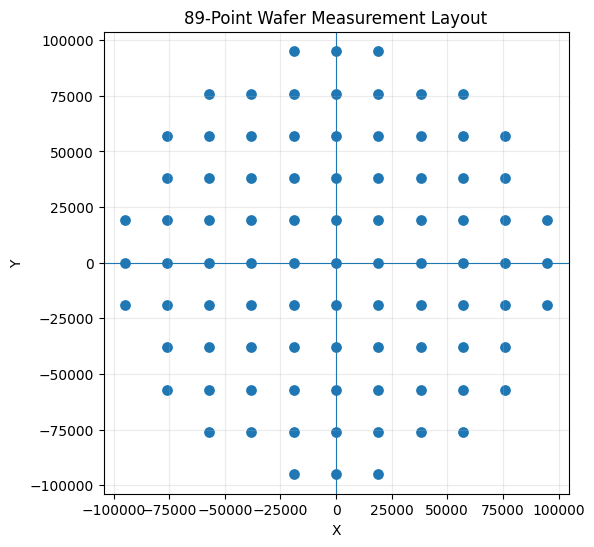

In [ ]:
# ============================================================
# Cell 19. Inspect 89-Point Spatial Measurement Layout
# ============================================================

# 첫 번째 Wafer의 89개 위치 사용
example_key = etch_89_df[
    "experiment_key"
].iloc[0]

spatial_layout_df = (
    etch_89_df[
        etch_89_df["experiment_key"] == example_key
    ][
        ["X", "Y"]
    ]
    .copy()
)


# ------------------------------------------------------------
# 1. Radius 계산
# ------------------------------------------------------------

spatial_layout_df["radius"] = np.sqrt(
    spatial_layout_df["X"] ** 2
    +
    spatial_layout_df["Y"] ** 2
)


max_radius = (
    spatial_layout_df["radius"].max()
)

spatial_layout_df[
    "normalized_radius"
] = (
    spatial_layout_df["radius"]
    / max_radius
)


print("=== Spatial Layout Summary ===")

print(
    "Number of positions:",
    len(spatial_layout_df)
)

print(
    "Max radius:",
    max_radius
)

print(
    "\nNormalized radius summary:"
)

display(
    spatial_layout_df[
        "normalized_radius"
    ].describe()
)


# ------------------------------------------------------------
# 2. Measurement Position 시각화
# ------------------------------------------------------------

plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    spatial_layout_df["X"],
    spatial_layout_df["Y"],
    s=45
)

plt.axhline(
    0,
    linewidth=0.8
)

plt.axvline(
    0,
    linewidth=0.8
)

plt.xlabel("X")
plt.ylabel("Y")

plt.title(
    "89-Point Wafer Measurement Layout"
)

plt.axis("equal")
plt.grid(alpha=0.25)

plt.show()

### Wafer Radial Zone 정의

89개의 Measurement Position을 Wafer 중심으로부터의 거리로 변환하고, 최대 반경으로 정규화하여 `normalized_radius`를 계산하였다.

Spatial Etch Profile을 비교하기 위해 Wafer를 동일한 반경 폭 기준으로 Center, Middle, Edge의 세 영역으로 구분하였다.

- Center: normalized radius ≤ 0.33
- Middle: 0.33 < normalized radius ≤ 0.67
- Edge: normalized radius > 0.67

본 구분은 실제 Fab의 공정 Spec이 아니라, 본 프로젝트에서 Wafer 내 반경 방향 Etch Profile을 정량적으로 비교하기 위해 정의한 분석 기준이다.

=== Measurement Points by Radial Zone ===


,n_points
radial_zone,
Center,9
Middle,28
Edge,52


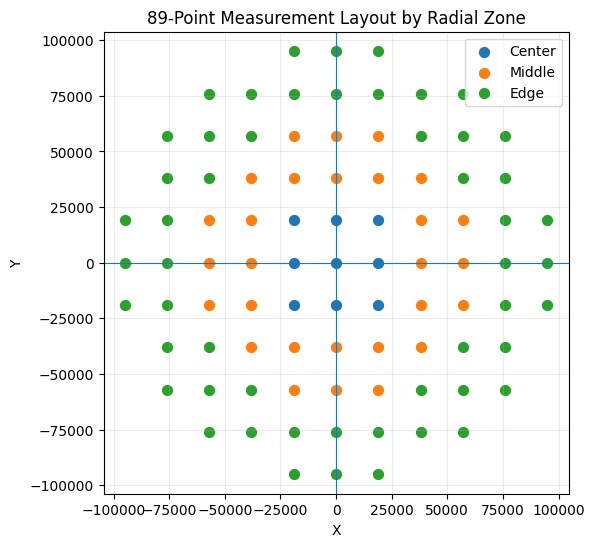

In [ ]:
# ============================================================
# Cell 20. Define Wafer Radial Zones
# ============================================================

spatial_layout_df = spatial_layout_df.copy()


def assign_radial_zone(r):

    if r <= 0.33:
        return "Center"

    elif r <= 0.67:
        return "Middle"

    else:
        return "Edge"


spatial_layout_df[
    "radial_zone"
] = (
    spatial_layout_df[
        "normalized_radius"
    ]
    .apply(assign_radial_zone)
)


print("=== Measurement Points by Radial Zone ===")

display(
    spatial_layout_df[
        "radial_zone"
    ]
    .value_counts()
    .reindex(
        [
            "Center",
            "Middle",
            "Edge"
        ]
    )
    .rename("n_points")
    .to_frame()
)


# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

plt.figure(
    figsize=(6, 6)
)

for zone in [
    "Center",
    "Middle",
    "Edge"
]:

    temp = spatial_layout_df[
        spatial_layout_df[
            "radial_zone"
        ] == zone
    ]

    plt.scatter(
        temp["X"],
        temp["Y"],
        s=50,
        label=zone
    )


plt.axhline(
    0,
    linewidth=0.8
)

plt.axvline(
    0,
    linewidth=0.8
)

plt.xlabel("X")
plt.ylabel("Y")

plt.title(
    "89-Point Measurement Layout by Radial Zone"
)

plt.axis("equal")
plt.grid(alpha=0.25)
plt.legend()

plt.show()

### Virtual Metrology Target 정의

각 Wafer의 89-point `si_etch` Measurement를 이용하여 Virtual Metrology Model의 Target을 생성한다.

주요 Target은 다음과 같다.

- `mean_si_etch`: Wafer 전체의 평균 Silicon Etch Depth
- `si_etch_nonuniformity_pct`: Wafer 내 위치별 Etch Depth 불균일도
- `center_mean_si_etch`: Center 영역 평균 Etch Depth
- `middle_mean_si_etch`: Middle 영역 평균 Etch Depth
- `edge_mean_si_etch`: Edge 영역 평균 Etch Depth
- `center_edge_difference`: Edge 평균과 Center 평균의 차이

Within-Wafer Non-uniformity는 다음과 같이 정의한다.

Non-uniformity (%) = (Maximum - Minimum) / (2 × Mean) × 100

값이 작을수록 Wafer 내 Etch Depth가 균일하며, 값이 클수록 위치별 Etch Depth 차이가 크다는 의미이다.

Center / Middle / Edge 구분은 실제 Fab 공정 Spec이 아니라 본 프로젝트의 Spatial Profile 분석을 위해 정의한 반경 기반 분석 기준이다.

In [ ]:
# ============================================================
# Cell 21. Build Wafer-Level Virtual Metrology Targets
# ============================================================

etch_target_df = etch_89_df.copy()


# ------------------------------------------------------------
# 1. 각 Measurement Point의 normalized radius 계산
# ------------------------------------------------------------

etch_target_df["radius"] = np.sqrt(
    etch_target_df["X"] ** 2
    +
    etch_target_df["Y"] ** 2
)


# 모든 Wafer가 동일한 89-point layout을 사용하므로
# 전체 Measurement Layout의 최대 반경 사용
global_max_radius = (
    etch_target_df["radius"].max()
)


etch_target_df[
    "normalized_radius"
] = (
    etch_target_df["radius"]
    / global_max_radius
)


# ------------------------------------------------------------
# 2. Radial Zone 지정
# ------------------------------------------------------------

def assign_radial_zone_target(r):

    if r <= 0.33:
        return "Center"

    elif r <= 0.67:
        return "Middle"

    else:
        return "Edge"


etch_target_df[
    "radial_zone"
] = (
    etch_target_df[
        "normalized_radius"
    ]
    .apply(
        assign_radial_zone_target
    )
)


# ------------------------------------------------------------
# 3. Wafer별 Target 계산
# ------------------------------------------------------------

target_records = []


for experiment_key, wafer_df in (
    etch_target_df
    .groupby("experiment_key")
):

    si_values = (
        wafer_df["si_etch"]
        .to_numpy()
    )

    mean_si_etch = (
        np.mean(si_values)
    )

    max_si_etch = (
        np.max(si_values)
    )

    min_si_etch = (
        np.min(si_values)
    )

    std_si_etch = (
        np.std(
            si_values,
            ddof=1
        )
    )


    # Within-Wafer Non-uniformity
    nonuniformity_pct = (
        (
            max_si_etch
            -
            min_si_etch
        )
        /
        (
            2
            *
            mean_si_etch
        )
        *
        100
    )


    # Radial zone 평균
    center_mean = (
        wafer_df.loc[
            wafer_df[
                "radial_zone"
            ] == "Center",
            "si_etch"
        ]
        .mean()
    )

    middle_mean = (
        wafer_df.loc[
            wafer_df[
                "radial_zone"
            ] == "Middle",
            "si_etch"
        ]
        .mean()
    )

    edge_mean = (
        wafer_df.loc[
            wafer_df[
                "radial_zone"
            ] == "Edge",
            "si_etch"
        ]
        .mean()
    )


    center_edge_difference = (
        edge_mean
        -
        center_mean
    )


    target_records.append({

        "experiment_key":
            experiment_key,

        "mean_si_etch":
            mean_si_etch,

        "std_si_etch":
            std_si_etch,

        "si_etch_nonuniformity_pct":
            nonuniformity_pct,

        "center_mean_si_etch":
            center_mean,

        "middle_mean_si_etch":
            middle_mean,

        "edge_mean_si_etch":
            edge_mean,

        "center_edge_difference":
            center_edge_difference
    })


wafer_target_df = pd.DataFrame(
    target_records
)


# ------------------------------------------------------------
# 4. Metadata와 연결
# ------------------------------------------------------------

wafer_target_df = (
    wafer_metadata_df
    .merge(
        wafer_target_df,
        on="experiment_key",
        how="inner"
    )
)


print(
    "=== Number of Wafer Targets ==="
)

print(
    len(wafer_target_df)
)


print(
    "\n=== First 10 Wafer Targets ==="
)

display(
    wafer_target_df[
        [
            "experiment_key",
            "lot_number",
            "conditioning_type",
            "wafer_sequence",
            "mean_si_etch",
            "si_etch_nonuniformity_pct",
            "center_mean_si_etch",
            "middle_mean_si_etch",
            "edge_mean_si_etch",
            "center_edge_difference"
        ]
    ].head(10)
)


print(
    "\n=== Target Summary ==="
)

display(
    wafer_target_df[
        [
            "mean_si_etch",
            "std_si_etch",
            "si_etch_nonuniformity_pct",
            "center_mean_si_etch",
            "middle_mean_si_etch",
            "edge_mean_si_etch",
            "center_edge_difference"
        ]
    ].describe()
)


print(
    "\n=== Missing Target Values ==="
)

display(
    wafer_target_df[
        [
            "mean_si_etch",
            "si_etch_nonuniformity_pct",
            "center_mean_si_etch",
            "middle_mean_si_etch",
            "edge_mean_si_etch",
            "center_edge_difference"
        ]
    ]
    .isna()
    .sum()
)

=== Number of Wafer Targets ===
88

=== First 10 Wafer Targets ===


,experiment_key,lot_number,conditioning_type,wafer_sequence,mean_si_etch,si_etch_nonuniformity_pct,center_mean_si_etch,middle_mean_si_etch,edge_mean_si_etch,center_edge_difference
0,2024-07-02_01,1,3C,1,44.288991,13.645265,42.135544,41.553807,46.134494,3.998950
1,2024-07-02_02,1,3C,2,44.038887,13.037341,41.891689,41.346629,45.860194,3.968505
2,2024-07-02_03,1,3C,3,44.149624,12.911435,42.052900,41.485607,45.946988,3.894088
3,2024-07-02_04,1,3C,4,43.905296,12.943769,41.799433,41.286429,45.679931,3.880497
4,2024-07-02_05,1,3C,5,43.426591,12.874831,41.431900,40.845379,45.161710,3.729810
5,2024-07-02_06,1,3C,6,43.584064,12.927890,41.596111,41.003475,45.317681,3.721570
6,2024-07-02_08,1,3C,8,43.096928,12.907765,41.153689,40.543907,44.807962,3.654273
7,2024-07-02_09,1,3C,9,43.339929,12.892153,41.400744,40.784150,45.051746,3.651002
8,2024-07-02_10,1,3C,10,43.284357,12.921527,41.353656,40.734482,44.991527,3.637871
9,2024-07-05_01,2,1C,1,44.208571,13.839059,42.007411,41.401968,46.100788,4.093377



=== Target Summary ===


,mean_si_etch,std_si_etch,si_etch_nonuniformity_pct,center_mean_si_etch,middle_mean_si_etch,edge_mean_si_etch,center_edge_difference
count,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000
mean,43.668120,3.606451,13.423386,41.587542,40.997057,45.466485,3.878942
std,0.401909,0.100741,1.379098,0.319264,0.338702,0.455033,0.168723
min,42.942928,3.426337,12.848243,40.920756,40.309468,44.631885,3.518396
25%,43.349077,3.534867,13.127197,41.346253,40.733283,45.110308,3.763670
50%,43.667601,3.590580,13.266382,41.562156,40.981657,45.472119,3.889840
75%,43.983902,3.681063,13.371125,41.853214,41.292421,45.833035,3.997218
max,44.376304,3.866935,25.944377,42.142489,41.567257,46.294531,4.253715



=== Missing Target Values ===


,0
mean_si_etch,0
si_etch_nonuniformity_pct,0
center_mean_si_etch,0
middle_mean_si_etch,0
edge_mean_si_etch,0
center_edge_difference,0


### Wafer-Level Target 생성 결과

Process Data와 89-point Measurement가 모두 존재하는 88개 Wafer에 대해 Virtual Metrology Target을 생성하였으며, 모든 Target에서 Missing Value는 확인되지 않았다.

전체 Wafer에서는 Edge 영역의 평균 Si Etch Depth가 Center 영역보다 높은 경향이 관찰되었다.

또한 대부분의 Wafer에서 Si Etch Non-uniformity가 유사한 범위에 분포하였으나 일부 Wafer에서는 상대적으로 큰 값이 나타나므로, 모델링 이전에 Lot 및 Wafer Sequence에 따른 Target 변화와 비전형적인 Wafer를 추가적으로 확인한다.

=== Target Summary by Lot ===


,lot_number,conditioning_type,n_wafers,mean_si_etch,std_mean_si_etch,mean_nonuniformity,mean_center_edge_difference
0,1,3C,9,43.679407,0.426694,13.006886,3.792952
1,2,1C,10,43.530817,0.447045,13.018111,3.699088
2,3,9C,10,43.761885,0.396955,13.444174,3.938674
3,4,3C - Si,10,43.728478,0.531264,13.313722,3.933884
4,5,1C - Si,10,43.481078,0.384282,13.260335,3.784200
5,6,9C - Si,10,43.557539,0.416424,14.597482,3.848771
6,7,3C - SiO2,6,43.719150,0.252128,13.354865,3.923483
7,8,3C - SiO2,10,43.613837,0.209403,13.401349,3.943429
8,9,3C,9,43.807341,0.417478,13.396508,4.005451
9,10,3C - SiO2,4,44.090644,0.202757,13.286625,4.034984


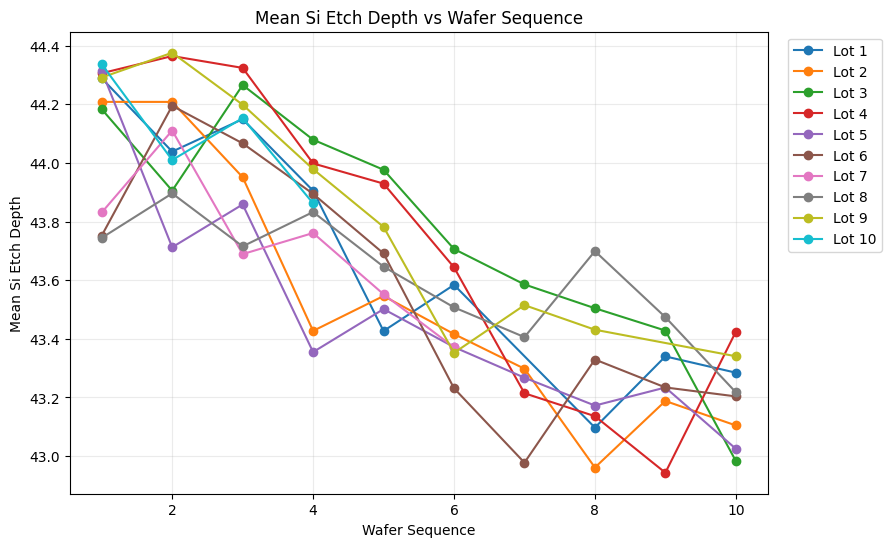

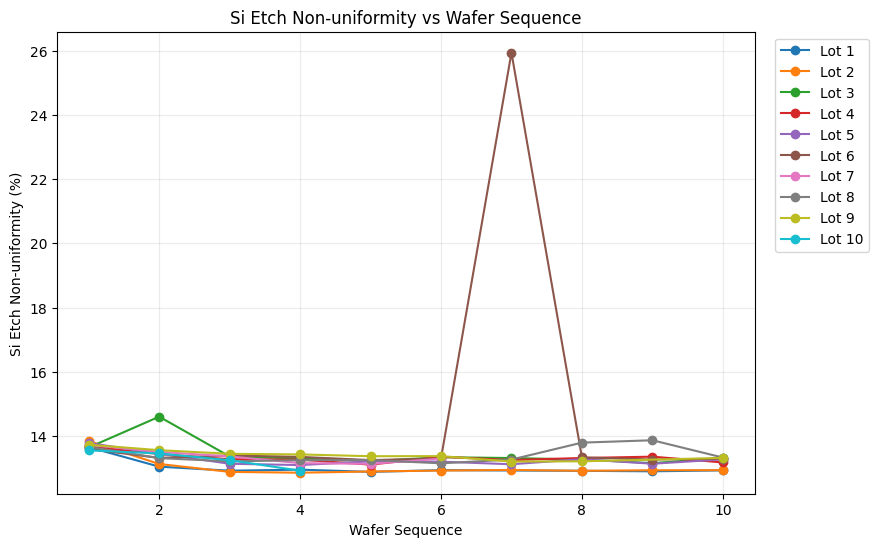

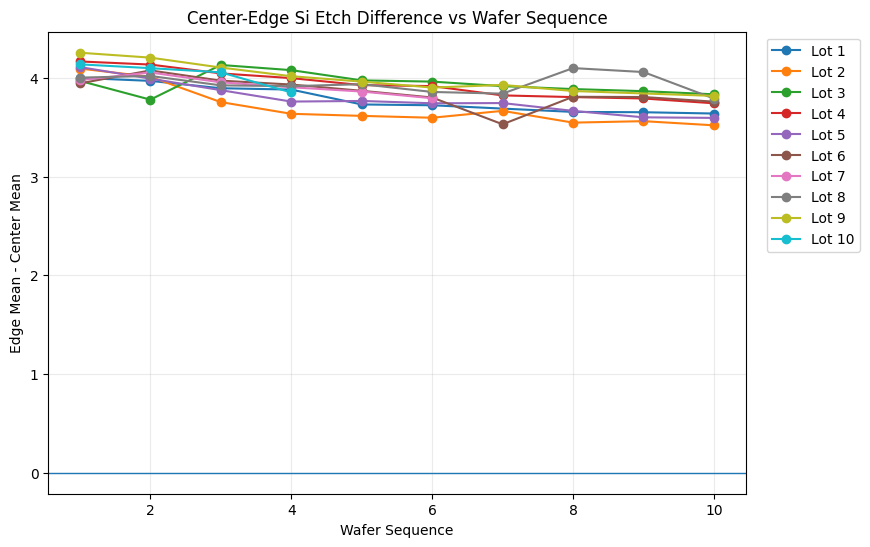


=== Highest Non-uniformity Wafers ===


,experiment_key,lot_number,conditioning_type,wafer_sequence,mean_si_etch,si_etch_nonuniformity_pct,center_edge_difference
55,2024-08-01_07,6,9C - Si,7,42.977328,25.944377,3.528996
20,2024-07-09_02,3,9C,2,43.905554,14.596103,3.778373
73,2024-08-07_09,8,3C - SiO2,9,43.473815,13.860757,4.058075
9,2024-07-05_01,2,1C,1,44.208571,13.839059,4.093377
72,2024-08-07_08,8,3C - SiO2,8,43.699084,13.786445,4.098048
39,2024-07-19_01,5,1C - Si,1,44.314201,13.775381,4.108568
75,2024-08-21_01,9,3C,1,44.291687,13.721424,4.253715
59,2024-08-05_01,7,3C - SiO2,1,43.831115,13.715371,3.976047
29,2024-07-11_01,4,3C - Si,1,44.306305,13.666339,4.165230
65,2024-08-07_01,8,3C - SiO2,1,43.744463,13.656014,4.001504


In [ ]:
# ============================================================
# Cell 22. Analyze Target Trends by Lot and Wafer Sequence
# ============================================================

# ------------------------------------------------------------
# 1. Target을 Lot / Sequence 순으로 정렬
# ------------------------------------------------------------

target_analysis_df = (
    wafer_target_df
    .sort_values(
        [
            "lot_number",
            "wafer_sequence"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Lot별 Target Summary
# ------------------------------------------------------------

lot_target_summary_df = (
    target_analysis_df
    .groupby(
        [
            "lot_number",
            "conditioning_type"
        ]
    )
    .agg(
        n_wafers=(
            "experiment_key",
            "count"
        ),

        mean_si_etch=(
            "mean_si_etch",
            "mean"
        ),

        std_mean_si_etch=(
            "mean_si_etch",
            "std"
        ),

        mean_nonuniformity=(
            "si_etch_nonuniformity_pct",
            "mean"
        ),

        mean_center_edge_difference=(
            "center_edge_difference",
            "mean"
        )
    )
    .reset_index()
)


print("=== Target Summary by Lot ===")

display(
    lot_target_summary_df
)


# ------------------------------------------------------------
# 3. Mean Si Etch Depth vs Wafer Sequence
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for lot_number, lot_df in (
    target_analysis_df
    .groupby("lot_number")
):

    plt.plot(
        lot_df["wafer_sequence"],
        lot_df["mean_si_etch"],
        marker="o",
        label=f"Lot {lot_number}"
    )


plt.xlabel("Wafer Sequence")
plt.ylabel("Mean Si Etch Depth")

plt.title(
    "Mean Si Etch Depth vs Wafer Sequence"
)

plt.grid(alpha=0.25)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.show()


# ------------------------------------------------------------
# 4. Non-uniformity vs Wafer Sequence
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for lot_number, lot_df in (
    target_analysis_df
    .groupby("lot_number")
):

    plt.plot(
        lot_df["wafer_sequence"],
        lot_df[
            "si_etch_nonuniformity_pct"
        ],
        marker="o",
        label=f"Lot {lot_number}"
    )


plt.xlabel("Wafer Sequence")
plt.ylabel("Si Etch Non-uniformity (%)")

plt.title(
    "Si Etch Non-uniformity vs Wafer Sequence"
)

plt.grid(alpha=0.25)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.show()


# ------------------------------------------------------------
# 5. Center-Edge Difference vs Wafer Sequence
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for lot_number, lot_df in (
    target_analysis_df
    .groupby("lot_number")
):

    plt.plot(
        lot_df["wafer_sequence"],
        lot_df[
            "center_edge_difference"
        ],
        marker="o",
        label=f"Lot {lot_number}"
    )


plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Wafer Sequence")
plt.ylabel(
    "Edge Mean - Center Mean"
)

plt.title(
    "Center-Edge Si Etch Difference vs Wafer Sequence"
)

plt.grid(alpha=0.25)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.show()


# ------------------------------------------------------------
# 6. Non-uniformity가 큰 Wafer 확인
# ------------------------------------------------------------

print(
    "\n=== Highest Non-uniformity Wafers ==="
)

display(
    target_analysis_df[
        [
            "experiment_key",
            "lot_number",
            "conditioning_type",
            "wafer_sequence",
            "mean_si_etch",
            "si_etch_nonuniformity_pct",
            "center_edge_difference"
        ]
    ]
    .sort_values(
        "si_etch_nonuniformity_pct",
        ascending=False
    )
    .head(10)
)

### 초기 Etch Target Trend 분석

Wafer Sequence에 따른 Etch 결과를 확인한 결과, 다수의 Lot에서 Wafer 처리 순서가 증가할수록 Mean Si Etch Depth가 감소하는 경향이 관찰되었다.

이는 동일한 Conditioning 이후 Wafer를 연속적으로 처리하는 동안 Process 또는 Chamber State가 변화할 가능성을 시사한다. 단, 현 단계에서는 Etch 결과의 변화만 확인한 것이므로 Chamber Drift를 원인으로 확정하지 않고, 이후 Process Signal 변화와 함께 검토한다.

또한 모든 Wafer에서 Edge 영역의 평균 Si Etch Depth가 Center보다 높았으며, 일부 Lot에서는 Wafer Sequence 증가에 따라 Center–Edge Difference가 감소하는 경향이 나타났다.

한편 Lot 6의 Wafer #7에서는 Si Etch Non-uniformity가 약 25.94%로 다른 Wafer보다 매우 높게 나타났다. Max–Min 기반 Non-uniformity Metric은 특정 Measurement Point의 극단값에 민감하므로, 해당 Wafer의 89-point Spatial Profile을 별도로 확인한다.

=== Selected Wafer ===
2024-08-01_07

=== Si Etch Summary ===


,si_etch
count,89.000000
mean,42.977328
std,3.866935
min,28.653000
25%,40.651400
50%,41.491600
75%,44.338500
max,50.953400



=== Minimum Si Etch Point ===


,4914
X,-76000
Y,-38000
radial_zone,Edge
si_etch,28.653



=== Maximum Si Etch Point ===


,4897
X,19000
Y,-95000
radial_zone,Edge
si_etch,50.9534


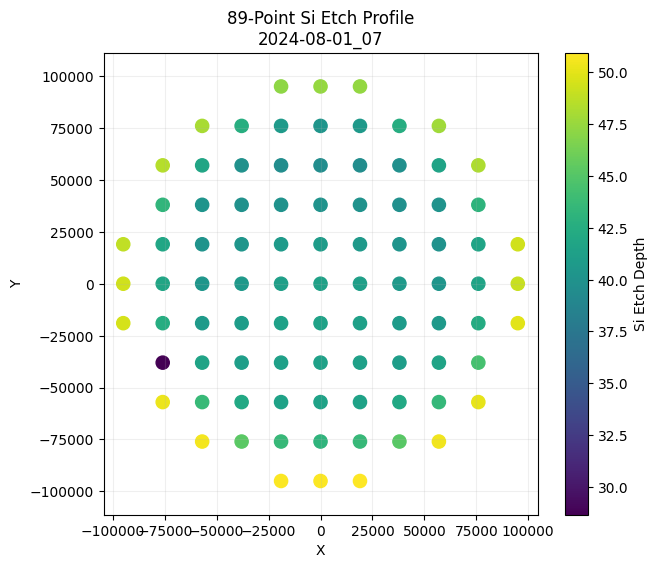


=== Lowest 10 Si Etch Points ===


,X,Y,radial_zone,si_etch
4914,-76000,-38000,Edge,28.6530
4969,0,57000,Middle,39.5020
4970,19000,57000,Middle,39.5108
4968,-19000,57000,Middle,39.5298
4962,38000,38000,Middle,39.7406
4971,38000,57000,Edge,39.7993
4958,-38000,38000,Middle,39.8086
4967,-38000,57000,Edge,39.8703
4961,19000,38000,Middle,39.9490
4959,-19000,38000,Middle,39.9706



=== Highest 10 Si Etch Points ===


,X,Y,radial_zone,si_etch
4897,19000,-95000,Edge,50.9534
4895,-19000,-95000,Edge,50.8556
4896,0,-95000,Edge,50.7826
4898,-57000,-76000,Edge,50.5937
4904,57000,-76000,Edge,50.4559
4905,-76000,-57000,Edge,50.2877
4913,76000,-57000,Edge,50.1102
4933,95000,-19000,Edge,49.9881
4923,-95000,-19000,Edge,49.5011
4955,95000,19000,Edge,49.3648


In [ ]:
# ============================================================
# Cell 23. Inspect High Non-uniformity Wafer
# ============================================================

outlier_key = "2024-08-01_07"


outlier_wafer_df = (
    etch_target_df[
        etch_target_df[
            "experiment_key"
        ] == outlier_key
    ]
    .copy()
)


print("=== Selected Wafer ===")
print(outlier_key)

print("\n=== Si Etch Summary ===")

display(
    outlier_wafer_df[
        "si_etch"
    ].describe()
)


# ------------------------------------------------------------
# Minimum / Maximum Point
# ------------------------------------------------------------

min_row = (
    outlier_wafer_df
    .loc[
        outlier_wafer_df[
            "si_etch"
        ].idxmin()
    ]
)

max_row = (
    outlier_wafer_df
    .loc[
        outlier_wafer_df[
            "si_etch"
        ].idxmax()
    ]
)


print("\n=== Minimum Si Etch Point ===")
display(
    min_row[
        [
            "X",
            "Y",
            "radial_zone",
            "si_etch"
        ]
    ]
)


print("\n=== Maximum Si Etch Point ===")
display(
    max_row[
        [
            "X",
            "Y",
            "radial_zone",
            "si_etch"
        ]
    ]
)


# ------------------------------------------------------------
# Spatial Etch Map
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)

scatter = plt.scatter(
    outlier_wafer_df["X"],
    outlier_wafer_df["Y"],
    c=outlier_wafer_df["si_etch"],
    s=90
)

plt.colorbar(
    scatter,
    label="Si Etch Depth"
)

plt.xlabel("X")
plt.ylabel("Y")

plt.title(
    f"89-Point Si Etch Profile\n{outlier_key}"
)

plt.axis("equal")
plt.grid(alpha=0.2)

plt.show()


# ------------------------------------------------------------
# Extreme Points 확인
# ------------------------------------------------------------

print(
    "\n=== Lowest 10 Si Etch Points ==="
)

display(
    outlier_wafer_df[
        [
            "X",
            "Y",
            "radial_zone",
            "si_etch"
        ]
    ]
    .sort_values(
        "si_etch"
    )
    .head(10)
)


print(
    "\n=== Highest 10 Si Etch Points ==="
)

display(
    outlier_wafer_df[
        [
            "X",
            "Y",
            "radial_zone",
            "si_etch"
        ]
    ]
    .sort_values(
        "si_etch",
        ascending=False
    )
    .head(10)
)

### High Non-uniformity Wafer 검토

Lot 6의 Wafer #7(`2024-08-01_07`)은 Si Etch Non-uniformity가 25.94%로 다른 Wafer보다 크게 나타났다.

89-point Spatial Profile을 확인한 결과 대부분의 Measurement Point는 다른 Wafer와 유사한 범위에 분포하지만, `(X, Y) = (-76000, -38000)` 위치에서 `si_etch = 28.653`의 매우 낮은 값이 단독으로 관찰되었다.

따라서 높은 Non-uniformity가 Wafer 전체의 실제 Spatial Variation 때문인지, 특정 Measurement Point의 이상값 때문인지 판단하기 위해 해당 위치의 원본 Measurement와 다른 Wafer의 동일 위치 값을 추가적으로 비교한다.

In [ ]:
# ============================================================
# Cell 24. Validate Suspicious Measurement Point
# ============================================================

outlier_key = "2024-08-01_07"

outlier_wafer_df = (
    etch_target_df[
        etch_target_df["experiment_key"] == outlier_key
    ]
    .copy()
)


# ------------------------------------------------------------
# 1. 가장 낮은 Si Etch Point
# ------------------------------------------------------------

candidate_idx = (
    outlier_wafer_df["si_etch"]
    .idxmin()
)

candidate_row = (
    outlier_wafer_df.loc[
        candidate_idx
    ]
)


candidate_x = candidate_row["X"]
candidate_y = candidate_row["Y"]


print("=== Suspicious Measurement Point ===")

display(
    candidate_row[
        [
            "experiment_key",
            "X",
            "Y",
            "preox_thickness",
            "postox_thickness",
            "stepheight",
            "oxide_etch",
            "si_etch",
            "radial_zone"
        ]
    ]
)


# ------------------------------------------------------------
# 2. 동일 Wafer의 주변 Measurement Point
# ------------------------------------------------------------

neighbor_df = (
    outlier_wafer_df
    .copy()
)

neighbor_df["distance_from_candidate"] = np.sqrt(
    (neighbor_df["X"] - candidate_x) ** 2
    +
    (neighbor_df["Y"] - candidate_y) ** 2
)


print("\n=== Nearest Spatial Neighbors ===")

display(
    neighbor_df[
        [
            "X",
            "Y",
            "distance_from_candidate",
            "stepheight",
            "postox_thickness",
            "si_etch"
        ]
    ]
    .sort_values(
        "distance_from_candidate"
    )
    .head(9)
)


# ------------------------------------------------------------
# 3. 다른 Wafer의 동일 X/Y 위치와 비교
# ------------------------------------------------------------

same_position_df = (
    etch_target_df[
        (etch_target_df["X"] == candidate_x)
        &
        (etch_target_df["Y"] == candidate_y)
    ][
        [
            "experiment_key",
            "lot_number",
            "wafer_number",
            "preox_thickness",
            "postox_thickness",
            "stepheight",
            "si_etch"
        ]
    ]
    .copy()
)


print("\n=== Same Position Across All Wafers ===")

display(
    same_position_df[
        "si_etch"
    ].describe()
)


print("\n=== Lowest Values at Same Position ===")

display(
    same_position_df
    .sort_values(
        "si_etch"
    )
    .head(10)
)


# ------------------------------------------------------------
# 4. 해당 한 Point 제외 시 Non-uniformity 재계산
# ------------------------------------------------------------

original_values = (
    outlier_wafer_df["si_etch"]
    .to_numpy()
)

without_candidate_values = (
    outlier_wafer_df
    .drop(
        index=candidate_idx
    )["si_etch"]
    .to_numpy()
)


def calculate_nonuniformity(values):

    return (
        (
            np.max(values)
            -
            np.min(values)
        )
        /
        (
            2
            *
            np.mean(values)
        )
        *
        100
    )


original_nonuniformity = (
    calculate_nonuniformity(
        original_values
    )
)

without_candidate_nonuniformity = (
    calculate_nonuniformity(
        without_candidate_values
    )
)


print("\n=== Non-uniformity Sensitivity Check ===")

print(
    f"Original 89-point Non-uniformity : "
    f"{original_nonuniformity:.4f}%"
)

print(
    f"Without suspicious point         : "
    f"{without_candidate_nonuniformity:.4f}%"
)

print(
    f"Difference                       : "
    f"{original_nonuniformity - without_candidate_nonuniformity:.4f}%p"
)

=== Suspicious Measurement Point ===


,4914
experiment_key,2024-08-01_07
X,-76000
Y,-38000
preox_thickness,1.002403
postox_thickness,0.2925
stepheight,28.9455
oxide_etch,0.709903
si_etch,28.653
radial_zone,Edge



=== Nearest Spatial Neighbors ===


,X,Y,distance_from_candidate,stepheight,postox_thickness,si_etch
4914,-76000,-38000,0.000000,28.9455,0.2925,28.6530
4905,-76000,-57000,19000.000000,50.6281,0.3404,50.2877
4915,-57000,-38000,19000.000000,41.8374,0.2060,41.6314
4924,-76000,-19000,19000.000000,42.6878,0.2681,42.4197
4923,-95000,-19000,26870.057685,49.8076,0.3065,49.5011
4906,-57000,-57000,26870.057685,43.9242,0.2845,43.6397
4925,-57000,-19000,26870.057685,41.1054,0.3961,40.7093
4916,-38000,-38000,38000.000000,41.4344,0.3863,41.0481
4935,-76000,0,38000.000000,41.9745,0.2081,41.7664



=== Same Position Across All Wafers ===


,si_etch
count,88.00000
mean,44.88950
std,1.80939
min,28.65300
25%,44.69525
50%,45.11800
75%,45.47100
max,45.95350



=== Lowest Values at Same Position ===


,experiment_key,lot_number,wafer_number,preox_thickness,postox_thickness,stepheight,si_etch
4914,2024-08-01_07,6,7,1.002403,0.2925,28.9455,28.6530
1443,2024-07-05_08,2,8,0.995151,0.4921,44.7098,44.2177
3312,2024-07-11_09,4,9,0.999978,0.2936,44.5207,44.2271
2511,2024-07-09_10,3,10,1.002673,0.3051,44.5836,44.2785
4291,2024-07-19_10,5,10,1.007605,0.2979,44.6382,44.3403
1621,2024-07-05_10,2,10,0.994532,0.4910,44.8406,44.3496
1532,2024-07-05_09,2,9,0.995229,0.4906,44.9179,44.4273
3223,2024-07-11_08,4,8,1.000978,0.2927,44.7235,44.4308
553,2024-07-02_08,1,8,0.996748,0.4920,44.9918,44.4998
4113,2024-07-19_08,5,8,1.005642,0.2958,44.8091,44.5133



=== Non-uniformity Sensitivity Check ===
Original 89-point Non-uniformity : 25.9444%
Without suspicious point         : 13.2723%
Difference                       : 12.6720%p


### Measurement Anomaly Candidate 검토

`2024-08-01_07` Wafer의 `(X, Y) = (-76000, -38000)` 위치에서 `si_etch = 28.653`의 비정상적으로 낮은 값이 단독으로 관찰되었다.

동일 위치의 다른 Wafer들은 대부분 약 44~46 수준의 Si Etch Depth를 나타냈으며, 해당 Wafer의 인접 측정점 역시 일반적인 범위에 분포하였다.

또한 해당 한 Point를 제외하면 Max–Min 기반 Non-uniformity가 25.94%에서 13.27%로 감소하여 다른 Wafer들과 유사한 수준이 되었다.

따라서 해당 Point를 확정적인 Measurement Error로 삭제하지 않고 `Measurement Anomaly Candidate`로 유지한다. 다만 단일 극단값에 민감한 Max–Min 기반 Non-uniformity의 한계를 고려하여, Virtual Metrology Modeling에서는 Percentile 기반 Robust Non-uniformity를 추가적으로 사용한다.

In [ ]:
# ============================================================
# Cell 25. Add Robust Si Etch Non-uniformity Target
# ============================================================

robust_target_records = []


for experiment_key, wafer_df in (
    etch_target_df.groupby("experiment_key")
):

    values = (
        wafer_df["si_etch"]
        .to_numpy()
    )

    mean_value = np.mean(values)

    p05 = np.percentile(
        values,
        5
    )

    p95 = np.percentile(
        values,
        95
    )

    robust_nonuniformity = (
        (p95 - p05)
        /
        (2 * mean_value)
        *
        100
    )

    robust_target_records.append({

        "experiment_key":
            experiment_key,

        "si_etch_robust_nonuniformity_pct":
            robust_nonuniformity
    })


robust_target_df = pd.DataFrame(
    robust_target_records
)


wafer_target_df = (
    wafer_target_df
    .merge(
        robust_target_df,
        on="experiment_key",
        how="left"
    )
)


print(
    "=== Robust Non-uniformity Summary ==="
)

display(
    wafer_target_df[
        [
            "si_etch_nonuniformity_pct",
            "si_etch_robust_nonuniformity_pct"
        ]
    ].describe()
)


print(
    "\n=== Highest Robust Non-uniformity Wafers ==="
)

display(
    wafer_target_df[
        [
            "experiment_key",
            "lot_number",
            "conditioning_type",
            "wafer_sequence",
            "si_etch_nonuniformity_pct",
            "si_etch_robust_nonuniformity_pct"
        ]
    ]
    .sort_values(
        "si_etch_robust_nonuniformity_pct",
        ascending=False
    )
    .head(10)
)


print(
    "\n=== Suspicious Wafer Comparison ==="
)

display(
    wafer_target_df[
        wafer_target_df[
            "experiment_key"
        ] == "2024-08-01_07"
    ][
        [
            "experiment_key",
            "si_etch_nonuniformity_pct",
            "si_etch_robust_nonuniformity_pct"
        ]
    ]
)

=== Robust Non-uniformity Summary ===


,si_etch_nonuniformity_pct,si_etch_robust_nonuniformity_pct
count,88.000000,88.000000
mean,13.423386,12.231338
std,1.379098,0.154627
min,12.848243,11.822221
25%,13.127197,12.148229
50%,13.266382,12.245595
75%,13.371125,12.312440
max,25.944377,12.647954



=== Highest Robust Non-uniformity Wafers ===


,experiment_key,lot_number,conditioning_type,wafer_sequence,si_etch_nonuniformity_pct,si_etch_robust_nonuniformity_pct
72,2024-08-07_08,8,3C - SiO2,8,13.786445,12.647954
73,2024-08-07_09,8,3C - SiO2,9,13.860757,12.628291
9,2024-07-05_01,2,1C,1,13.839059,12.580456
39,2024-07-19_01,5,1C - Si,1,13.775381,12.457835
84,2024-08-22_01,10,3C - SiO2,1,13.547233,12.446123
65,2024-08-07_01,8,3C - SiO2,1,13.656014,12.432042
29,2024-07-11_01,4,3C - Si,1,13.666339,12.425929
76,2024-08-21_02,9,3C,2,13.551151,12.417505
75,2024-08-21_01,9,3C,1,13.721424,12.403163
59,2024-08-05_01,7,3C - SiO2,1,13.715371,12.396057



=== Suspicious Wafer Comparison ===


,experiment_key,si_etch_nonuniformity_pct,si_etch_robust_nonuniformity_pct
55,2024-08-01_07,25.944377,12.360633


### Robust Non-uniformity Target

단일 Measurement Point의 극단값에 대한 민감도를 줄이기 위해 5th–95th Percentile 기반의 Robust Non-uniformity를 추가하였다.

Robust Non-uniformity (%) = (P95 - P05) / (2 × Mean) × 100

기존 Max–Min 기반 Non-uniformity에서는 `2024-08-01_07` Wafer가 25.94%로 크게 나타났으나, Robust Metric에서는 12.36%로 일반적인 Wafer 범위에 포함되었다.

따라서 원본 Max–Min Non-uniformity는 Measurement Quality 확인을 위한 보조 지표로 유지하고, Virtual Metrology의 주요 Uniformity Target으로는 `si_etch_robust_nonuniformity_pct`를 사용한다.

=== Representative Wafer ===
Day_2024_07_02_Wafer_01
Duration: 691.48 sec


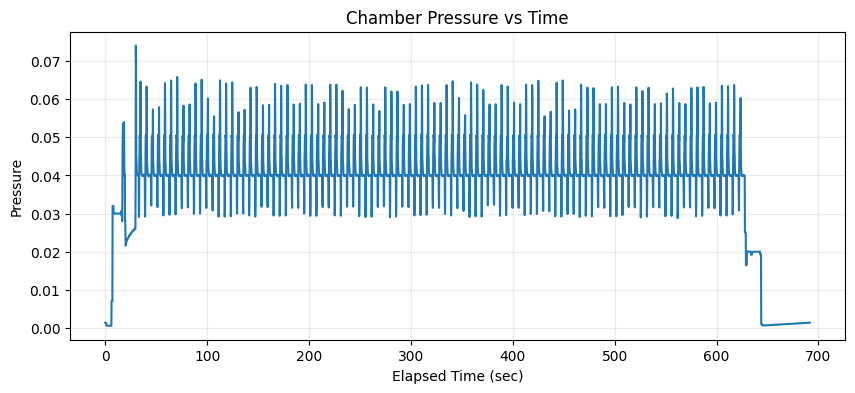

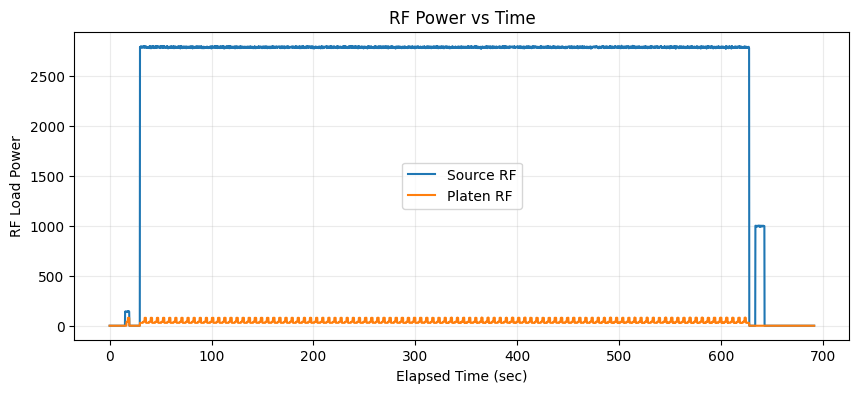

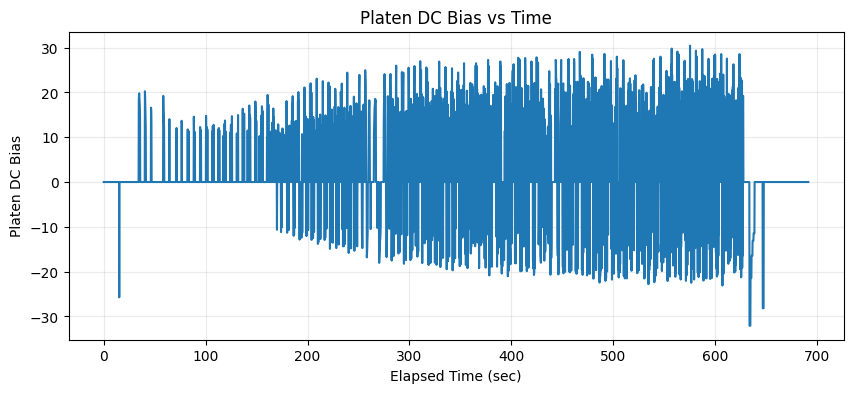

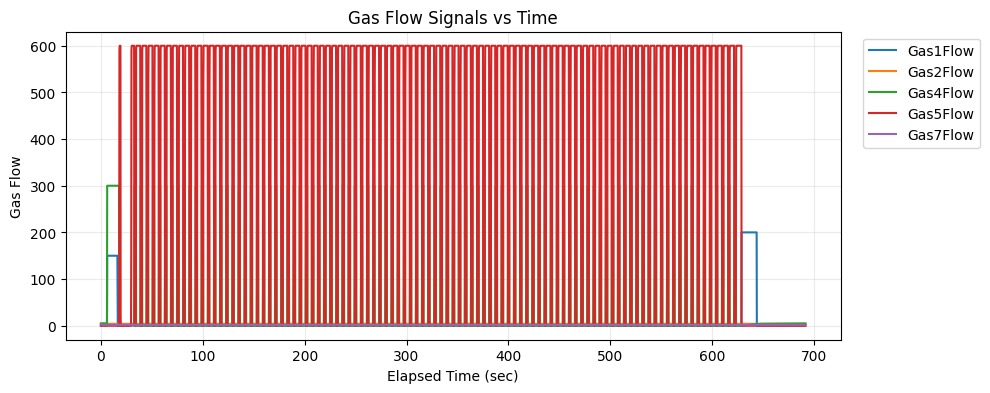

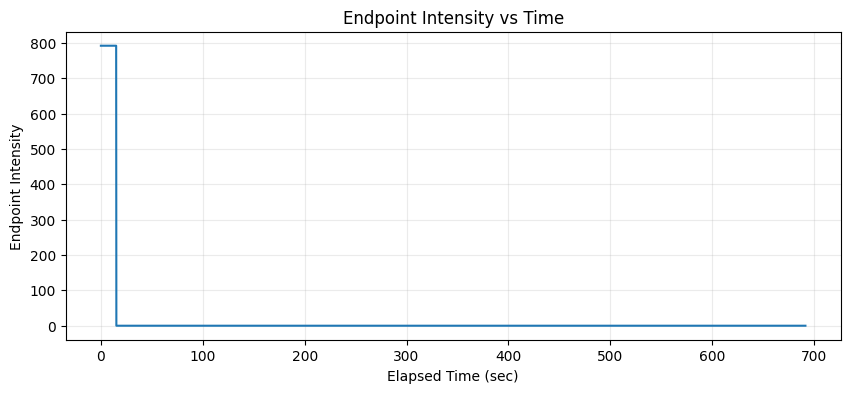

In [ ]:
# ============================================================
# Cell 26. Visualize Representative Process Time-series
# ============================================================

representative_wafer = (
    wafer_metadata_df[
        "wafer_name"
    ].iloc[0]
)


with h5py.File(process_file, "r") as f:

    grp = f[
        representative_wafer
    ]

    # Encoded process values
    encoded_data = (
        grp["data"][:]
    )

    # Decode
    decoded_data = (
        process_decoder[
            encoded_data
        ]
    )

    # Feature names
    raw_names = (
        grp["feature"][:]
    )

    feature_names = [
        x.decode("utf-8")
        if isinstance(x, bytes)
        else str(x)
        for x in raw_names
    ]

    # Actual relative time
    raw_times = (
        grp["times"][:]
    )


elapsed_time = (
    raw_times
    -
    raw_times[0]
)


process_time_df = pd.DataFrame(
    decoded_data,
    columns=feature_names
)

process_time_df[
    "elapsed_sec"
] = elapsed_time


print(
    "=== Representative Wafer ==="
)

print(
    representative_wafer
)

print(
    f"Duration: "
    f"{elapsed_time[-1]:.2f} sec"
)


# ------------------------------------------------------------
# 1. Pressure
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    elapsed_time,
    process_time_df[
        "Stat3_Etch_MV_Pressure"
    ]
)

plt.xlabel("Elapsed Time (sec)")
plt.ylabel("Pressure")

plt.title(
    "Chamber Pressure vs Time"
)

plt.grid(alpha=0.25)

plt.show()


# ------------------------------------------------------------
# 2. Source / Platen RF Power
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    elapsed_time,
    process_time_df[
        "Stat3_Etch_MV_SourceRFLoadPower"
    ],
    label="Source RF"
)

plt.plot(
    elapsed_time,
    process_time_df[
        "Stat3_Etch_MV_PlatenRFLoadPower"
    ],
    label="Platen RF"
)

plt.xlabel("Elapsed Time (sec)")
plt.ylabel("RF Load Power")

plt.title(
    "RF Power vs Time"
)

plt.grid(alpha=0.25)
plt.legend()

plt.show()


# ------------------------------------------------------------
# 3. Platen DC Bias
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    elapsed_time,
    process_time_df[
        "Stat3_Etch_MV_PlatenDcBias"
    ]
)

plt.xlabel("Elapsed Time (sec)")
plt.ylabel("Platen DC Bias")

plt.title(
    "Platen DC Bias vs Time"
)

plt.grid(alpha=0.25)

plt.show()


# ------------------------------------------------------------
# 4. Main Gas Flow Signals
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 4)
)

for gas_name in [
    "Stat3_Etch_MV_Gas1Flow",
    "Stat3_Etch_MV_Gas2Flow",
    "Stat3_Etch_MV_Gas4Flow",
    "Stat3_Etch_MV_Gas5Flow",
    "Stat3_Etch_MV_Gas7Flow"
]:

    if gas_name in process_time_df.columns:

        plt.plot(
            elapsed_time,
            process_time_df[
                gas_name
            ],
            label=gas_name.replace(
                "Stat3_Etch_MV_",
                ""
            )
        )


plt.xlabel("Elapsed Time (sec)")
plt.ylabel("Gas Flow")

plt.title(
    "Gas Flow Signals vs Time"
)

plt.grid(alpha=0.25)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.show()


# ------------------------------------------------------------
# 5. Endpoint Intensity
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    elapsed_time,
    process_time_df[
        "Stat3_Etch_MV_EpdIntensity"
    ]
)

plt.xlabel("Elapsed Time (sec)")
plt.ylabel("Endpoint Intensity")

plt.title(
    "Endpoint Intensity vs Time"
)

plt.grid(alpha=0.25)

plt.show()

### Main Etch Active Window 확인

대표 Wafer의 Process Time-series를 확인한 결과, 초기 준비 구간 이후 Source RF가 활성화되면서 Pressure, Platen RF, DC Bias 및 Gas Flow에서 반복적인 Process Cycle이 나타났다.

특히 Main Etch 구간에서는 Pressure와 Gas Flow, Bias 관련 Signal이 주기적으로 변화하며, 이는 BOSCH Etch의 반복적인 Process 특성을 반영하는 것으로 해석할 수 있다.

따라서 전체 공정 시간을 단순 평균하지 않고, 각 Wafer에서 Source RF가 충분히 활성화된 구간을 Main Etch Active Window로 정의한 뒤 해당 구간을 중심으로 Process Feature를 추출한다.

공정 시간은 Wafer마다 다를 수 있으므로 고정된 시간 범위를 사용하지 않고 각 Wafer의 Source RF Signal을 기준으로 Active Window를 자동으로 탐지한다.

In [ ]:
# ============================================================
# Cell 27. Detect Main Etch Active Window
# ============================================================

SOURCE_RF_FEATURE = (
    "Stat3_Etch_MV_SourceRFLoadPower"
)


active_window_records = []


with h5py.File(process_file, "r") as f:

    for _, row in wafer_metadata_df.iterrows():

        wafer_name = row["wafer_name"]

        grp = f[wafer_name]

        # ----------------------------------------------------
        # Decode Process Data
        # ----------------------------------------------------

        encoded_data = grp["data"][:]

        decoded_data = np.asarray(
            process_decoder[
                encoded_data
            ]
        )


        # Feature names
        raw_names = grp["feature"][:]

        feature_names = [
            x.decode("utf-8")
            if isinstance(x, bytes)
            else str(x)
            for x in raw_names
        ]


        # Time
        raw_times = grp["times"][:]

        elapsed_time = (
            raw_times
            -
            raw_times[0]
        )


        # ----------------------------------------------------
        # Source RF 찾기
        # ----------------------------------------------------

        source_rf_idx = (
            feature_names.index(
                SOURCE_RF_FEATURE
            )
        )

        source_rf = (
            decoded_data[
                :,
                source_rf_idx
            ]
        )


        # ----------------------------------------------------
        # Main Etch Active Window
        #
        # Source RF 최대값의 50% 이상인 구간
        # ----------------------------------------------------

        rf_threshold = (
            0.50
            *
            np.max(source_rf)
        )


        active_mask = (
            source_rf
            >= rf_threshold
        )


        active_indices = np.where(
            active_mask
        )[0]


        if len(active_indices) == 0:

            active_start = np.nan
            active_end = np.nan
            active_duration = np.nan
            active_samples = 0

        else:

            first_idx = (
                active_indices[0]
            )

            last_idx = (
                active_indices[-1]
            )


            active_start = (
                elapsed_time[
                    first_idx
                ]
            )

            active_end = (
                elapsed_time[
                    last_idx
                ]
            )

            active_duration = (
                active_end
                -
                active_start
            )

            active_samples = (
                len(active_indices)
            )


        active_window_records.append({

            "wafer_name":
                wafer_name,

            "experiment_key":
                row[
                    "experiment_key"
                ],

            "lot_number":
                row[
                    "lot_number"
                ],

            "wafer_sequence":
                row[
                    "wafer_sequence"
                ],

            "rf_threshold":
                rf_threshold,

            "active_start_sec":
                active_start,

            "active_end_sec":
                active_end,

            "active_duration_sec":
                active_duration,

            "active_samples":
                active_samples
        })


active_window_df = pd.DataFrame(
    active_window_records
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print(
    "=== Main Etch Active Window Summary ==="
)

display(
    active_window_df[
        [
            "active_start_sec",
            "active_end_sec",
            "active_duration_sec",
            "active_samples"
        ]
    ].describe()
)


print(
    "\n=== First 15 Wafers ==="
)

display(
    active_window_df.head(15)
)


print(
    "\n=== Detection Failures ==="
)

print(
    active_window_df[
        "active_duration_sec"
    ].isna().sum()
)

=== Main Etch Active Window Summary ===


,active_start_sec,active_end_sec,active_duration_sec,active_samples
count,88.000000,88.000000,88.000000,88.000000
mean,33.778068,631.289886,597.511818,2988.556818
std,14.604494,13.931950,2.134404,10.671541
min,15.400000,617.600000,591.800000,2960.000000
25%,30.000000,627.952500,597.800000,2990.000000
50%,30.000000,628.000000,598.000000,2991.000000
75%,33.307500,630.507500,598.000000,2991.000000
max,143.800000,745.800000,602.200000,3012.000000



=== First 15 Wafers ===


,wafer_name,experiment_key,lot_number,wafer_sequence,rf_threshold,active_start_sec,active_end_sec,active_duration_sec,active_samples
0,Day_2024_07_02_Wafer_01,2024-07-02_01,1,1,1403.241089,29.8,627.6,597.8,2990
1,Day_2024_07_02_Wafer_02,2024-07-02_02,1,2,1402.989258,43.4,638.4,595.0,2976
2,Day_2024_07_02_Wafer_03,2024-07-02_03,1,3,1402.401855,30.0,628.0,598.0,2991
3,Day_2024_07_02_Wafer_04,2024-07-02_04,1,4,1403.324951,30.0,628.0,598.0,2991
4,Day_2024_07_02_Wafer_05,2024-07-02_05,1,5,1402.317871,43.4,638.2,594.8,2975
5,Day_2024_07_02_Wafer_06,2024-07-02_06,1,6,1403.241089,30.0,628.0,598.0,2991
6,Day_2024_07_02_Wafer_08,2024-07-02_08,1,8,1402.401855,43.4,638.2,594.8,2975
7,Day_2024_07_02_Wafer_09,2024-07-02_09,1,9,1402.821411,29.8,627.8,598.0,2991
8,Day_2024_07_02_Wafer_10,2024-07-02_10,1,10,1402.905396,30.0,628.0,598.0,2991
9,Day_2024_07_05_Wafer_01,2024-07-05_01,2,1,1403.324951,29.8,627.6,597.8,2990



=== Detection Failures ===
0


### Main Etch Active Window 검증

Source RF Signal을 기준으로 88개 Wafer의 Main Etch Active Window를 자동 탐지한 결과 모든 Wafer에서 정상적으로 Etch 구간을 확인하였다.

Active Window의 평균 길이는 약 598초였으며, 대부분의 Wafer에서 유사한 Etch Duration이 유지되었다.

일부 Wafer에서는 전체 Data Recording 시점의 차이로 Active Window의 절대 시작 시간이 이동하였으나 Etch Duration 자체는 유사하였다. 따라서 이후 Feature Engineering에서는 절대 시간 위치가 아니라 각 Wafer에서 자동 탐지된 Main Etch Active Window 내부의 Process Signal을 사용한다.

In [ ]:
# ============================================================
# Cell 28. Build Wafer-Level Process Feature Table
# ============================================================

# 모든 Wafer에 존재하는 31개 공통 Feature
COMMON_PROCESS_FEATURES = sorted(
    common_features
)

print(
    "Number of common process signals:",
    len(COMMON_PROCESS_FEATURES)
)


process_feature_records = []


with h5py.File(process_file, "r") as f:

    for _, meta_row in wafer_metadata_df.iterrows():

        wafer_name = meta_row["wafer_name"]

        grp = f[wafer_name]


        # ----------------------------------------------------
        # 1. Decode Process Data
        # ----------------------------------------------------

        encoded_data = grp["data"][:]

        decoded_data = np.asarray(
            process_decoder[
                encoded_data
            ]
        )


        # ----------------------------------------------------
        # 2. Feature Names
        # ----------------------------------------------------

        raw_names = grp["feature"][:]

        feature_names = [
            x.decode("utf-8")
            if isinstance(x, bytes)
            else str(x)
            for x in raw_names
        ]

        feature_to_idx = {
            name: i
            for i, name in enumerate(
                feature_names
            )
        }


        # ----------------------------------------------------
        # 3. Elapsed Time
        # ----------------------------------------------------

        raw_times = grp["times"][:]

        elapsed_time = (
            raw_times
            -
            raw_times[0]
        )


        # ----------------------------------------------------
        # 4. Main Etch Active Window 탐지
        # ----------------------------------------------------

        source_rf_idx = (
            feature_to_idx[
                SOURCE_RF_FEATURE
            ]
        )

        source_rf = (
            decoded_data[
                :,
                source_rf_idx
            ]
        )

        rf_threshold = (
            0.50
            *
            np.max(source_rf)
        )

        active_indices = np.where(
            source_rf
            >= rf_threshold
        )[0]


        first_idx = (
            active_indices[0]
        )

        last_idx = (
            active_indices[-1]
        )


        # Main Etch 구간 전체
        window_slice = slice(
            first_idx,
            last_idx + 1
        )


        # ----------------------------------------------------
        # 5. Wafer Metadata
        # ----------------------------------------------------

        record = {

            "experiment_key":
                meta_row[
                    "experiment_key"
                ],

            "lot_number":
                meta_row[
                    "lot_number"
                ],

            "conditioning_type":
                meta_row[
                    "conditioning_type"
                ],

            "wafer_sequence":
                meta_row[
                    "wafer_sequence"
                ],

            "active_duration_sec":
                (
                    elapsed_time[last_idx]
                    -
                    elapsed_time[first_idx]
                )
        }


        # ----------------------------------------------------
        # 6. Mean / Std Feature Extraction
        # ----------------------------------------------------

        for feature_name in (
            COMMON_PROCESS_FEATURES
        ):

            idx = (
                feature_to_idx[
                    feature_name
                ]
            )

            values = (
                decoded_data[
                    window_slice,
                    idx
                ]
            )


            short_name = (
                feature_name
                .replace(
                    "Stat3_Etch_MV_",
                    ""
                )
            )


            record[
                f"{short_name}_mean"
            ] = np.mean(values)


            record[
                f"{short_name}_std"
            ] = np.std(
                values,
                ddof=1
            )


        process_feature_records.append(
            record
        )


# ============================================================
# DataFrame
# ============================================================

wafer_process_feature_df = (
    pd.DataFrame(
        process_feature_records
    )
)


print(
    "\n=== Wafer-Level Process Feature Table ==="
)

print(
    "Shape:",
    wafer_process_feature_df.shape
)


display(
    wafer_process_feature_df.head()
)


# ------------------------------------------------------------
# Process Feature만 추출
# ------------------------------------------------------------

metadata_columns = [
    "experiment_key",
    "lot_number",
    "conditioning_type",
    "wafer_sequence"
]


process_feature_columns = [
    col
    for col in wafer_process_feature_df.columns
    if col not in metadata_columns
]


print(
    "\nNumber of candidate process features:",
    len(process_feature_columns)
)


# ------------------------------------------------------------
# Missing / Infinite Check
# ------------------------------------------------------------

process_numeric_df = (
    wafer_process_feature_df[
        process_feature_columns
    ]
)


print(
    "\n=== Data Quality Check ==="
)

print(
    "NaN count:",
    process_numeric_df
    .isna()
    .sum()
    .sum()
)

print(
    "Inf count:",
    np.isinf(
        process_numeric_df
        .to_numpy()
    ).sum()
)


# ------------------------------------------------------------
# Across-Wafer Variation 확인
# ------------------------------------------------------------

feature_variation_df = pd.DataFrame({

    "mean":
        process_numeric_df.mean(),

    "std_across_wafers":
        process_numeric_df.std(),

    "min":
        process_numeric_df.min(),

    "max":
        process_numeric_df.max(),

    "n_unique":
        process_numeric_df.nunique()
})


print(
    "\n=== Process Feature Variation Across Wafers ==="
)

display(
    feature_variation_df
    .sort_values(
        "std_across_wafers",
        ascending=False
    )
)

Number of common process signals: 31

=== Wafer-Level Process Feature Table ===
Shape: (88, 67)


,experiment_key,lot_number,conditioning_type,wafer_sequence,active_duration_sec,EpdIntensity_mean,EpdIntensity_std,ForeLinePressure_mean,ForeLinePressure_std,Gas1Flow_mean,...,SourceRFLoadPower_mean,SourceRFLoadPower_std,SourceRFPeakToPeak_mean,SourceRFPeakToPeak_std,SourceRFReflectedPower_mean,SourceRFReflectedPower_std,SourceRFTuningCapacitor_mean,SourceRFTuningCapacitor_std,moriInnerCurrent_mean,moriInnerCurrent_std
0,2024-07-02_01,1,3C,1,597.8,0.123,2.235548e-08,133.403763,28.184702,0.223967,...,2791.768311,5.352883,3276.348389,72.591087,143.307907,165.363495,3.0,0.0,9.998393,0.007380
1,2024-07-02_02,1,3C,2,595.0,0.123,1.490367e-08,132.954971,27.982504,0.232389,...,2791.500732,8.063334,3271.772949,72.107941,139.753784,164.803345,3.0,0.0,9.999290,0.007288
2,2024-07-02_03,1,3C,3,598.0,0.123,2.235548e-08,132.927246,27.887590,0.206011,...,2791.568604,5.567048,3276.687988,73.039078,143.008713,165.077988,3.0,0.0,9.999791,0.008053
3,2024-07-02_04,1,3C,4,598.0,0.123,2.235548e-08,132.655930,27.855892,0.251759,...,2791.315918,5.342342,3272.351807,72.988922,140.531143,165.096191,3.0,0.0,9.999158,0.007037
4,2024-07-02_05,1,3C,5,594.8,0.123,2.235550e-08,132.608002,27.981401,0.285640,...,2791.514404,7.991014,3272.397217,73.697090,142.492813,165.751160,3.0,0.0,9.999791,0.007762



Number of candidate process features: 63

=== Data Quality Check ===
NaN count: 0
Inf count: 0

=== Process Feature Variation Across Wafers ===


,mean,std_across_wafers,min,max,n_unique
SourceRFPeakToPeak_mean,3281.273438,5.178609,3269.110352,3291.574707,88
PlatenRFPeakToPeak_mean,568.914612,2.640007,561.580261,573.243835,88
PlatenDcBias_std,11.218388,2.574317,6.436572,15.582398,88
SourceRFLoadPower_std,6.820603,2.477658,5.042540,14.852095,88
SourceRFReflectedPower_mean,144.074753,2.185512,139.753784,148.564621,88
...,...,...,...,...,...
SourceRF2LoadPower_mean,0.000000,0.000000,0.000000,0.000000,1
SourceRF2ReflectedPower_mean,0.000000,0.000000,0.000000,0.000000,1
SourceRF2ReflectedPower_std,0.000000,0.000000,0.000000,0.000000,1
SourceRFTuningCapacitor_std,0.000000,0.000000,0.000000,0.000000,1


### Wafer-Level Process Feature 구성

각 Wafer의 Main Etch Active Window에서 모든 Wafer에 공통으로 존재하는 31개의 Process Signal을 추출하였다.

각 Signal에 대해 공정의 평균적인 Operating Level을 나타내는 Mean과 공정 중 변동성을 나타내는 Standard Deviation을 계산하여 총 62개의 Feature를 생성하였으며, Main Etch Duration을 추가하여 총 63개의 Candidate Process Feature를 구성하였다.

일부 Feature는 전체 Wafer에서 값이 일정하여 Prediction에 정보를 제공하지 못하므로 Modeling 이전에 제거한다. 또한 Sensor별 물리 단위와 Scale이 다르기 때문에 Raw Variation의 크기를 Feature Importance로 해석하지 않고, 이후 Model 및 SHAP 분석을 통해 중요도를 평가한다.

In [ ]:
# ============================================================
# Cell 29. Build Modeling Dataset and Hold Out Final Test Lots
# ============================================================

# ------------------------------------------------------------
# 1. Process Features + Targets Merge
# ------------------------------------------------------------

modeling_df = (
    wafer_process_feature_df
    .merge(
        wafer_target_df[
            [
                "experiment_key",
                "mean_si_etch",
                "si_etch_robust_nonuniformity_pct",
                "center_edge_difference"
            ]
        ],
        on="experiment_key",
        how="inner"
    )
)


print("=== Modeling Dataset ===")
print("Shape:", modeling_df.shape)


# ------------------------------------------------------------
# 2. Final Test Lots
# ------------------------------------------------------------

FINAL_TEST_LOTS = [9, 10]


development_df = (
    modeling_df[
        ~modeling_df[
            "lot_number"
        ].isin(FINAL_TEST_LOTS)
    ]
    .copy()
    .reset_index(drop=True)
)


final_test_df = (
    modeling_df[
        modeling_df[
            "lot_number"
        ].isin(FINAL_TEST_LOTS)
    ]
    .copy()
    .reset_index(drop=True)
)


print("\n=== Split Summary ===")

print(
    "Development wafers:",
    len(development_df)
)

print(
    "Final test wafers:",
    len(final_test_df)
)


print("\n=== Development Lots ===")
print(
    sorted(
        development_df[
            "lot_number"
        ].unique()
    )
)


print("\n=== Final Test Lots ===")
print(
    sorted(
        final_test_df[
            "lot_number"
        ].unique()
    )
)


# ------------------------------------------------------------
# 3. Lot / Conditioning Distribution
# ------------------------------------------------------------

print(
    "\n=== Development Set by Lot ==="
)

display(
    development_df
    .groupby(
        [
            "lot_number",
            "conditioning_type"
        ]
    )
    .size()
    .rename("n_wafers")
    .reset_index()
)


print(
    "\n=== Final Test Set by Lot ==="
)

display(
    final_test_df
    .groupby(
        [
            "lot_number",
            "conditioning_type"
        ]
    )
    .size()
    .rename("n_wafers")
    .reset_index()
)


# ------------------------------------------------------------
# 4. Target Summary
# ------------------------------------------------------------

TARGET_COLUMNS = [
    "mean_si_etch",
    "si_etch_robust_nonuniformity_pct"
]


print(
    "\n=== Development Target Summary ==="
)

display(
    development_df[
        TARGET_COLUMNS
    ].describe()
)


print(
    "\n=== Final Test Target Summary ==="
)

display(
    final_test_df[
        TARGET_COLUMNS
    ].describe()
)

=== Modeling Dataset ===
Shape: (88, 70)

=== Split Summary ===
Development wafers: 75
Final test wafers: 13

=== Development Lots ===
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

=== Final Test Lots ===
[np.int64(9), np.int64(10)]

=== Development Set by Lot ===


,lot_number,conditioning_type,n_wafers
0,1,3C,9
1,2,1C,10
2,3,9C,10
3,4,3C - Si,10
4,5,1C - Si,10
5,6,9C - Si,10
6,7,3C - SiO2,6
7,8,3C - SiO2,10



=== Final Test Set by Lot ===


,lot_number,conditioning_type,n_wafers
0,9,3C,9
1,10,3C - SiO2,4



=== Development Target Summary ===


,mean_si_etch,si_etch_robust_nonuniformity_pct
count,75.000000,75.000000
mean,43.628879,12.222472
std,0.394754,0.158250
min,42.942928,11.822221
25%,43.313549,12.144447
50%,43.585513,12.241787
75%,43.917566,12.306326
max,44.364903,12.647954



=== Final Test Target Summary ===


,mean_si_etch,si_etch_robust_nonuniformity_pct
count,13.000000,13.000000
mean,43.894511,12.282488
std,0.380777,0.124845
min,43.340424,11.975552
25%,43.514861,12.217347
50%,43.979012,12.295917
75%,44.198883,12.355199
max,44.376304,12.446123


### Development / Final Test Split

동일 Lot의 Wafer들은 동일한 Conditioning 이후 연속적으로 처리되어 유사한 Chamber State를 공유할 가능성이 있다.

따라서 Wafer를 Random하게 분할하지 않고 Lot 단위로 Dataset을 분리하였다.

- Development Set: Lot 1~8, 총 75 Wafer
- Final Test Set: Lot 9~10, 총 13 Wafer

Final Test의 Conditioning Type인 `3C`와 `3C-SiO2`는 Development Set에도 존재하므로, 본 평가에서는 이미 관찰된 Conditioning 조건에서 새로운 Lot 및 새로운 처리 시점에 대한 Virtual Metrology Model의 일반화 성능을 확인한다.

Final Test Set은 Model Selection과 Feature Selection에 사용하지 않고 최종 모델이 확정된 이후 한 번만 평가한다.

In [ ]:
# ============================================================
# Cell 30. Remove Constant Process Features
# ============================================================

# ------------------------------------------------------------
# 1. Modeling에 사용할 Candidate Feature
# ------------------------------------------------------------

NON_FEATURE_COLUMNS = [
    "experiment_key",
    "lot_number",
    "conditioning_type",
    "wafer_sequence",
    "mean_si_etch",
    "si_etch_robust_nonuniformity_pct",
    "center_edge_difference"
]


candidate_feature_columns = [
    col
    for col in development_df.columns
    if col not in NON_FEATURE_COLUMNS
]


print(
    "Initial candidate features:",
    len(candidate_feature_columns)
)


# ------------------------------------------------------------
# 2. Development Set에서 Constant Feature 확인
# ------------------------------------------------------------

feature_unique_counts = (
    development_df[
        candidate_feature_columns
    ]
    .nunique()
)


constant_features = (
    feature_unique_counts[
        feature_unique_counts <= 1
    ]
    .index
    .tolist()
)


print(
    "\n=== Constant Features ==="
)

print(
    "Number of constant features:",
    len(constant_features)
)

for feature in constant_features:
    print(feature)


# ------------------------------------------------------------
# 3. 사용 가능한 Feature
# ------------------------------------------------------------

selected_process_features = [
    col
    for col in candidate_feature_columns
    if col not in constant_features
]


print(
    "\nFeatures after removing constants:",
    len(selected_process_features)
)


# ------------------------------------------------------------
# 4. Variation Summary
# ------------------------------------------------------------

selected_feature_summary_df = pd.DataFrame({

    "mean":
        development_df[
            selected_process_features
        ].mean(),

    "std":
        development_df[
            selected_process_features
        ].std(),

    "min":
        development_df[
            selected_process_features
        ].min(),

    "max":
        development_df[
            selected_process_features
        ].max(),

    "n_unique":
        development_df[
            selected_process_features
        ].nunique()
})


display(
    selected_feature_summary_df
)

Initial candidate features: 63

=== Constant Features ===
Number of constant features: 10
Gas3Flow_mean
Gas3Flow_std
Gas8Flow_mean
Gas8Flow_std
SourceRF2LoadPower_mean
SourceRF2LoadPower_std
SourceRF2ReflectedPower_mean
SourceRF2ReflectedPower_std
SourceRFTuningCapacitor_mean
SourceRFTuningCapacitor_std

Features after removing constants: 53


,mean,std,min,max,n_unique
active_duration_sec,5.974591e+02,2.209594e+00,5.918000e+02,6.022000e+02,14
EpdIntensity_mean,1.230000e-01,8.365050e-08,1.230000e-01,1.230000e-01,2
EpdIntensity_std,2.126255e-08,2.654005e-09,1.490367e-08,2.235552e-08,7
ForeLinePressure_mean,1.336884e+02,5.928189e-01,1.324677e+02,1.346649e+02,75
ForeLinePressure_std,2.806150e+01,1.390009e-01,2.785252e+01,2.855451e+01,75
Gas1Flow_mean,3.336245e-01,1.195555e-01,1.395687e-01,8.110196e-01,75
Gas1Flow_std,6.794181e-01,1.883122e+00,5.240611e-02,6.753585e+00,75
Gas2Flow_mean,4.089792e+00,1.338829e-01,3.880893e+00,4.507627e+00,75
Gas2Flow_std,1.133153e-01,1.103558e-02,8.911857e-02,1.377069e-01,75
Gas4Flow_mean,7.155431e+01,2.923449e-01,7.110625e+01,7.239200e+01,75


In [ ]:
# ============================================================
# Cell 31. Build Lot-Aware Cross Validation
# ============================================================

from sklearn.model_selection import GroupKFold


X_dev = (
    development_df[
        selected_process_features
    ]
    .copy()
)


y_depth_dev = (
    development_df[
        "mean_si_etch"
    ]
    .copy()
)


y_uniformity_dev = (
    development_df[
        "si_etch_robust_nonuniformity_pct"
    ]
    .copy()
)


groups_dev = (
    development_df[
        "lot_number"
    ]
    .copy()
)


group_cv = GroupKFold(
    n_splits=8
)


# ------------------------------------------------------------
# Fold 구성 확인
# ------------------------------------------------------------

cv_records = []


for fold, (
    train_idx,
    val_idx
) in enumerate(
    group_cv.split(
        X_dev,
        y_depth_dev,
        groups=groups_dev
    ),
    start=1
):

    train_lots = sorted(
        development_df.iloc[
            train_idx
        ]["lot_number"]
        .unique()
    )

    val_lots = sorted(
        development_df.iloc[
            val_idx
        ]["lot_number"]
        .unique()
    )


    cv_records.append({

        "fold":
            fold,

        "n_train":
            len(train_idx),

        "n_validation":
            len(val_idx),

        "train_lots":
            train_lots,

        "validation_lots":
            val_lots
    })


cv_structure_df = pd.DataFrame(
    cv_records
)


print(
    "=== Lot-Aware CV Structure ==="
)

display(
    cv_structure_df
)

=== Lot-Aware CV Structure ===


,fold,n_train,n_validation,train_lots,validation_lots
0,1,65,10,"[1, 2, 3, 4, 5, 6, 7]",[8]
1,2,65,10,"[1, 2, 3, 4, 5, 7, 8]",[6]
2,3,65,10,"[1, 2, 3, 4, 6, 7, 8]",[5]
3,4,65,10,"[1, 2, 3, 5, 6, 7, 8]",[4]
4,5,65,10,"[1, 3, 4, 5, 6, 7, 8]",[2]
5,6,65,10,"[1, 2, 4, 5, 6, 7, 8]",[3]
6,7,66,9,"[2, 3, 4, 5, 6, 7, 8]",[1]
7,8,69,6,"[1, 2, 3, 4, 5, 6, 8]",[7]


### Process Feature 정리 및 Lot-aware Cross Validation

Main Etch Active Window에서 생성된 63개의 Candidate Process Feature 중 Development Set 전체에서 값이 변하지 않는 10개의 Constant Feature를 제거하여 53개의 Process Feature를 유지하였다.

Feature Selection 과정에서 Final Test Set의 정보를 사용하지 않았으며, Development Set만을 기준으로 Feature를 정리하였다.

또한 동일 Lot의 Wafer가 Train과 Validation에 동시에 포함되는 것을 방지하기 위해 Lot Number를 Group으로 사용하는 8-Fold Group Cross Validation을 구성하였다. 각 Fold에서는 하나의 Lot 전체를 Validation Set으로 사용하여 새로운 Lot에 대한 일반화 성능을 평가한다.

In [ ]:
# ============================================================
# Cell 32. Baseline vs Ridge Regression with Lot-Aware CV
# ============================================================

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# Ridge Alpha Candidates
# ------------------------------------------------------------

RIDGE_ALPHAS = [
    0.01,
    0.1,
    1.0,
    10.0,
    100.0
]


# ------------------------------------------------------------
# Evaluation Function
# ------------------------------------------------------------

def evaluate_group_cv_models(
    X,
    y,
    groups,
    target_name
):

    records = []

    # ========================================================
    # 1. Dummy Mean Baseline
    # ========================================================

    for fold, (
        train_idx,
        val_idx
    ) in enumerate(
        group_cv.split(
            X,
            y,
            groups=groups
        ),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]


        model = DummyRegressor(
            strategy="mean"
        )

        model.fit(
            X_train,
            y_train
        )

        pred = model.predict(
            X_val
        )


        records.append({

            "target":
                target_name,

            "model":
                "Dummy Mean",

            "alpha":
                np.nan,

            "fold":
                fold,

            "validation_lot":
                int(
                    groups.iloc[
                        val_idx
                    ].iloc[0]
                ),

            "MAE":
                mean_absolute_error(
                    y_val,
                    pred
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        y_val,
                        pred
                    )
                ),

            "R2":
                r2_score(
                    y_val,
                    pred
                )
        })


    # ========================================================
    # 2. Ridge Regression
    # ========================================================

    for alpha in RIDGE_ALPHAS:

        for fold, (
            train_idx,
            val_idx
        ) in enumerate(
            group_cv.split(
                X,
                y,
                groups=groups
            ),
            start=1
        ):

            X_train = X.iloc[
                train_idx
            ]

            X_val = X.iloc[
                val_idx
            ]

            y_train = y.iloc[
                train_idx
            ]

            y_val = y.iloc[
                val_idx
            ]


            model = Pipeline([

                (
                    "scaler",
                    StandardScaler()
                ),

                (
                    "ridge",
                    Ridge(
                        alpha=alpha
                    )
                )
            ])


            model.fit(
                X_train,
                y_train
            )


            pred = model.predict(
                X_val
            )


            records.append({

                "target":
                    target_name,

                "model":
                    "Ridge",

                "alpha":
                    alpha,

                "fold":
                    fold,

                "validation_lot":
                    int(
                        groups.iloc[
                            val_idx
                        ].iloc[0]
                    ),

                "MAE":
                    mean_absolute_error(
                        y_val,
                        pred
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_val,
                            pred
                        )
                    ),

                "R2":
                    r2_score(
                        y_val,
                        pred
                    )
            })


    return pd.DataFrame(
        records
    )


# ============================================================
# Mean Si Etch Depth
# ============================================================

depth_cv_df = (
    evaluate_group_cv_models(
        X_dev,
        y_depth_dev,
        groups_dev,
        target_name="Mean Si Etch Depth"
    )
)


# ============================================================
# Robust Non-uniformity
# ============================================================

uniformity_cv_df = (
    evaluate_group_cv_models(
        X_dev,
        y_uniformity_dev,
        groups_dev,
        target_name="Robust Non-uniformity"
    )
)


# ============================================================
# Combine
# ============================================================

ridge_cv_results_df = pd.concat(
    [
        depth_cv_df,
        uniformity_cv_df
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Aggregate CV Performance
# ------------------------------------------------------------

ridge_cv_summary_df = (
    ridge_cv_results_df
    .groupby(
        [
            "target",
            "model",
            "alpha"
        ],
        dropna=False
    )
    .agg(
        mean_MAE=(
            "MAE",
            "mean"
        ),

        std_MAE=(
            "MAE",
            "std"
        ),

        mean_RMSE=(
            "RMSE",
            "mean"
        ),

        mean_R2=(
            "R2",
            "mean"
        )
    )
    .reset_index()
)


print(
    "=== Baseline vs Ridge CV Summary ==="
)

display(
    ridge_cv_summary_df
    .sort_values(
        [
            "target",
            "mean_MAE"
        ]
    )
)


# ------------------------------------------------------------
# Best Ridge Alpha by MAE
# ------------------------------------------------------------

best_ridge_rows = (
    ridge_cv_summary_df[
        ridge_cv_summary_df[
            "model"
        ] == "Ridge"
    ]
    .sort_values(
        "mean_MAE"
    )
    .groupby(
        "target",
        as_index=False
    )
    .first()
)


print(
    "\n=== Best Ridge Configuration ==="
)

display(
    best_ridge_rows[
        [
            "target",
            "alpha",
            "mean_MAE",
            "std_MAE",
            "mean_RMSE",
            "mean_R2"
        ]
    ]
)

=== Baseline vs Ridge CV Summary ===


,target,model,alpha,mean_MAE,std_MAE,mean_RMSE,mean_R2
4,Mean Si Etch Depth,Ridge,10.00,0.110931,0.030806,0.138766,0.711975
3,Mean Si Etch Depth,Ridge,1.00,0.117651,0.026552,0.149606,0.708420
2,Mean Si Etch Depth,Ridge,0.10,0.149549,0.038895,0.197401,0.502012
5,Mean Si Etch Depth,Ridge,100.00,0.161684,0.034942,0.195194,0.558555
1,Mean Si Etch Depth,Ridge,0.01,0.183118,0.090660,0.236258,0.146002
0,Mean Si Etch Depth,Dummy Mean,NaN,0.332101,0.098456,0.378067,-0.095155
10,Robust Non-uniformity,Ridge,10.00,0.082466,0.033179,0.098839,-0.282825
11,Robust Non-uniformity,Ridge,100.00,0.084472,0.048016,0.098981,-0.208538
9,Robust Non-uniformity,Ridge,1.00,0.105398,0.022453,0.131976,-1.753522
6,Robust Non-uniformity,Dummy Mean,NaN,0.126178,0.081728,0.146715,-1.106616



=== Best Ridge Configuration ===


,target,alpha,mean_MAE,std_MAE,mean_RMSE,mean_R2
0,Mean Si Etch Depth,10.0,0.110931,0.030806,0.138766,0.711975
1,Robust Non-uniformity,10.0,0.082466,0.033179,0.098839,-0.282825


### Baseline 및 Ridge Regression 결과

Lot-aware Cross Validation을 이용하여 Dummy Mean Baseline과 Ridge Regression을 비교하였다.

Mean Si Etch Depth에서는 Ridge Regression(`alpha=10`)이 평균 MAE 0.111, RMSE 0.139, R² 0.712를 기록하였다. Dummy Mean Baseline의 MAE 0.332와 비교하면 Prediction Error가 크게 감소하여, Process Signal이 Wafer의 평균 Si Etch Depth를 예측하는 데 유의미한 정보를 포함하고 있음을 확인하였다.

Robust Non-uniformity에서도 Ridge Regression(`alpha=10`)의 MAE가 0.082로 Dummy Baseline의 0.126보다 감소하였다. 다만 Target 자체의 Wafer 간 Variation이 매우 작아 Fold별 R²가 불안정하게 나타났으며 평균 R²는 음수였다.

따라서 Mean Si Etch Depth에서는 Process Feature의 예측력이 명확하게 확인되었으며, Robust Non-uniformity는 MAE 개선은 존재하지만 보다 안정적인 Prediction을 위해 비선형 Model과 추가 비교한다.

In [ ]:
# ============================================================
# Cell 33. Random Forest Regression with Lot-Aware CV
# ============================================================

from sklearn.ensemble import RandomForestRegressor


# ------------------------------------------------------------
# Candidate Configurations
# ------------------------------------------------------------

RF_CONFIGS = [

    {
        "name": "RF_1",
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },

    {
        "name": "RF_2",
        "max_depth": None,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },

    {
        "name": "RF_3",
        "max_depth": 6,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },

    {
        "name": "RF_4",
        "max_depth": 4,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },

    {
        "name": "RF_5",
        "max_depth": 6,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "name": "RF_6",
        "max_depth": 4,
        "min_samples_leaf": 3,
        "max_features": "sqrt"
    }
]


# ------------------------------------------------------------
# RF Evaluation Function
# ------------------------------------------------------------

def evaluate_random_forest_cv(
    X,
    y,
    groups,
    target_name
):

    records = []


    for config in RF_CONFIGS:

        for fold, (
            train_idx,
            val_idx
        ) in enumerate(
            group_cv.split(
                X,
                y,
                groups=groups
            ),
            start=1
        ):

            X_train = X.iloc[
                train_idx
            ]

            X_val = X.iloc[
                val_idx
            ]

            y_train = y.iloc[
                train_idx
            ]

            y_val = y.iloc[
                val_idx
            ]


            model = RandomForestRegressor(

                n_estimators=300,

                max_depth=
                    config[
                        "max_depth"
                    ],

                min_samples_leaf=
                    config[
                        "min_samples_leaf"
                    ],

                max_features=
                    config[
                        "max_features"
                    ],

                random_state=42,

                n_jobs=-1
            )


            model.fit(
                X_train,
                y_train
            )


            pred = model.predict(
                X_val
            )


            records.append({

                "target":
                    target_name,

                "model":
                    config["name"],

                "max_depth":
                    str(
                        config[
                            "max_depth"
                        ]
                    ),

                "min_samples_leaf":
                    config[
                        "min_samples_leaf"
                    ],

                "max_features":
                    str(
                        config[
                            "max_features"
                        ]
                    ),

                "fold":
                    fold,

                "validation_lot":
                    int(
                        groups.iloc[
                            val_idx
                        ].iloc[0]
                    ),

                "MAE":
                    mean_absolute_error(
                        y_val,
                        pred
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_val,
                            pred
                        )
                    ),

                "R2":
                    r2_score(
                        y_val,
                        pred
                    )
            })


    return pd.DataFrame(
        records
    )


# ============================================================
# Mean Si Etch Depth
# ============================================================

rf_depth_cv_df = (
    evaluate_random_forest_cv(
        X_dev,
        y_depth_dev,
        groups_dev,
        target_name="Mean Si Etch Depth"
    )
)


# ============================================================
# Robust Non-uniformity
# ============================================================

rf_uniformity_cv_df = (
    evaluate_random_forest_cv(
        X_dev,
        y_uniformity_dev,
        groups_dev,
        target_name="Robust Non-uniformity"
    )
)


# ============================================================
# Combine
# ============================================================

rf_cv_results_df = pd.concat(
    [
        rf_depth_cv_df,
        rf_uniformity_cv_df
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

rf_cv_summary_df = (
    rf_cv_results_df
    .groupby(
        [
            "target",
            "model",
            "max_depth",
            "min_samples_leaf",
            "max_features"
        ]
    )
    .agg(

        mean_MAE=(
            "MAE",
            "mean"
        ),

        std_MAE=(
            "MAE",
            "std"
        ),

        mean_RMSE=(
            "RMSE",
            "mean"
        ),

        mean_R2=(
            "R2",
            "mean"
        )
    )
    .reset_index()
)


print(
    "=== Random Forest CV Summary ==="
)

display(
    rf_cv_summary_df
    .sort_values(
        [
            "target",
            "mean_MAE"
        ]
    )
)


# ------------------------------------------------------------
# Best RF Configuration
# ------------------------------------------------------------

best_rf_rows = (
    rf_cv_summary_df
    .sort_values(
        "mean_MAE"
    )
    .groupby(
        "target",
        as_index=False
    )
    .first()
)


print(
    "\n=== Best Random Forest Configuration ==="
)

display(
    best_rf_rows[
        [
            "target",
            "model",
            "max_depth",
            "min_samples_leaf",
            "max_features",
            "mean_MAE",
            "std_MAE",
            "mean_RMSE",
            "mean_R2"
        ]
    ]
)

=== Random Forest CV Summary ===


,target,model,max_depth,min_samples_leaf,max_features,mean_MAE,std_MAE,mean_RMSE,mean_R2
2,Mean Si Etch Depth,RF_3,6,2,1.0,0.171988,0.055001,0.208348,0.549449
1,Mean Si Etch Depth,RF_2,None,2,1.0,0.172016,0.054978,0.208278,0.549992
0,Mean Si Etch Depth,RF_1,None,1,1.0,0.173051,0.053968,0.209694,0.541484
3,Mean Si Etch Depth,RF_4,4,2,1.0,0.174011,0.053598,0.210224,0.539595
4,Mean Si Etch Depth,RF_5,6,2,sqrt,0.193782,0.063396,0.223562,0.534852
5,Mean Si Etch Depth,RF_6,4,3,sqrt,0.195007,0.064211,0.225604,0.542276
8,Robust Non-uniformity,RF_3,6,2,1.0,0.069335,0.040744,0.084669,0.254250
9,Robust Non-uniformity,RF_4,4,2,1.0,0.069384,0.040683,0.084799,0.253293
7,Robust Non-uniformity,RF_2,None,2,1.0,0.069393,0.040630,0.084614,0.256627
6,Robust Non-uniformity,RF_1,None,1,1.0,0.070744,0.040941,0.086140,0.238588



=== Best Random Forest Configuration ===


,target,model,max_depth,min_samples_leaf,max_features,mean_MAE,std_MAE,mean_RMSE,mean_R2
0,Mean Si Etch Depth,RF_3,6,2,1.0,0.171988,0.055001,0.208348,0.549449
1,Robust Non-uniformity,RF_3,6,2,1.0,0.069335,0.040744,0.084669,0.254250


### Random Forest Regression 결과

Lot-aware Cross Validation을 이용하여 Random Forest Regression을 평가하였다.

Mean Si Etch Depth에서는 가장 좋은 Random Forest Model이 MAE 0.172, RMSE 0.208, R² 0.549를 기록하였다. Dummy Baseline보다는 성능이 향상되었으나 Ridge Regression의 MAE 0.111보다 낮은 성능을 보여, 현재 Process Feature에서는 Ridge Regression이 Mean Etch Depth Prediction에 더 적합하였다.

반면 Robust Non-uniformity에서는 Random Forest가 MAE 0.069, RMSE 0.085, R² 0.254를 기록하여 Ridge Regression의 MAE 0.082보다 향상된 성능을 보였다.

따라서 Mean Etch Depth와 Wafer Uniformity는 동일한 Model 구조에서 최적 성능을 보이지 않았으며, 평균 Etch 결과는 비교적 단순한 관계로 설명되는 반면 Uniformity의 미세한 Variation에는 비선형 Process 관계가 존재할 가능성을 확인하였다.

최종 Model은 XGBoost까지 동일한 Lot-aware Cross Validation 환경에서 비교한 후 Target별로 별도로 선정한다.

In [ ]:
# ============================================================
# Cell 34. XGBoost Regression with Lot-Aware CV
# ============================================================

from xgboost import XGBRegressor


# ------------------------------------------------------------
# Candidate Configurations
# ------------------------------------------------------------

XGB_CONFIGS = [

    {
        "name": "XGB_1",
        "max_depth": 2,
        "learning_rate": 0.03,
        "n_estimators": 300,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },

    {
        "name": "XGB_2",
        "max_depth": 2,
        "learning_rate": 0.05,
        "n_estimators": 300,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },

    {
        "name": "XGB_3",
        "max_depth": 3,
        "learning_rate": 0.03,
        "n_estimators": 300,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },

    {
        "name": "XGB_4",
        "max_depth": 3,
        "learning_rate": 0.05,
        "n_estimators": 200,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },

    {
        "name": "XGB_5",
        "max_depth": 4,
        "learning_rate": 0.03,
        "n_estimators": 300,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },

    {
        "name": "XGB_6",
        "max_depth": 3,
        "learning_rate": 0.05,
        "n_estimators": 300,
        "subsample": 1.0,
        "colsample_bytree": 1.0
    }
]


# ------------------------------------------------------------
# Evaluation Function
# ------------------------------------------------------------

def evaluate_xgboost_cv(
    X,
    y,
    groups,
    target_name
):

    records = []


    for config in XGB_CONFIGS:

        for fold, (
            train_idx,
            val_idx
        ) in enumerate(
            group_cv.split(
                X,
                y,
                groups=groups
            ),
            start=1
        ):

            X_train = X.iloc[
                train_idx
            ]

            X_val = X.iloc[
                val_idx
            ]

            y_train = y.iloc[
                train_idx
            ]

            y_val = y.iloc[
                val_idx
            ]


            model = XGBRegressor(

                n_estimators=
                    config[
                        "n_estimators"
                    ],

                max_depth=
                    config[
                        "max_depth"
                    ],

                learning_rate=
                    config[
                        "learning_rate"
                    ],

                subsample=
                    config[
                        "subsample"
                    ],

                colsample_bytree=
                    config[
                        "colsample_bytree"
                    ],

                objective=
                    "reg:squarederror",

                reg_lambda=1.0,

                random_state=42,

                n_jobs=-1
            )


            model.fit(
                X_train,
                y_train
            )


            pred = model.predict(
                X_val
            )


            records.append({

                "target":
                    target_name,

                "model":
                    config["name"],

                "max_depth":
                    config[
                        "max_depth"
                    ],

                "learning_rate":
                    config[
                        "learning_rate"
                    ],

                "n_estimators":
                    config[
                        "n_estimators"
                    ],

                "subsample":
                    config[
                        "subsample"
                    ],

                "colsample_bytree":
                    config[
                        "colsample_bytree"
                    ],

                "fold":
                    fold,

                "validation_lot":
                    int(
                        groups.iloc[
                            val_idx
                        ].iloc[0]
                    ),

                "MAE":
                    mean_absolute_error(
                        y_val,
                        pred
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_val,
                            pred
                        )
                    ),

                "R2":
                    r2_score(
                        y_val,
                        pred
                    )
            })


    return pd.DataFrame(
        records
    )


# ============================================================
# Mean Si Etch Depth
# ============================================================

xgb_depth_cv_df = (
    evaluate_xgboost_cv(
        X_dev,
        y_depth_dev,
        groups_dev,
        target_name="Mean Si Etch Depth"
    )
)


# ============================================================
# Robust Non-uniformity
# ============================================================

xgb_uniformity_cv_df = (
    evaluate_xgboost_cv(
        X_dev,
        y_uniformity_dev,
        groups_dev,
        target_name="Robust Non-uniformity"
    )
)


# ============================================================
# Combine
# ============================================================

xgb_cv_results_df = pd.concat(
    [
        xgb_depth_cv_df,
        xgb_uniformity_cv_df
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

xgb_cv_summary_df = (
    xgb_cv_results_df
    .groupby(
        [
            "target",
            "model",
            "max_depth",
            "learning_rate",
            "n_estimators",
            "subsample",
            "colsample_bytree"
        ]
    )
    .agg(

        mean_MAE=(
            "MAE",
            "mean"
        ),

        std_MAE=(
            "MAE",
            "std"
        ),

        mean_RMSE=(
            "RMSE",
            "mean"
        ),

        mean_R2=(
            "R2",
            "mean"
        )
    )
    .reset_index()
)


print(
    "=== XGBoost CV Summary ==="
)

display(
    xgb_cv_summary_df
    .sort_values(
        [
            "target",
            "mean_MAE"
        ]
    )
)


# ------------------------------------------------------------
# Best Configuration
# ------------------------------------------------------------

best_xgb_rows = (
    xgb_cv_summary_df
    .sort_values(
        "mean_MAE"
    )
    .groupby(
        "target",
        as_index=False
    )
    .first()
)


print(
    "\n=== Best XGBoost Configuration ==="
)

display(
    best_xgb_rows[
        [
            "target",
            "model",
            "max_depth",
            "learning_rate",
            "n_estimators",
            "subsample",
            "colsample_bytree",
            "mean_MAE",
            "std_MAE",
            "mean_RMSE",
            "mean_R2"
        ]
    ]
)

=== XGBoost CV Summary ===


,target,model,max_depth,learning_rate,n_estimators,subsample,colsample_bytree,mean_MAE,std_MAE,mean_RMSE,mean_R2
1,Mean Si Etch Depth,XGB_2,2,0.05,300,0.8,0.8,0.143332,0.043195,0.179625,0.636811
3,Mean Si Etch Depth,XGB_4,3,0.05,200,0.8,0.8,0.148356,0.055361,0.185022,0.642838
0,Mean Si Etch Depth,XGB_1,2,0.03,300,0.8,0.8,0.149058,0.044836,0.186096,0.600441
2,Mean Si Etch Depth,XGB_3,3,0.03,300,0.8,0.8,0.150670,0.052218,0.187064,0.620214
4,Mean Si Etch Depth,XGB_5,4,0.03,300,0.8,0.8,0.155485,0.052137,0.193614,0.592020
5,Mean Si Etch Depth,XGB_6,3,0.05,300,1.0,1.0,0.164691,0.052868,0.208510,0.465787
6,Robust Non-uniformity,XGB_1,2,0.03,300,0.8,0.8,0.069005,0.041027,0.084902,0.199051
7,Robust Non-uniformity,XGB_2,2,0.05,300,0.8,0.8,0.070890,0.041346,0.085603,0.170320
8,Robust Non-uniformity,XGB_3,3,0.03,300,0.8,0.8,0.071348,0.039050,0.085435,0.122000
9,Robust Non-uniformity,XGB_4,3,0.05,200,0.8,0.8,0.071394,0.039743,0.086375,0.101356



=== Best XGBoost Configuration ===


,target,model,max_depth,learning_rate,n_estimators,subsample,colsample_bytree,mean_MAE,std_MAE,mean_RMSE,mean_R2
0,Mean Si Etch Depth,XGB_2,2,0.05,300,0.8,0.8,0.143332,0.043195,0.179625,0.636811
1,Robust Non-uniformity,XGB_1,2,0.03,300,0.8,0.8,0.069005,0.041027,0.084902,0.199051


### Virtual Metrology Model 비교 및 선정

동일한 Lot-aware Cross Validation 환경에서 Dummy Baseline, Ridge Regression, Random Forest 및 XGBoost를 비교하였다.

Mean Si Etch Depth에서는 Ridge Regression(`alpha=10`)이 MAE 0.111, RMSE 0.139, R² 0.712로 가장 높은 일반화 성능을 나타냈다. Random Forest와 XGBoost보다 단순한 선형 구조임에도 더 낮은 Prediction Error를 기록하여, 현재 Process Feature와 Mean Etch Depth 사이의 관계는 규제가 적용된 선형 모델로 효과적으로 표현되는 것으로 판단하였다.

Robust Non-uniformity에서는 XGBoost가 MAE 0.0690으로 가장 낮은 값을 기록하였으며, Random Forest 역시 MAE 0.0693으로 매우 유사한 성능을 보였다. Random Forest가 RMSE와 R²에서는 소폭 우수하였으나, 사전에 설정한 Primary Metric인 MAE를 기준으로 XGBoost를 최종 모델로 선정하였다.

따라서 최종 Virtual Metrology Model은 Target별로 별도로 구성하였다.

- Mean Si Etch Depth: Ridge Regression (`alpha=10`)
- Robust Non-uniformity: XGBoost (`max_depth=2`, `learning_rate=0.03`, `n_estimators=300`)

이는 서로 다른 Etch 결과가 동일한 Process Feature에 대해 서로 다른 형태의 관계를 가질 수 있음을 보여준다.

In [ ]:
# ============================================================
# Cell 35. Final Model Comparison
# ============================================================

final_model_comparison = pd.DataFrame([
    {
        "target": "Mean Si Etch Depth",
        "model": "Dummy Mean",
        "MAE": 0.3321,
        "RMSE": np.nan,
        "R2": np.nan
    },
    {
        "target": "Mean Si Etch Depth",
        "model": "Ridge",
        "MAE": 0.1109,
        "RMSE": 0.1388,
        "R2": 0.712
    },
    {
        "target": "Mean Si Etch Depth",
        "model": "Random Forest",
        "MAE": 0.1720,
        "RMSE": 0.2083,
        "R2": 0.549
    },
    {
        "target": "Mean Si Etch Depth",
        "model": "XGBoost",
        "MAE": 0.143332,
        "RMSE": 0.179625,
        "R2": 0.636811
    },

    {
        "target": "Robust Non-uniformity",
        "model": "Dummy Mean",
        "MAE": 0.1262,
        "RMSE": np.nan,
        "R2": np.nan
    },
    {
        "target": "Robust Non-uniformity",
        "model": "Ridge",
        "MAE": 0.0825,
        "RMSE": 0.0988,
        "R2": -0.283
    },
    {
        "target": "Robust Non-uniformity",
        "model": "Random Forest",
        "MAE": 0.0693,
        "RMSE": 0.0847,
        "R2": 0.254
    },
    {
        "target": "Robust Non-uniformity",
        "model": "XGBoost",
        "MAE": 0.069005,
        "RMSE": 0.084902,
        "R2": 0.199051
    }
])

print("=== Final Model Comparison ===")

display(
    final_model_comparison
    .sort_values(
        ["target", "MAE"]
    )
)

=== Final Model Comparison ===


,target,model,MAE,RMSE,R2
1,Mean Si Etch Depth,Ridge,0.110900,0.138800,0.712000
3,Mean Si Etch Depth,XGBoost,0.143332,0.179625,0.636811
2,Mean Si Etch Depth,Random Forest,0.172000,0.208300,0.549000
0,Mean Si Etch Depth,Dummy Mean,0.332100,NaN,NaN
7,Robust Non-uniformity,XGBoost,0.069005,0.084902,0.199051
6,Robust Non-uniformity,Random Forest,0.069300,0.084700,0.254000
5,Robust Non-uniformity,Ridge,0.082500,0.098800,-0.283000
4,Robust Non-uniformity,Dummy Mean,0.126200,NaN,NaN


### Final Test Evaluation

Lot-aware Cross Validation을 통해 Target별 최종 Virtual Metrology Model을 선정한 후, Model Selection 과정에서 사용하지 않은 Lot 9와 Lot 10을 Final Test Set으로 평가한다.

Development Set의 75개 Wafer 전체를 이용하여 최종 Model을 다시 학습하고, 새로운 Lot에 해당하는 13개 Wafer의 Etch 결과를 예측한다.

- Mean Si Etch Depth: Ridge Regression (`alpha=10`)
- Robust Non-uniformity: XGBoost

Final Test에서는 MAE를 Primary Metric으로 사용하고 RMSE와 R²를 함께 확인한다. 또한 Process Feature를 사용하지 않는 Mean Baseline과 비교하여 실제 Virtual Metrology Model의 예측 개선 효과를 평가한다.

In [ ]:
# ============================================================
# Cell 36. Final Test Evaluation
# ============================================================

from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. Final Test Feature / Target
# ============================================================

X_test = (
    final_test_df[
        selected_process_features
    ]
    .copy()
)


y_depth_test = (
    final_test_df[
        "mean_si_etch"
    ]
    .copy()
)


y_uniformity_test = (
    final_test_df[
        "si_etch_robust_nonuniformity_pct"
    ]
    .copy()
)


# ============================================================
# 2. Final Mean Si Etch Depth Model
#    Ridge alpha = 10
# ============================================================

final_depth_model = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "ridge",
        Ridge(
            alpha=10.0
        )
    )
])


final_depth_model.fit(
    X_dev,
    y_depth_dev
)


depth_test_pred = (
    final_depth_model.predict(
        X_test
    )
)


# ============================================================
# 3. Final Robust Non-uniformity Model
#    XGBoost XGB_1
# ============================================================

final_uniformity_model = XGBRegressor(

    n_estimators=300,

    max_depth=2,

    learning_rate=0.03,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="reg:squarederror",

    reg_lambda=1.0,

    random_state=42,

    n_jobs=-1
)


final_uniformity_model.fit(
    X_dev,
    y_uniformity_dev
)


uniformity_test_pred = (
    final_uniformity_model.predict(
        X_test
    )
)


# ============================================================
# 4. Dummy Mean Baselines
# ============================================================

dummy_depth = DummyRegressor(
    strategy="mean"
)

dummy_depth.fit(
    X_dev,
    y_depth_dev
)

dummy_depth_pred = (
    dummy_depth.predict(
        X_test
    )
)


dummy_uniformity = DummyRegressor(
    strategy="mean"
)

dummy_uniformity.fit(
    X_dev,
    y_uniformity_dev
)

dummy_uniformity_pred = (
    dummy_uniformity.predict(
        X_test
    )
)


# ============================================================
# 5. Metric Function
# ============================================================

def regression_metrics(
    y_true,
    y_pred
):

    return {

        "MAE":
            mean_absolute_error(
                y_true,
                y_pred
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            ),

        "R2":
            r2_score(
                y_true,
                y_pred
            )
    }


# ============================================================
# 6. Final Test Results
# ============================================================

test_results = []


# Mean Depth
for model_name, prediction in [

    (
        "Dummy Mean",
        dummy_depth_pred
    ),

    (
        "Ridge",
        depth_test_pred
    )
]:

    metrics = regression_metrics(
        y_depth_test,
        prediction
    )

    test_results.append({

        "target":
            "Mean Si Etch Depth",

        "model":
            model_name,

        **metrics
    })


# Uniformity
for model_name, prediction in [

    (
        "Dummy Mean",
        dummy_uniformity_pred
    ),

    (
        "XGBoost",
        uniformity_test_pred
    )
]:

    metrics = regression_metrics(
        y_uniformity_test,
        prediction
    )

    test_results.append({

        "target":
            "Robust Non-uniformity",

        "model":
            model_name,

        **metrics
    })


final_test_results_df = pd.DataFrame(
    test_results
)


print(
    "=== Final Test Performance ==="
)

display(
    final_test_results_df
)


# ============================================================
# 7. Wafer-Level Prediction Table
# ============================================================

final_prediction_df = pd.DataFrame({

    "experiment_key":
        final_test_df[
            "experiment_key"
        ].values,

    "lot_number":
        final_test_df[
            "lot_number"
        ].values,

    "wafer_sequence":
        final_test_df[
            "wafer_sequence"
        ].values,

    "actual_mean_si_etch":
        y_depth_test.values,

    "pred_mean_si_etch":
        depth_test_pred,

    "depth_abs_error":
        np.abs(
            y_depth_test.values
            -
            depth_test_pred
        ),

    "actual_robust_nonuniformity":
        y_uniformity_test.values,

    "pred_robust_nonuniformity":
        uniformity_test_pred,

    "uniformity_abs_error":
        np.abs(
            y_uniformity_test.values
            -
            uniformity_test_pred
        )
})


print(
    "\n=== Final Test Wafer Predictions ==="
)

display(
    final_prediction_df
)

=== Final Test Performance ===


,target,model,MAE,RMSE,R2
0,Mean Si Etch Depth,Dummy Mean,0.400599,0.452104,-0.527208
1,Mean Si Etch Depth,Ridge,0.108084,0.120483,0.891539
2,Robust Non-uniformity,Dummy Mean,0.107522,0.134124,-0.250355
3,Robust Non-uniformity,XGBoost,0.132339,0.140061,-0.363486



=== Final Test Wafer Predictions ===


,experiment_key,lot_number,wafer_sequence,actual_mean_si_etch,pred_mean_si_etch,depth_abs_error,actual_robust_nonuniformity,pred_robust_nonuniformity,uniformity_abs_error
0,2024-08-21_01,9,1,44.291687,44.160849,0.130837,12.403163,12.288607,0.114556
1,2024-08-21_02,9,2,44.376304,44.337339,0.038966,12.417505,12.204465,0.213040
2,2024-08-21_03,9,3,44.198883,44.134975,0.063908,12.355199,12.166010,0.189189
3,2024-08-21_04,9,4,43.979012,43.884877,0.094135,12.307803,12.117865,0.189938
4,2024-08-21_05,9,5,43.781948,43.597472,0.184476,12.266425,12.129733,0.136692
5,2024-08-21_06,9,6,43.351962,43.346679,0.005283,12.245513,12.112615,0.132898
6,2024-08-21_07,9,7,43.514861,43.468150,0.046710,12.176783,12.125431,0.051352
7,2024-08-21_08,9,8,43.430984,43.289611,0.141374,12.211420,12.119014,0.092406
8,2024-08-21_10,9,10,43.340424,43.187296,0.153127,12.217347,12.096112,0.121235
9,2024-08-22_01,10,1,44.337099,44.211656,0.125443,12.446123,12.382242,0.063881


### Final Test 결과

Model Selection 과정에서 사용하지 않은 Lot 9와 Lot 10의 13개 Wafer를 이용하여 최종 Virtual Metrology Model의 일반화 성능을 평가하였다.

Mean Si Etch Depth에서는 Ridge Regression이 MAE 0.108, RMSE 0.120, R² 0.892를 기록하였다. Dummy Mean Baseline의 MAE 0.401과 비교하면 약 73%의 Error 감소를 나타냈으며, Lot-aware Cross Validation에서 확인한 성능이 새로운 Lot에서도 안정적으로 유지되었다.

따라서 Main Etch Process Signal만을 이용하여 새로운 Lot의 Mean Si Etch Depth를 높은 정확도로 예측할 수 있음을 확인하였다.

반면 Robust Non-uniformity에서는 XGBoost가 Final Test MAE 0.132를 기록하여 Dummy Mean Baseline의 MAE 0.108보다 높은 Error를 나타냈다. Development Set의 Lot-aware Cross Validation에서는 XGBoost가 가장 낮은 MAE를 기록하였으나, 새로운 Lot에서는 해당 성능이 유지되지 않았다.

따라서 현재 Dataset과 Wafer-level Process Feature만으로는 Within-Wafer Uniformity의 미세한 Variation을 새로운 Lot에 안정적으로 예측하기 어렵다고 판단하였다.

이는 Mean Etch Depth와 같은 Global Etch Result는 Chamber-level Process Signal과 강하게 연결될 수 있는 반면, Wafer 내부의 Spatial Uniformity는 추가적인 공간적 Process 정보 또는 보다 많은 Wafer Data가 필요할 가능성을 보여준다.

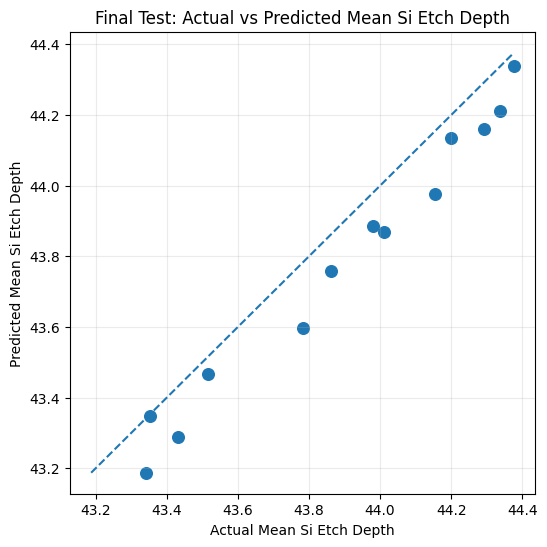

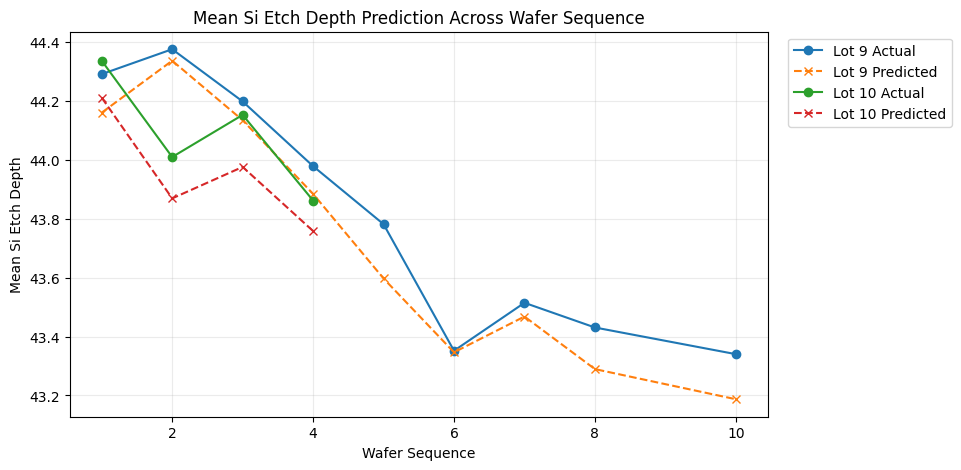

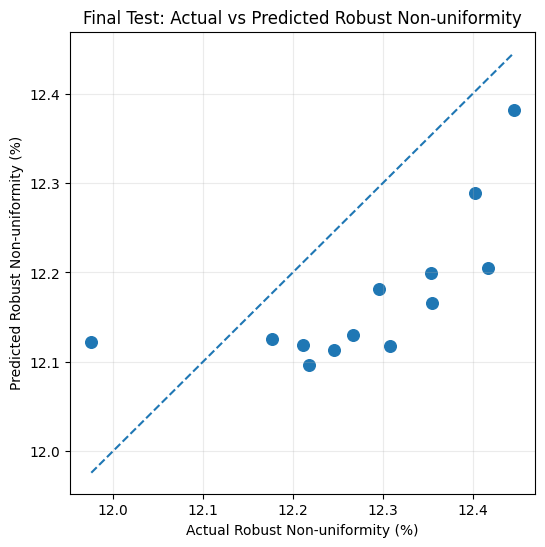

=== Largest Mean Depth Prediction Errors ===


,experiment_key,lot_number,wafer_sequence,actual_mean_si_etch,pred_mean_si_etch,depth_abs_error
4,2024-08-21_05,9,5,43.781948,43.597472,0.184476
11,2024-08-22_03,10,3,44.153194,43.976421,0.176773
8,2024-08-21_10,9,10,43.340424,43.187296,0.153127
7,2024-08-21_08,9,8,43.430984,43.289611,0.141374
10,2024-08-22_02,10,2,44.010088,43.869550,0.140538
0,2024-08-21_01,9,1,44.291687,44.160849,0.130837
9,2024-08-22_01,10,1,44.337099,44.211656,0.125443
12,2024-08-22_04,10,4,43.862195,43.758669,0.103526
3,2024-08-21_04,9,4,43.979012,43.884877,0.094135
2,2024-08-21_03,9,3,44.198883,44.134975,0.063908


In [ ]:
# ============================================================
# Cell 37. Visualize Final Test Predictions
# ============================================================

# ------------------------------------------------------------
# 1. Mean Si Etch Depth
#    Actual vs Predicted
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))

plt.scatter(
    y_depth_test,
    depth_test_pred,
    s=70
)

min_value = min(
    y_depth_test.min(),
    depth_test_pred.min()
)

max_value = max(
    y_depth_test.max(),
    depth_test_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual Mean Si Etch Depth"
)

plt.ylabel(
    "Predicted Mean Si Etch Depth"
)

plt.title(
    "Final Test: Actual vs Predicted Mean Si Etch Depth"
)

plt.grid(alpha=0.25)

plt.show()


# ------------------------------------------------------------
# 2. Mean Depth vs Wafer Sequence
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for lot_number in sorted(
    final_test_df[
        "lot_number"
    ].unique()
):

    mask = (
        final_test_df[
            "lot_number"
        ].values
        ==
        lot_number
    )

    sequence = (
        final_test_df.loc[
            mask,
            "wafer_sequence"
        ].values
    )

    actual = (
        y_depth_test.values[
            mask
        ]
    )

    predicted = (
        depth_test_pred[
            mask
        ]
    )


    plt.plot(
        sequence,
        actual,
        marker="o",
        label=f"Lot {lot_number} Actual"
    )

    plt.plot(
        sequence,
        predicted,
        marker="x",
        linestyle="--",
        label=f"Lot {lot_number} Predicted"
    )


plt.xlabel("Wafer Sequence")
plt.ylabel("Mean Si Etch Depth")

plt.title(
    "Mean Si Etch Depth Prediction Across Wafer Sequence"
)

plt.grid(alpha=0.25)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.show()


# ------------------------------------------------------------
# 3. Robust Non-uniformity
#    Actual vs Predicted
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))

plt.scatter(
    y_uniformity_test,
    uniformity_test_pred,
    s=70
)

min_value = min(
    y_uniformity_test.min(),
    uniformity_test_pred.min()
)

max_value = max(
    y_uniformity_test.max(),
    uniformity_test_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual Robust Non-uniformity (%)"
)

plt.ylabel(
    "Predicted Robust Non-uniformity (%)"
)

plt.title(
    "Final Test: Actual vs Predicted Robust Non-uniformity"
)

plt.grid(alpha=0.25)

plt.show()


# ------------------------------------------------------------
# 4. Largest Mean Depth Errors
# ------------------------------------------------------------

print(
    "=== Largest Mean Depth Prediction Errors ==="
)

display(
    final_prediction_df
    .sort_values(
        "depth_abs_error",
        ascending=False
    )[
        [
            "experiment_key",
            "lot_number",
            "wafer_sequence",
            "actual_mean_si_etch",
            "pred_mean_si_etch",
            "depth_abs_error"
        ]
    ]
)

### Mean Si Etch Depth Model 해석

Final Test에서 높은 일반화 성능을 보인 Ridge Regression을 대상으로 Process Feature의 영향을 분석한다.

Ridge Model은 StandardScaler를 적용한 Process Feature를 입력으로 사용하므로, 학습된 Coefficient의 절대값을 이용하여 각 Feature의 상대적인 Prediction 기여도를 비교할 수 있다.

- Positive Coefficient: 해당 Feature가 증가할수록 Predicted Mean Si Etch Depth가 증가하는 방향
- Negative Coefficient: 해당 Feature가 증가할수록 Predicted Mean Si Etch Depth가 감소하는 방향
- Absolute Coefficient가 클수록 Model Prediction에서 상대적으로 큰 영향을 가짐

단, Ridge Coefficient는 Model Prediction에서의 통계적 관계를 나타내며 해당 Process Variable이 Etch 변화의 물리적 Root Cause임을 의미하지 않는다.

=== Ridge Feature Importance ===


,feature,coefficient,abs_coefficient,direction
0,PlatenRFTuningCapacitor_mean,-0.093353,0.093353,Negative
1,SourceRFReflectedPower_std,-0.080898,0.080898,Negative
2,active_duration_sec,0.070157,0.070157,Positive
3,SourceRFPeakToPeak_mean,0.060495,0.060495,Positive
4,ForeLinePressure_std,-0.059155,0.059155,Negative
5,PlatenRFTuningCapacitor_std,0.054676,0.054676,Positive
6,Pressure_std,-0.052106,0.052106,Negative
7,SourceRFReflectedPower_mean,-0.051610,0.051610,Negative
8,SourceRFLoadPower_mean,0.050974,0.050974,Positive
9,PlatenRFPeakToPeak_mean,-0.046423,0.046423,Negative


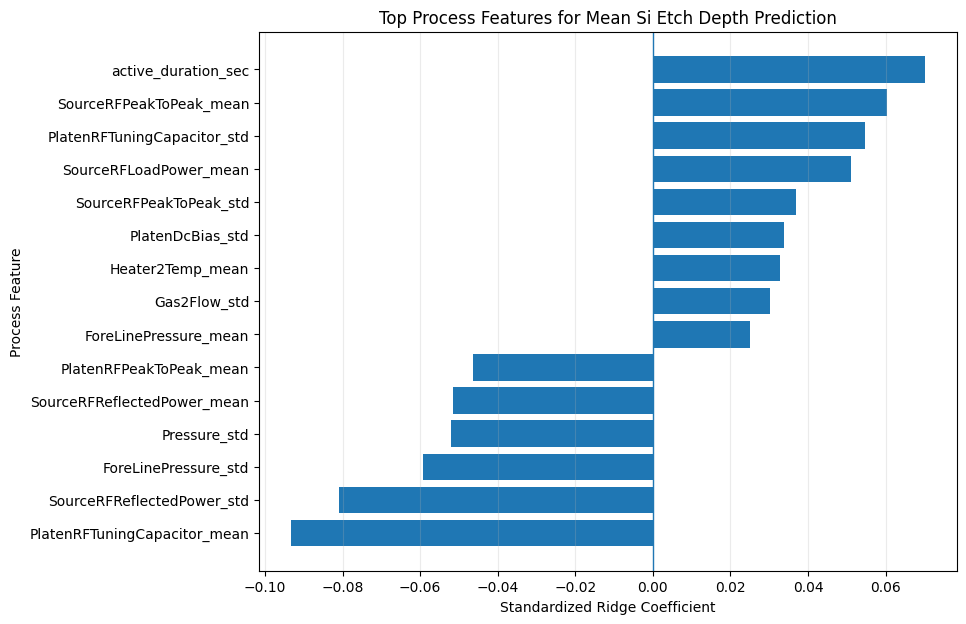


=== Total Absolute Coefficient by Feature Type ===


,sum_abs_coefficient
feature_type,
Std,0.573982
Mean,0.526081
Other,0.070157


In [ ]:
# ============================================================
# Cell 38. Interpret Final Ridge Model Coefficients
# ============================================================

# ------------------------------------------------------------
# 1. Final Ridge Pipeline 내부 Model 추출
# ------------------------------------------------------------

final_scaler = (
    final_depth_model.named_steps[
        "scaler"
    ]
)

final_ridge = (
    final_depth_model.named_steps[
        "ridge"
    ]
)


ridge_coefficients = (
    final_ridge.coef_
)


# ------------------------------------------------------------
# 2. Coefficient Table 생성
# ------------------------------------------------------------

ridge_coefficient_df = pd.DataFrame({

    "feature":
        selected_process_features,

    "coefficient":
        ridge_coefficients
})


ridge_coefficient_df[
    "abs_coefficient"
] = (
    ridge_coefficient_df[
        "coefficient"
    ].abs()
)


ridge_coefficient_df[
    "direction"
] = np.where(

    ridge_coefficient_df[
        "coefficient"
    ] >= 0,

    "Positive",

    "Negative"
)


ridge_coefficient_df = (
    ridge_coefficient_df
    .sort_values(
        "abs_coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "=== Ridge Feature Importance ==="
)

display(
    ridge_coefficient_df.head(20)
)


# ------------------------------------------------------------
# 3. Top 15 Feature Visualization
# ------------------------------------------------------------

top_n = 15

top_ridge_features = (
    ridge_coefficient_df
    .head(top_n)
    .sort_values(
        "coefficient"
    )
)


plt.figure(
    figsize=(9, 7)
)

plt.barh(
    top_ridge_features[
        "feature"
    ],
    top_ridge_features[
        "coefficient"
    ]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "Standardized Ridge Coefficient"
)

plt.ylabel(
    "Process Feature"
)

plt.title(
    "Top Process Features for Mean Si Etch Depth Prediction"
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.show()


# ------------------------------------------------------------
# 4. Mean / Std Feature 비중 확인
# ------------------------------------------------------------

ridge_coefficient_df[
    "feature_type"
] = np.where(

    ridge_coefficient_df[
        "feature"
    ].str.endswith(
        "_mean"
    ),

    "Mean",

    np.where(

        ridge_coefficient_df[
            "feature"
        ].str.endswith(
            "_std"
        ),

        "Std",

        "Other"
    )
)


feature_type_importance = (
    ridge_coefficient_df
    .groupby(
        "feature_type"
    )[
        "abs_coefficient"
    ]
    .sum()
    .sort_values(
        ascending=False
    )
)


print(
    "\n=== Total Absolute Coefficient by Feature Type ==="
)

display(
    feature_type_importance
    .rename(
        "sum_abs_coefficient"
    )
    .to_frame()
)

### Mean Si Etch Depth Prediction에 중요한 Process Feature

Final Ridge Model의 Standardized Coefficient를 분석한 결과, Platen RF Tuning, Source RF Reflected/Peak-to-Peak/Load Power, Pressure Variation 및 Main Etch Duration 관련 Feature가 Mean Si Etch Depth Prediction에 상대적으로 큰 영향을 보였다.

또한 Mean Feature와 Standard Deviation Feature의 전체 Absolute Coefficient 크기가 유사하게 나타나, Model은 Process의 평균 Operating Level뿐 아니라 BOSCH Etch 중 발생하는 Process Variation도 Prediction에 활용하고 있음을 확인하였다.

단, Process Feature 간 상관관계가 존재할 수 있으므로 개별 Ridge Coefficient를 물리적 중요도 또는 Root Cause로 직접 해석하지 않는다. 본 결과는 이후 Wafer Sequence에 따른 Process Drift를 조사하기 위한 우선 분석 Feature로 활용한다.

=== Selected Features for Drift Analysis ===
PlatenRFTuningCapacitor_mean
SourceRFReflectedPower_std
SourceRFPeakToPeak_mean
ForeLinePressure_std
PlatenRFTuningCapacitor_std
Pressure_std


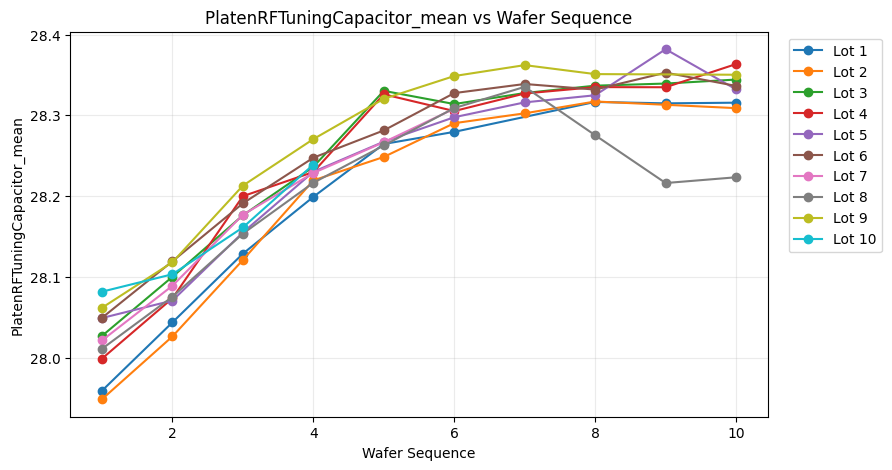

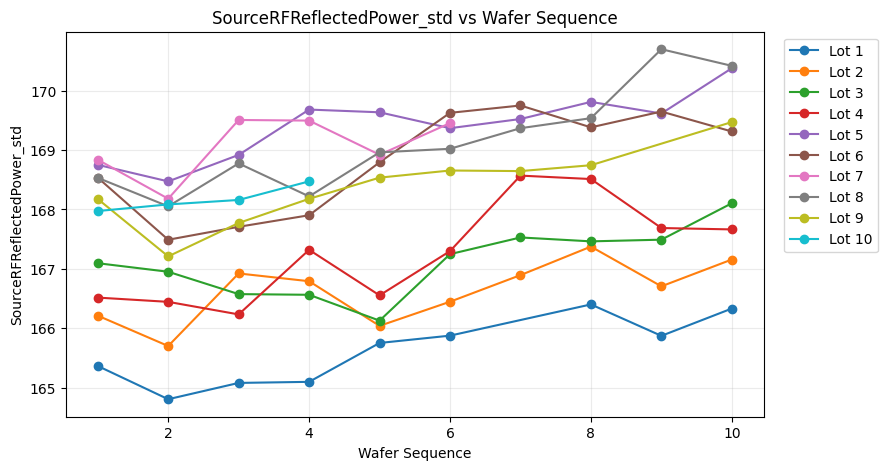

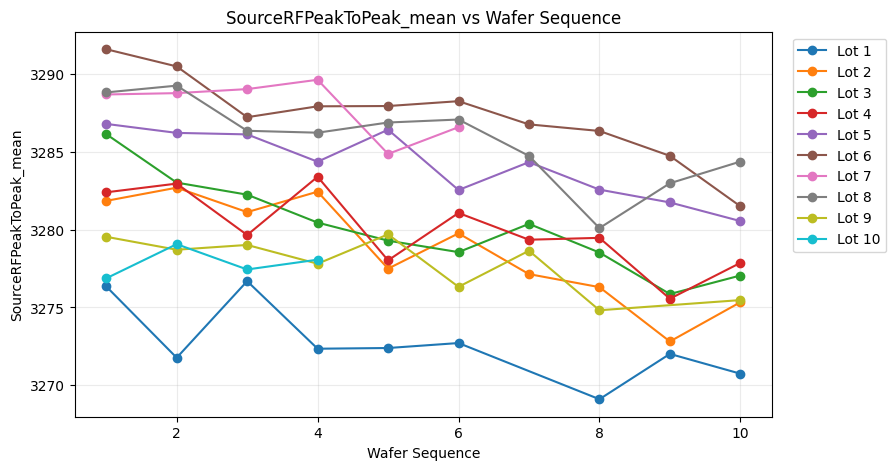

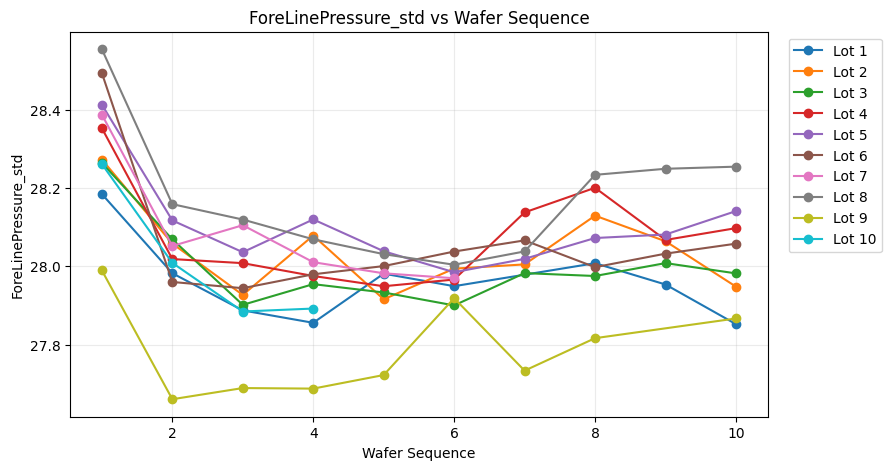

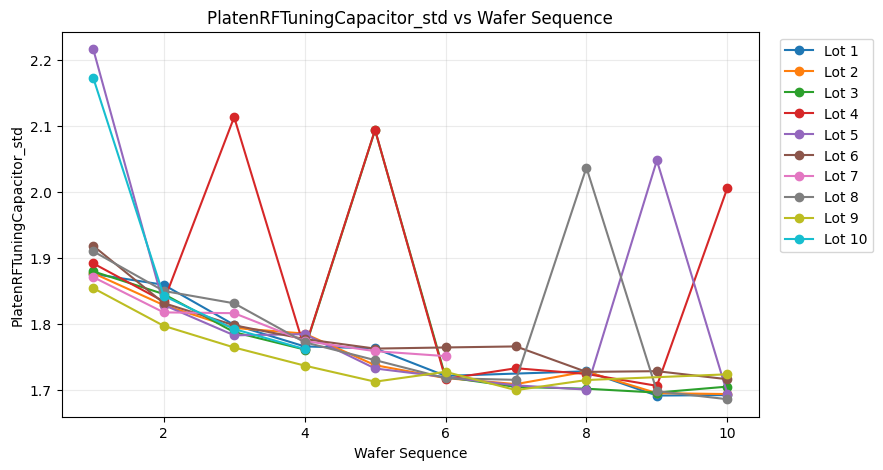

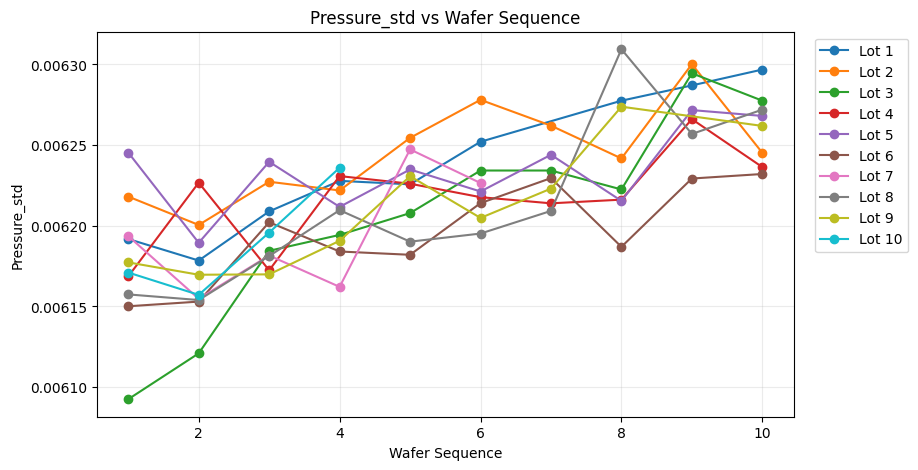


=== Wafer Sequence vs Process Feature ===


,feature,lot_number,n_wafers,spearman_rho,p_value
30,ForeLinePressure_std,1,9,-0.433333,2.439524e-01
31,ForeLinePressure_std,2,10,-0.163636,6.514773e-01
32,ForeLinePressure_std,3,10,-0.127273,7.260570e-01
33,ForeLinePressure_std,4,10,0.127273,7.260570e-01
34,ForeLinePressure_std,5,10,-0.163636,6.514773e-01
35,ForeLinePressure_std,6,10,0.272727,4.458383e-01
36,ForeLinePressure_std,7,6,-0.942857,4.804665e-03
37,ForeLinePressure_std,8,10,0.066667,8.548131e-01
38,ForeLinePressure_std,9,9,0.283333,4.600303e-01
39,ForeLinePressure_std,10,4,-0.800000,2.000000e-01



=== Process Drift Summary ===


,feature,mean_spearman_rho,median_spearman_rho,positive_lots,negative_lots
2,PlatenRFTuningCapacitor_std,-0.821515,-0.872727,0,10
4,SourceRFPeakToPeak_mean,-0.653658,-0.806061,1,9
0,ForeLinePressure_std,-0.188074,-0.145455,4,6
3,Pressure_std,0.754437,0.815152,10,0
5,SourceRFReflectedPower_std,0.771190,0.775758,10,0
1,PlatenRFTuningCapacitor_mean,0.931364,0.957576,10,0


In [ ]:
# ============================================================
# Cell 39. Analyze Process Feature Drift Across Wafer Sequence
# ============================================================

# Ridge 기준 상위 Process Feature
TOP_DRIFT_FEATURES = (
    ridge_coefficient_df[
        ridge_coefficient_df["feature"]
        != "active_duration_sec"
    ]
    .head(6)["feature"]
    .tolist()
)


print("=== Selected Features for Drift Analysis ===")

for feature in TOP_DRIFT_FEATURES:
    print(feature)


# ------------------------------------------------------------
# 1. Process Feature + Target Table
# ------------------------------------------------------------

drift_analysis_df = (
    modeling_df[
        [
            "experiment_key",
            "lot_number",
            "conditioning_type",
            "wafer_sequence",
            "mean_si_etch"
        ]
        +
        TOP_DRIFT_FEATURES
    ]
    .copy()
)


# ------------------------------------------------------------
# 2. Feature별 Wafer Sequence Plot
# ------------------------------------------------------------

for feature in TOP_DRIFT_FEATURES:

    plt.figure(
        figsize=(9, 5)
    )

    for lot_number, lot_df in (
        drift_analysis_df
        .groupby("lot_number")
    ):

        lot_df = (
            lot_df
            .sort_values(
                "wafer_sequence"
            )
        )

        plt.plot(
            lot_df["wafer_sequence"],
            lot_df[feature],
            marker="o",
            label=f"Lot {lot_number}"
        )

    plt.xlabel(
        "Wafer Sequence"
    )

    plt.ylabel(
        feature
    )

    plt.title(
        f"{feature} vs Wafer Sequence"
    )

    plt.grid(
        alpha=0.25
    )

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.show()


# ------------------------------------------------------------
# 3. Lot별 Sequence Correlation
# ------------------------------------------------------------

from scipy.stats import spearmanr


drift_records = []


for feature in TOP_DRIFT_FEATURES:

    for lot_number, lot_df in (
        drift_analysis_df
        .groupby("lot_number")
    ):

        if len(lot_df) < 3:
            continue

        rho, p_value = spearmanr(
            lot_df["wafer_sequence"],
            lot_df[feature]
        )

        drift_records.append({

            "feature":
                feature,

            "lot_number":
                lot_number,

            "n_wafers":
                len(lot_df),

            "spearman_rho":
                rho,

            "p_value":
                p_value
        })


process_drift_correlation_df = pd.DataFrame(
    drift_records
)


print(
    "\n=== Wafer Sequence vs Process Feature ==="
)

display(
    process_drift_correlation_df
    .sort_values(
        [
            "feature",
            "lot_number"
        ]
    )
)


# ------------------------------------------------------------
# 4. Feature별 Drift Direction 요약
# ------------------------------------------------------------

drift_summary_df = (
    process_drift_correlation_df
    .groupby("feature")
    .agg(

        mean_spearman_rho=(
            "spearman_rho",
            "mean"
        ),

        median_spearman_rho=(
            "spearman_rho",
            "median"
        ),

        positive_lots=(
            "spearman_rho",
            lambda x: (x > 0).sum()
        ),

        negative_lots=(
            "spearman_rho",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)


print(
    "\n=== Process Drift Summary ==="
)

display(
    drift_summary_df
    .sort_values(
        "mean_spearman_rho"
    )
)

### Wafer Sequence에 따른 Process Drift

Ridge Model에서 높은 Prediction 기여도를 보인 Process Feature를 대상으로 Wafer Sequence에 따른 변화를 분석하였다.

`PlatenRFTuningCapacitor_mean`은 모든 Lot에서 Wafer Sequence가 증가할수록 증가하는 강한 경향을 보였으며, `Pressure_std`와 `SourceRFReflectedPower_std` 역시 모든 Lot에서 증가하였다.

반대로 `PlatenRFTuningCapacitor_std`와 `SourceRFPeakToPeak_mean`은 대부분의 Lot에서 Wafer Sequence가 증가할수록 감소하였다.

Ridge Coefficient의 방향과 함께 해석하면 주요 Process Feature의 Sequence Drift가 대부분 Mean Si Etch Depth Prediction을 감소시키는 방향과 일치하였다. 이는 앞서 관찰된 Wafer Sequence 증가에 따른 Mean Si Etch Depth 감소와 일관된 Pattern이다.

단, 이러한 관계는 Process Signal과 Etch Result 사이의 통계적 연관성을 나타내며 특정 Process Variable을 물리적 Root Cause로 확정하지 않는다.

In [ ]:
# ============================================================
# Cell 40. Link Process Feature Drift to Mean Si Etch Depth
# ============================================================

from scipy.stats import spearmanr


feature_depth_records = []


for feature in TOP_DRIFT_FEATURES:

    for lot_number, lot_df in (
        drift_analysis_df
        .groupby("lot_number")
    ):

        if len(lot_df) < 3:
            continue


        rho, p_value = spearmanr(

            lot_df[feature],

            lot_df[
                "mean_si_etch"
            ]
        )


        feature_depth_records.append({

            "feature":
                feature,

            "lot_number":
                lot_number,

            "n_wafers":
                len(lot_df),

            "feature_depth_rho":
                rho,

            "p_value":
                p_value
        })


feature_depth_correlation_df = (
    pd.DataFrame(
        feature_depth_records
    )
)


# ------------------------------------------------------------
# 1. Lot별 관계
# ------------------------------------------------------------

print(
    "=== Process Feature vs Mean Si Etch Depth by Lot ==="
)

display(
    feature_depth_correlation_df
    .sort_values(
        [
            "feature",
            "lot_number"
        ]
    )
)


# ------------------------------------------------------------
# 2. Feature별 요약
# ------------------------------------------------------------

feature_depth_summary_df = (

    feature_depth_correlation_df

    .groupby("feature")

    .agg(

        mean_depth_rho=(
            "feature_depth_rho",
            "mean"
        ),

        median_depth_rho=(
            "feature_depth_rho",
            "median"
        ),

        positive_lots=(
            "feature_depth_rho",
            lambda x:
            (x > 0).sum()
        ),

        negative_lots=(
            "feature_depth_rho",
            lambda x:
            (x < 0).sum()
        )
    )

    .reset_index()
)


# ------------------------------------------------------------
# 3. Ridge Coefficient와 연결
# ------------------------------------------------------------

coefficient_lookup = (

    ridge_coefficient_df

    .set_index("feature")[
        "coefficient"
    ]

    .to_dict()
)


feature_depth_summary_df[
    "ridge_coefficient"
] = (

    feature_depth_summary_df[
        "feature"
    ]

    .map(
        coefficient_lookup
    )
)


feature_depth_summary_df[
    "ridge_direction"
] = np.where(

    feature_depth_summary_df[
        "ridge_coefficient"
    ] >= 0,

    "Positive",

    "Negative"
)


print(
    "\n=== Process–Etch Relationship Summary ==="
)

display(

    feature_depth_summary_df

    .sort_values(
        "mean_depth_rho"
    )
)

=== Process Feature vs Mean Si Etch Depth by Lot ===


,feature,lot_number,n_wafers,feature_depth_rho,p_value
30,ForeLinePressure_std,1,9,0.166667,0.668231
31,ForeLinePressure_std,2,10,-0.018182,0.960240
32,ForeLinePressure_std,3,10,-0.187879,0.603218
33,ForeLinePressure_std,4,10,-0.284848,0.425038
34,ForeLinePressure_std,5,10,-0.006061,0.986743
35,ForeLinePressure_std,6,10,-0.721212,0.018573
36,ForeLinePressure_std,7,6,0.714286,0.110787
37,ForeLinePressure_std,8,10,0.042424,0.907364
38,ForeLinePressure_std,9,9,-0.500000,0.170471
39,ForeLinePressure_std,10,4,0.400000,0.600000



=== Process–Etch Relationship Summary ===


,feature,mean_depth_rho,median_depth_rho,positive_lots,negative_lots,ridge_coefficient,ridge_direction
1,PlatenRFTuningCapacitor_mean,-0.854026,-0.854545,0,10,-0.093353,Negative
5,SourceRFReflectedPower_std,-0.819740,-0.831818,0,10,-0.080898,Negative
3,Pressure_std,-0.622446,-0.691775,0,10,-0.052106,Negative
0,ForeLinePressure_std,-0.039481,-0.012121,4,6,-0.059155,Negative
4,SourceRFPeakToPeak_mean,0.551602,0.710606,9,1,0.060495,Positive
2,PlatenRFTuningCapacitor_std,0.760238,0.784848,10,0,0.054676,Positive


### Process Drift와 Mean Si Etch Depth의 관계

Wafer Sequence에 따라 Drift가 관찰된 주요 Process Feature와 Mean Si Etch Depth의 관계를 Lot별로 분석하였다.

`PlatenRFTuningCapacitor_mean`, `SourceRFReflectedPower_std`, `Pressure_std`는 모든 Lot에서 Mean Si Etch Depth와 음의 관계를 나타냈으며, Ridge Model의 Coefficient 방향 역시 음수로 일치하였다.

반대로 `PlatenRFTuningCapacitor_std`는 모든 Lot에서 Mean Si Etch Depth와 양의 관계를 보였고, `SourceRFPeakToPeak_mean` 역시 대부분의 Lot에서 양의 관계를 나타냈다. 이들 Feature의 Ridge Coefficient 또한 양수로 나타났다.

따라서 Virtual Metrology Model이 학습한 주요 Feature–Target 관계가 실제 Lot 내부의 Process–Etch Trend와 대체로 일치함을 확인하였다.

이는 연속 Wafer 처리 과정에서 발생하는 Process Signal Drift가 Mean Si Etch Depth Drift와 통계적으로 연결되어 있음을 보여준다. 다만 본 분석은 상관관계를 기반으로 하므로 개별 Process Variable을 물리적 Root Cause로 확정하지 않는다.

### 89-point Spatial Etch Profile Prediction

기존 Virtual Metrology에서는 각 Wafer의 89-point Si Etch Measurement를 평균하여 Mean Si Etch Depth를 예측하였다.

확장 실험에서는 Wafer-level Process Feature를 이용하여 89개 측정 위치의 Si Etch Depth를 각각 예측하고, Wafer 내부의 Spatial Etch Profile을 복원할 수 있는지 평가한다.

입력은 기존 Main Model과 동일한 Wafer-level Process Feature를 사용하며, 출력은 각 Wafer의 89개 위치별 `si_etch` 값으로 구성한다.

이를 통해 Global Mean Etch Depth뿐 아니라 Process Sensor만으로 Wafer 내 Spatial Etch Pattern까지 어느 정도 예측 가능한지 확인한다.

In [ ]:
# ============================================================
# Cell 41. Build 89-Point Spatial Profile Target Matrix
# ============================================================

# ------------------------------------------------------------
# 1. 89개 측정 위치의 고유 좌표 확인
# ------------------------------------------------------------

spatial_coordinates_df = (
    etch_89_df[
        ["X", "Y"]
    ]
    .drop_duplicates()
    .sort_values(
        ["Y", "X"]
    )
    .reset_index(drop=True)
)


print(
    "=== Number of Spatial Positions ==="
)

print(
    len(spatial_coordinates_df)
)


# 각 위치에 Point ID 부여
spatial_coordinates_df[
    "point_id"
] = [
    f"P{i:02d}"
    for i in range(
        1,
        len(spatial_coordinates_df) + 1
    )
]


print(
    "\n=== Spatial Coordinate Table ==="
)

display(
    spatial_coordinates_df.head(15)
)


# ------------------------------------------------------------
# 2. 원본 Measurement에 Point ID 연결
# ------------------------------------------------------------

profile_long_df = (
    etch_89_df
    .merge(
        spatial_coordinates_df,
        on=["X", "Y"],
        how="left"
    )
)


# ------------------------------------------------------------
# 3. Wafer × 89-point 형태로 Pivot
# ------------------------------------------------------------

spatial_target_df = (
    profile_long_df
    .pivot(
        index="experiment_key",
        columns="point_id",
        values="si_etch"
    )
    .reset_index()
)


# Point 순서 고정
point_columns = [
    f"P{i:02d}"
    for i in range(1, 90)
]


spatial_target_df = (
    spatial_target_df[
        ["experiment_key"]
        +
        point_columns
    ]
)


print(
    "\n=== Spatial Target Matrix ==="
)

print(
    "Shape:",
    spatial_target_df.shape
)

display(
    spatial_target_df.head()
)


# ------------------------------------------------------------
# 4. Data Quality Check
# ------------------------------------------------------------

print(
    "\n=== Spatial Target Quality Check ==="
)

print(
    "Number of wafers:",
    spatial_target_df[
        "experiment_key"
    ].nunique()
)

print(
    "Number of spatial targets:",
    len(point_columns)
)

print(
    "Missing values:",
    spatial_target_df[
        point_columns
    ]
    .isna()
    .sum()
    .sum()
)


# ------------------------------------------------------------
# 5. 기존 Modeling Dataset과 Matching 확인
# ------------------------------------------------------------

spatial_modeling_df = (
    wafer_process_feature_df
    .merge(
        spatial_target_df,
        on="experiment_key",
        how="inner"
    )
)


print(
    "\n=== Spatial Modeling Dataset ==="
)

print(
    "Shape:",
    spatial_modeling_df.shape
)

print(
    "Matched wafers:",
    len(spatial_modeling_df)
)

=== Number of Spatial Positions ===
89

=== Spatial Coordinate Table ===


,X,Y,point_id
0,-19000,-95000,P01
1,0,-95000,P02
2,19000,-95000,P03
3,-57000,-76000,P04
4,-38000,-76000,P05
5,-19000,-76000,P06
6,0,-76000,P07
7,19000,-76000,P08
8,38000,-76000,P09
9,57000,-76000,P10



=== Spatial Target Matrix ===
Shape: (88, 90)


point_id,experiment_key,P01,P02,P03,P04,P05,P06,P07,P08,P09,...,P80,P81,P82,P83,P84,P85,P86,P87,P88,P89
0,2024-07-02_01,52.4631,52.0382,52.6763,52.2696,46.4179,44.5572,44.0715,44.3729,45.9689,...,50.0913,44.0409,42.0889,41.5688,41.9096,43.5683,49.0835,48.2008,49.1994,48.8647
1,2024-07-02_02,51.8557,51.6577,51.8768,51.7274,46.1356,44.3268,43.8132,44.0873,45.6515,...,49.6303,43.7797,41.8875,41.3764,41.6763,43.2878,48.7186,48.5546,48.7846,48.4718
2,2024-07-02_03,51.9022,51.8088,51.9110,51.7477,46.2825,44.4751,43.9571,44.2043,45.7497,...,49.6813,43.8928,42.0026,41.4691,41.7701,43.3645,48.7265,48.6168,48.9139,48.4934
3,2024-07-02_04,51.6734,51.5531,51.6248,51.4123,46.0550,44.2967,43.7789,44.0365,45.5429,...,49.3479,43.6249,41.7623,41.2455,41.5451,43.1256,48.3879,48.2068,48.5062,48.1294
4,2024-07-02_05,51.0118,50.9866,51.0277,50.9621,45.5712,43.8106,43.3072,43.5752,45.1033,...,48.6335,43.0507,41.2247,40.7312,41.0353,42.6048,47.8923,47.7051,47.8398,47.6655



=== Spatial Target Quality Check ===
Number of wafers: 88
Number of spatial targets: 89
Missing values: 0

=== Spatial Modeling Dataset ===
Shape: (88, 156)
Matched wafers: 88


### Spatial Profile Prediction 평가 기준

89-point Spatial Profile Prediction에서는 각 Wafer의 89개 위치를 동시에 예측한다.

단순한 Global Mean이 아니라 Training Data에서 각 측정 위치별 평균 Si Etch Depth를 계산한 `Mean Spatial Profile`을 Baseline으로 사용한다.

이를 통해 Process Feature를 이용한 Multi-output Regression이 단순히 평균적인 Wafer Spatial Pattern을 반복하는 것보다 새로운 Wafer의 위치별 Etch Variation을 추가적으로 설명할 수 있는지 평가한다.

평가는 다음 지표를 중심으로 수행한다.

- Point-wise MAE: 모든 Wafer와 89개 위치에서의 평균 절대 오차
- Wafer Profile MAE: 각 Wafer의 89-point Prediction Error 평균
- Spatial Correlation: 실제와 예측된 89-point Profile의 공간적 형태 유사도

In [ ]:
# ============================================================
# Cell 42. Build Spatial Development / Final Test Sets
# ============================================================

# ------------------------------------------------------------
# 1. Development / Test Wafer Key
# ------------------------------------------------------------

development_keys = set(
    development_df[
        "experiment_key"
    ]
)

final_test_keys = set(
    final_test_df[
        "experiment_key"
    ]
)


# ------------------------------------------------------------
# 2. Spatial Dataset Split
# ------------------------------------------------------------

spatial_development_df = (
    spatial_modeling_df[
        spatial_modeling_df[
            "experiment_key"
        ].isin(
            development_keys
        )
    ]
    .copy()
    .reset_index(drop=True)
)


spatial_final_test_df = (
    spatial_modeling_df[
        spatial_modeling_df[
            "experiment_key"
        ].isin(
            final_test_keys
        )
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. X / Y 구성
# ------------------------------------------------------------

X_spatial_dev = (
    spatial_development_df[
        selected_process_features
    ]
    .copy()
)


Y_spatial_dev = (
    spatial_development_df[
        point_columns
    ]
    .copy()
)


X_spatial_test = (
    spatial_final_test_df[
        selected_process_features
    ]
    .copy()
)


Y_spatial_test = (
    spatial_final_test_df[
        point_columns
    ]
    .copy()
)


spatial_groups_dev = (
    spatial_development_df[
        "lot_number"
    ]
    .copy()
)


# ------------------------------------------------------------
# 4. 확인
# ------------------------------------------------------------

print(
    "=== Spatial Dataset Split ==="
)

print(
    "Development wafers:",
    len(
        spatial_development_df
    )
)

print(
    "Final test wafers:",
    len(
        spatial_final_test_df
    )
)


print(
    "\nX Development:",
    X_spatial_dev.shape
)

print(
    "Y Development:",
    Y_spatial_dev.shape
)

print(
    "X Final Test:",
    X_spatial_test.shape
)

print(
    "Y Final Test:",
    Y_spatial_test.shape
)


print(
    "\nDevelopment Lots:",
    sorted(
        spatial_development_df[
            "lot_number"
        ].unique()
    )
)

print(
    "Final Test Lots:",
    sorted(
        spatial_final_test_df[
            "lot_number"
        ].unique()
    )
)


print(
    "\nMissing X:",
    X_spatial_dev
    .isna()
    .sum()
    .sum()
)

print(
    "Missing Y:",
    Y_spatial_dev
    .isna()
    .sum()
    .sum()
)

=== Spatial Dataset Split ===
Development wafers: 75
Final test wafers: 13

X Development: (75, 53)
Y Development: (75, 89)
X Final Test: (13, 53)
Y Final Test: (13, 89)

Development Lots: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Final Test Lots: [np.int64(9), np.int64(10)]

Missing X: 0
Missing Y: 0


### 89-point Spatial Profile Prediction 평가

Process Feature로 89개 위치의 Si Etch Depth를 직접 예측하는 Multi-output Regression을 수행한다.

먼저 Training Wafer의 각 위치별 평균 Etch Depth를 그대로 사용하는 `Mean Spatial Profile`을 Baseline으로 설정하고, Process Feature를 이용하는 Multi-output Ridge Regression과 비교한다.

평가는 다음 관점에서 수행한다.

- Point MAE: 89개 위치별 Etch Depth Prediction Error
- Spatial Correlation: 실제와 예측 Wafer Profile의 공간적 형태 유사도
- Derived Robust Non-uniformity MAE: 예측된 89-point Profile로부터 다시 계산한 Robust Non-uniformity의 오차

이를 통해 Process Sensor가 평균적인 Wafer Pattern을 넘어 Wafer별 Spatial Etch Variation까지 예측할 수 있는지 확인한다.

In [ ]:
# ============================================================
# Cell 43. Mean Spatial Profile vs Multi-output Ridge
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from scipy.stats import pearsonr


# ------------------------------------------------------------
# Ridge Alpha Candidates
# ------------------------------------------------------------

SPATIAL_RIDGE_ALPHAS = [
    0.1,
    1.0,
    10.0,
    100.0
]


# ------------------------------------------------------------
# Robust Non-uniformity 계산 함수
# ------------------------------------------------------------

def calculate_robust_nonuniformity(
    profile
):

    profile = np.asarray(profile)

    mean_value = np.mean(
        profile
    )

    p05 = np.percentile(
        profile,
        5
    )

    p95 = np.percentile(
        profile,
        95
    )

    return (
        (p95 - p05)
        /
        (2 * mean_value)
        *
        100
    )


# ------------------------------------------------------------
# Wafer별 Spatial Correlation
# ------------------------------------------------------------

def calculate_spatial_correlation(
    actual_profiles,
    predicted_profiles
):

    correlations = []

    for actual, predicted in zip(
        actual_profiles,
        predicted_profiles
    ):

        if (
            np.std(actual) == 0
            or
            np.std(predicted) == 0
        ):

            correlations.append(
                np.nan
            )

        else:

            corr = np.corrcoef(
                actual,
                predicted
            )[0, 1]

            correlations.append(
                corr
            )

    return np.array(
        correlations
    )


# ------------------------------------------------------------
# CV Result Storage
# ------------------------------------------------------------

spatial_cv_records = []


# ============================================================
# 1. Mean Spatial Profile Baseline
# ============================================================

for fold, (
    train_idx,
    val_idx
) in enumerate(
    group_cv.split(
        X_spatial_dev,
        Y_spatial_dev,
        groups=spatial_groups_dev
    ),
    start=1
):

    X_train = (
        X_spatial_dev.iloc[
            train_idx
        ]
    )

    X_val = (
        X_spatial_dev.iloc[
            val_idx
        ]
    )

    Y_train = (
        Y_spatial_dev.iloc[
            train_idx
        ]
        .to_numpy()
    )

    Y_val = (
        Y_spatial_dev.iloc[
            val_idx
        ]
        .to_numpy()
    )


    # ----------------------------------------
    # Training Wafer들의 평균 Spatial Profile
    # ----------------------------------------

    mean_profile = np.mean(
        Y_train,
        axis=0
    )


    baseline_pred = np.tile(
        mean_profile,
        (
            len(val_idx),
            1
        )
    )


    # ----------------------------------------
    # Point-wise Error
    # ----------------------------------------

    point_mae = np.mean(
        np.abs(
            Y_val
            -
            baseline_pred
        )
    )

    point_rmse = np.sqrt(
        np.mean(
            (
                Y_val
                -
                baseline_pred
            ) ** 2
        )
    )


    # ----------------------------------------
    # Spatial Correlation
    # ----------------------------------------

    spatial_corr = (
        calculate_spatial_correlation(
            Y_val,
            baseline_pred
        )
    )


    # ----------------------------------------
    # Derived Robust Non-uniformity
    # ----------------------------------------

    actual_uniformity = np.array([
        calculate_robust_nonuniformity(
            profile
        )
        for profile in Y_val
    ])

    predicted_uniformity = np.array([
        calculate_robust_nonuniformity(
            profile
        )
        for profile in baseline_pred
    ])


    uniformity_mae = np.mean(
        np.abs(
            actual_uniformity
            -
            predicted_uniformity
        )
    )


    spatial_cv_records.append({

        "model":
            "Mean Spatial Profile",

        "alpha":
            np.nan,

        "fold":
            fold,

        "validation_lot":
            int(
                spatial_groups_dev
                .iloc[val_idx]
                .iloc[0]
            ),

        "point_MAE":
            point_mae,

        "point_RMSE":
            point_rmse,

        "mean_spatial_corr":
            np.nanmean(
                spatial_corr
            ),

        "uniformity_MAE":
            uniformity_mae
    })


# ============================================================
# 2. Multi-output Ridge
# ============================================================

for alpha in SPATIAL_RIDGE_ALPHAS:

    for fold, (
        train_idx,
        val_idx
    ) in enumerate(
        group_cv.split(
            X_spatial_dev,
            Y_spatial_dev,
            groups=spatial_groups_dev
        ),
        start=1
    ):

        X_train = (
            X_spatial_dev.iloc[
                train_idx
            ]
        )

        X_val = (
            X_spatial_dev.iloc[
                val_idx
            ]
        )

        Y_train = (
            Y_spatial_dev.iloc[
                train_idx
            ]
            .to_numpy()
        )

        Y_val = (
            Y_spatial_dev.iloc[
                val_idx
            ]
            .to_numpy()
        )


        # ------------------------------------
        # Multi-output Ridge
        # Ridge는 89개 Target을 동시에 처리 가능
        # ------------------------------------

        model = Pipeline([

            (
                "scaler",
                StandardScaler()
            ),

            (
                "ridge",
                Ridge(
                    alpha=alpha
                )
            )
        ])


        model.fit(
            X_train,
            Y_train
        )


        prediction = model.predict(
            X_val
        )


        # ------------------------------------
        # Point-wise Error
        # ------------------------------------

        point_mae = np.mean(
            np.abs(
                Y_val
                -
                prediction
            )
        )

        point_rmse = np.sqrt(
            np.mean(
                (
                    Y_val
                    -
                    prediction
                ) ** 2
            )
        )


        # ------------------------------------
        # Spatial Correlation
        # ------------------------------------

        spatial_corr = (
            calculate_spatial_correlation(
                Y_val,
                prediction
            )
        )


        # ------------------------------------
        # Derived Robust Non-uniformity
        # ------------------------------------

        actual_uniformity = np.array([
            calculate_robust_nonuniformity(
                profile
            )
            for profile in Y_val
        ])

        predicted_uniformity = np.array([
            calculate_robust_nonuniformity(
                profile
            )
            for profile in prediction
        ])


        uniformity_mae = np.mean(
            np.abs(
                actual_uniformity
                -
                predicted_uniformity
            )
        )


        spatial_cv_records.append({

            "model":
                "Multi-output Ridge",

            "alpha":
                alpha,

            "fold":
                fold,

            "validation_lot":
                int(
                    spatial_groups_dev
                    .iloc[val_idx]
                    .iloc[0]
                ),

            "point_MAE":
                point_mae,

            "point_RMSE":
                point_rmse,

            "mean_spatial_corr":
                np.nanmean(
                    spatial_corr
                ),

            "uniformity_MAE":
                uniformity_mae
        })


# ============================================================
# Results
# ============================================================

spatial_cv_results_df = pd.DataFrame(
    spatial_cv_records
)


spatial_cv_summary_df = (
    spatial_cv_results_df
    .groupby(
        [
            "model",
            "alpha"
        ],
        dropna=False
    )
    .agg(

        mean_point_MAE=(
            "point_MAE",
            "mean"
        ),

        std_point_MAE=(
            "point_MAE",
            "std"
        ),

        mean_point_RMSE=(
            "point_RMSE",
            "mean"
        ),

        mean_spatial_corr=(
            "mean_spatial_corr",
            "mean"
        ),

        mean_uniformity_MAE=(
            "uniformity_MAE",
            "mean"
        )
    )
    .reset_index()
)


print(
    "=== Spatial Profile CV Summary ==="
)

display(
    spatial_cv_summary_df
    .sort_values(
        "mean_point_MAE"
    )
)

=== Spatial Profile CV Summary ===


,model,alpha,mean_point_MAE,std_point_MAE,mean_point_RMSE,mean_spatial_corr,mean_uniformity_MAE
3,Multi-output Ridge,10.0,0.159653,0.022414,0.345455,0.995924,0.107060
4,Multi-output Ridge,100.0,0.186569,0.036386,0.313300,0.997380,0.089692
2,Multi-output Ridge,1.0,0.188049,0.035462,0.509827,0.990373,0.128959
1,Multi-output Ridge,0.1,0.239076,0.049735,0.645358,0.984628,0.160133
0,Mean Spatial Profile,NaN,0.344265,0.095557,0.457907,0.997497,0.135127


### 89-point Spatial Profile Cross Validation 결과

Training Wafer의 위치별 평균 Etch Depth를 사용하는 Mean Spatial Profile Baseline과 Multi-output Ridge Regression을 Lot-aware Cross Validation으로 비교하였다.

Mean Spatial Profile Baseline의 Point MAE는 0.344였으며, Multi-output Ridge Regression(`alpha=10`)에서는 Point MAE가 0.160으로 감소하였다. 이는 Process Feature를 이용함으로써 단순한 평균 Spatial Profile 대비 위치별 Etch Depth Prediction Error가 약 54% 감소했음을 의미한다.

Spatial Correlation은 Baseline에서도 0.997로 매우 높게 나타났다. 이는 대부분의 Wafer가 Center/Edge 차이와 같은 공통적인 Spatial Pattern을 공유하기 때문이다. 따라서 Spatial Correlation만으로 Wafer별 Prediction 성능을 판단하지 않고 Point MAE와 함께 평가하였다.

또한 Ridge(`alpha=10`)의 Predicted 89-point Profile에서 계산한 Robust Non-uniformity MAE는 0.107로 Baseline의 0.135보다 감소하였다.

따라서 Process Sensor는 공통적인 Wafer Spatial Pattern뿐 아니라 개별 Wafer의 위치별 Etch Depth Variation을 추가적으로 예측하는 정보를 포함하는 것으로 판단하였다.

In [ ]:
# ============================================================
# Cell 44. Final Test of 89-Point Spatial Profile Model
# ============================================================

# ------------------------------------------------------------
# 1. Final Multi-output Ridge
#    CV에서 Point MAE 기준 Best Alpha = 10
# ------------------------------------------------------------

final_spatial_model = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "ridge",
        Ridge(
            alpha=10.0
        )
    )
])


final_spatial_model.fit(
    X_spatial_dev,
    Y_spatial_dev
)


spatial_test_pred = (
    final_spatial_model.predict(
        X_spatial_test
    )
)


Y_spatial_test_np = (
    Y_spatial_test.to_numpy()
)


# ------------------------------------------------------------
# 2. Mean Spatial Profile Baseline
# ------------------------------------------------------------

mean_spatial_profile = (
    Y_spatial_dev
    .mean(axis=0)
    .to_numpy()
)


spatial_baseline_pred = np.tile(
    mean_spatial_profile,
    (
        len(Y_spatial_test_np),
        1
    )
)


# ------------------------------------------------------------
# 3. Evaluation Function
# ------------------------------------------------------------

def evaluate_spatial_predictions(
    actual,
    predicted,
    model_name
):

    # 89-point 전체 평균 MAE
    point_mae = np.mean(
        np.abs(
            actual - predicted
        )
    )

    # 89-point 전체 RMSE
    point_rmse = np.sqrt(
        np.mean(
            (actual - predicted) ** 2
        )
    )

    # Wafer별 Spatial Correlation
    spatial_corr = (
        calculate_spatial_correlation(
            actual,
            predicted
        )
    )

    # 실제 Profile에서 Uniformity 계산
    actual_uniformity = np.array([
        calculate_robust_nonuniformity(
            profile
        )
        for profile in actual
    ])

    # 예측 Profile에서 Uniformity 계산
    predicted_uniformity = np.array([
        calculate_robust_nonuniformity(
            profile
        )
        for profile in predicted
    ])

    # Uniformity MAE
    uniformity_mae = np.mean(
        np.abs(
            actual_uniformity
            -
            predicted_uniformity
        )
    )

    return {

        "model":
            model_name,

        "point_MAE":
            point_mae,

        "point_RMSE":
            point_rmse,

        "mean_spatial_corr":
            np.nanmean(
                spatial_corr
            ),

        "uniformity_MAE":
            uniformity_mae
    }


# ------------------------------------------------------------
# 4. Baseline vs Multi-output Ridge
# ------------------------------------------------------------

spatial_final_results = []


spatial_final_results.append(
    evaluate_spatial_predictions(
        Y_spatial_test_np,
        spatial_baseline_pred,
        "Mean Spatial Profile"
    )
)


spatial_final_results.append(
    evaluate_spatial_predictions(
        Y_spatial_test_np,
        spatial_test_pred,
        "Multi-output Ridge"
    )
)


spatial_final_test_results_df = (
    pd.DataFrame(
        spatial_final_results
    )
)


print(
    "=== Spatial Profile Final Test Performance ==="
)

display(
    spatial_final_test_results_df
)

=== Spatial Profile Final Test Performance ===


,model,point_MAE,point_RMSE,mean_spatial_corr,uniformity_MAE
0,Mean Spatial Profile,0.402313,0.477852,0.999663,0.124851
1,Multi-output Ridge,0.141911,0.212106,0.999122,0.161855


In [ ]:
# ============================================================
# Cell 45. Evaluate Wafer-Specific Spatial Variation
# ============================================================

def center_profiles(profiles):

    profiles = np.asarray(profiles)

    wafer_means = np.mean(
        profiles,
        axis=1,
        keepdims=True
    )

    return profiles - wafer_means


# ------------------------------------------------------------
# 1. Center each wafer profile
# ------------------------------------------------------------

actual_centered = center_profiles(
    Y_spatial_test_np
)

baseline_centered = center_profiles(
    spatial_baseline_pred
)

ridge_centered = center_profiles(
    spatial_test_pred
)


# ------------------------------------------------------------
# 2. Centered Profile MAE
# ------------------------------------------------------------

baseline_centered_mae = np.mean(
    np.abs(
        actual_centered
        -
        baseline_centered
    )
)

ridge_centered_mae = np.mean(
    np.abs(
        actual_centered
        -
        ridge_centered
    )
)


# ------------------------------------------------------------
# 3. Centered Spatial Correlation
# ------------------------------------------------------------

baseline_centered_corr = (
    calculate_spatial_correlation(
        actual_centered,
        baseline_centered
    )
)

ridge_centered_corr = (
    calculate_spatial_correlation(
        actual_centered,
        ridge_centered
    )
)


# ------------------------------------------------------------
# 4. Wafer Mean Etch Depth Error
# ------------------------------------------------------------

actual_mean_depth = np.mean(
    Y_spatial_test_np,
    axis=1
)

baseline_mean_depth = np.mean(
    spatial_baseline_pred,
    axis=1
)

ridge_mean_depth = np.mean(
    spatial_test_pred,
    axis=1
)


baseline_mean_depth_mae = np.mean(
    np.abs(
        actual_mean_depth
        -
        baseline_mean_depth
    )
)

ridge_mean_depth_mae = np.mean(
    np.abs(
        actual_mean_depth
        -
        ridge_mean_depth
    )
)


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

spatial_pattern_summary = pd.DataFrame({

    "model": [
        "Mean Spatial Profile",
        "Multi-output Ridge"
    ],

    "mean_depth_MAE": [
        baseline_mean_depth_mae,
        ridge_mean_depth_mae
    ],

    "centered_profile_MAE": [
        baseline_centered_mae,
        ridge_centered_mae
    ],

    "centered_spatial_corr": [
        np.nanmean(
            baseline_centered_corr
        ),
        np.nanmean(
            ridge_centered_corr
        )
    ]
})


print(
    "=== Wafer-Specific Spatial Variation Test ==="
)

display(
    spatial_pattern_summary
)

=== Wafer-Specific Spatial Variation Test ===


,model,mean_depth_MAE,centered_profile_MAE,centered_spatial_corr
0,Mean Spatial Profile,0.400599,0.107559,0.999663
1,Multi-output Ridge,0.108084,0.107199,0.999122


### Spatial Profile Prediction 결과 및 한계

Multi-output Ridge Regression을 이용하여 53개의 Process Feature로 89-point Si Etch Depth를 예측하였다.

Unseen Lot 9–10 Final Test에서 Mean Spatial Profile Baseline의 Point MAE는 0.402였으나, Multi-output Ridge에서는 0.142로 감소하여 위치별 Absolute Etch Depth Prediction 성능이 크게 향상되었다.

그러나 각 Wafer의 평균 Etch Depth를 제거한 뒤 Spatial Pattern 자체를 평가한 결과, Centered Profile MAE는 Baseline 0.1076, Ridge 0.1072로 거의 차이가 없었다. 또한 Predicted Profile로부터 계산한 Robust Non-uniformity 역시 Baseline보다 개선되지 않았다.

따라서 Multi-output Ridge의 89-point Prediction 성능 향상은 주로 Wafer별 Global Etch Depth Level을 정확하게 조정한 결과이며, 현재의 Global Process Sensor Feature만으로 Wafer 내부의 미세한 Spatial Variation이나 Uniformity를 안정적으로 예측하기에는 한계가 있는 것으로 판단하였다.

이는 Mean Etch Depth는 Chamber-level Process Signal과 강한 관계를 가지지만, Spatial Uniformity는 Local Temperature, Chuck/Backside He Condition, Radial Plasma Distribution 등 현재 Feature에 포함되지 않은 추가적인 Spatial Information의 영향을 받을 가능성이 있음을 시사한다.

### Final Test Spatial Map Visualization

Final Test Wafer에 대해 실제 89-point Si Etch Depth와 Multi-output Ridge Prediction을 Wafer Spatial Map으로 비교한다.

또한 `Prediction - Actual` Error Map을 함께 시각화하여, 모델이 전체 Etch Depth Level은 잘 추종하는지 그리고 위치별 Spatial Variation에서는 어떤 오차가 남는지 확인한다.

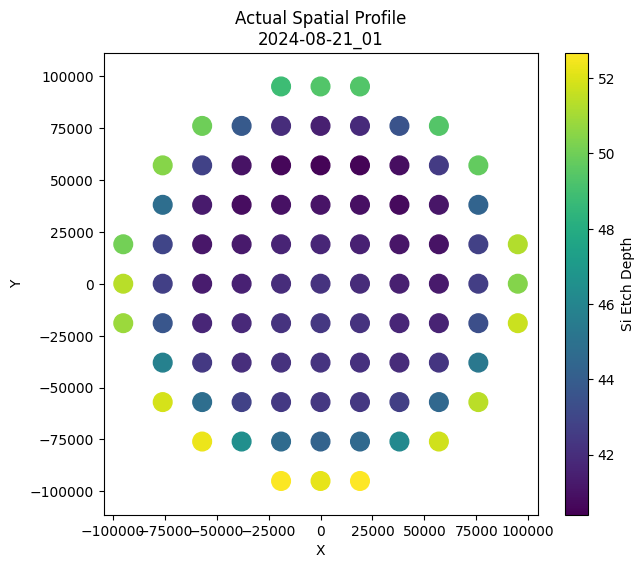

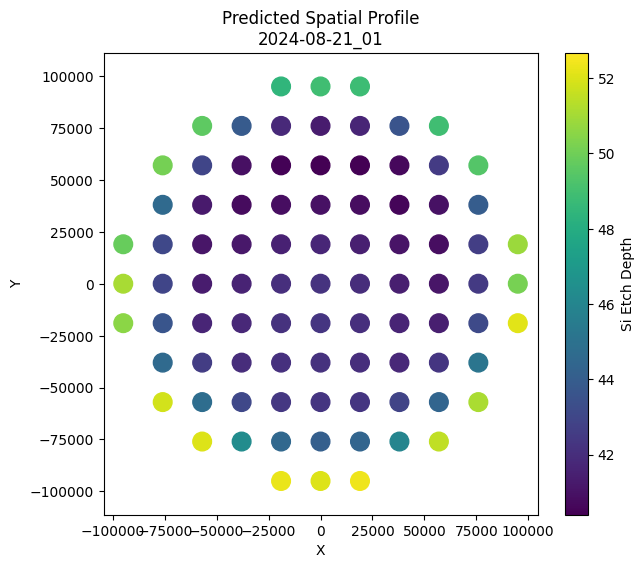

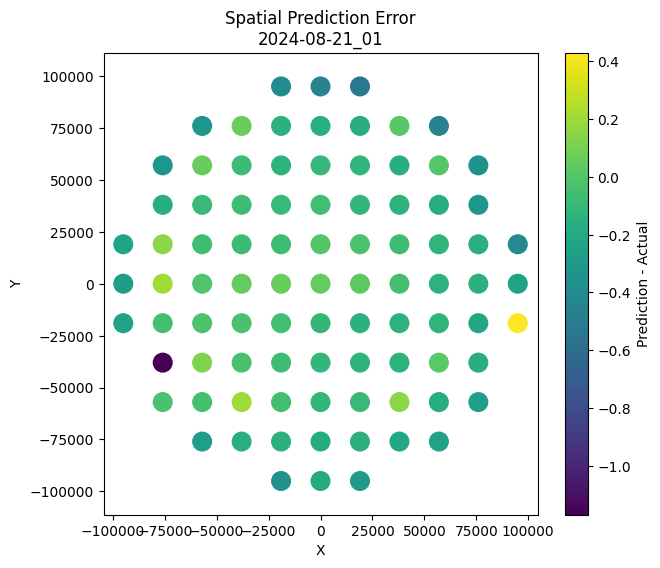

=== Wafer Spatial Prediction Summary ===
Wafer: 2024-08-21_01
Point MAE: 0.167278
Actual Mean Depth: 44.291687
Predicted Mean Depth: 44.160849
Actual Robust Uniformity: 12.403163
Predicted Robust Uniformity: 12.698328


In [ ]:
# ============================================================
# Cell 46. Visualize Actual vs Predicted Spatial Maps
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Plotting Function
# ------------------------------------------------------------

def plot_spatial_map(
    values,
    coordinates_df,
    title,
    vmin=None,
    vmax=None
):

    plt.scatter(
        coordinates_df["X"],
        coordinates_df["Y"],
        c=values,
        s=180,
        vmin=vmin,
        vmax=vmax
    )

    plt.colorbar(
        label="Si Etch Depth"
    )

    plt.xlabel(
        "X"
    )

    plt.ylabel(
        "Y"
    )

    plt.title(
        title
    )

    plt.axis(
        "equal"
    )


# ------------------------------------------------------------
# 2. Final Test Wafer 하나 선택
# ------------------------------------------------------------

wafer_idx = 0

wafer_name = (
    spatial_final_test_df
    .iloc[
        wafer_idx
    ][
        "experiment_key"
    ]
)


actual_profile = (
    Y_spatial_test_np[
        wafer_idx
    ]
)

predicted_profile = (
    spatial_test_pred[
        wafer_idx
    ]
)

error_profile = (
    predicted_profile
    -
    actual_profile
)


# ------------------------------------------------------------
# 3. Actual / Predicted 공통 Color Scale
# ------------------------------------------------------------

profile_min = min(
    actual_profile.min(),
    predicted_profile.min()
)

profile_max = max(
    actual_profile.max(),
    predicted_profile.max()
)


# ------------------------------------------------------------
# 4. Actual Map
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)

plot_spatial_map(
    actual_profile,
    spatial_coordinates_df,
    f"Actual Spatial Profile\n{wafer_name}",
    vmin=profile_min,
    vmax=profile_max
)

plt.show()


# ------------------------------------------------------------
# 5. Predicted Map
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)

plot_spatial_map(
    predicted_profile,
    spatial_coordinates_df,
    f"Predicted Spatial Profile\n{wafer_name}",
    vmin=profile_min,
    vmax=profile_max
)

plt.show()


# ------------------------------------------------------------
# 6. Error Map
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    spatial_coordinates_df["X"],
    spatial_coordinates_df["Y"],
    c=error_profile,
    s=180
)

plt.colorbar(
    label="Prediction - Actual"
)

plt.xlabel(
    "X"
)

plt.ylabel(
    "Y"
)

plt.title(
    f"Spatial Prediction Error\n{wafer_name}"
)

plt.axis(
    "equal"
)

plt.show()


# ------------------------------------------------------------
# 7. Numerical Summary
# ------------------------------------------------------------

wafer_mae = np.mean(
    np.abs(
        error_profile
    )
)


actual_mean = np.mean(
    actual_profile
)

predicted_mean = np.mean(
    predicted_profile
)


actual_uniformity = (
    calculate_robust_nonuniformity(
        actual_profile
    )
)

predicted_uniformity = (
    calculate_robust_nonuniformity(
        predicted_profile
    )
)


print(
    "=== Wafer Spatial Prediction Summary ==="
)

print(
    "Wafer:",
    wafer_name
)

print(
    "Point MAE:",
    round(
        wafer_mae,
        6
    )
)

print(
    "Actual Mean Depth:",
    round(
        actual_mean,
        6
    )
)

print(
    "Predicted Mean Depth:",
    round(
        predicted_mean,
        6
    )
)

print(
    "Actual Robust Uniformity:",
    round(
        actual_uniformity,
        6
    )
)

print(
    "Predicted Robust Uniformity:",
    round(
        predicted_uniformity,
        6
    )
)

In [ ]:
# ============================================================
# Cell 47. Wafer-level Spatial Prediction Results
# ============================================================

spatial_wafer_records = []


for i in range(
    len(Y_spatial_test_np)
):

    actual = (
        Y_spatial_test_np[i]
    )

    predicted = (
        spatial_test_pred[i]
    )


    # ----------------------------------------
    # Experiment Key
    # ----------------------------------------

    experiment_key = (
        spatial_final_test_df
        .iloc[i][
            "experiment_key"
        ]
    )


    # experiment_key 예:
    # 2024-08-21_01 → wafer number = 1
    wafer_number = int(
        experiment_key.split("_")[-1]
    )


    # ----------------------------------------
    # Point MAE
    # ----------------------------------------

    point_mae = np.mean(
        np.abs(
            actual - predicted
        )
    )


    # ----------------------------------------
    # Mean Depth
    # ----------------------------------------

    actual_mean = np.mean(
        actual
    )

    predicted_mean = np.mean(
        predicted
    )

    mean_depth_error = abs(
        actual_mean
        -
        predicted_mean
    )


    # ----------------------------------------
    # Uniformity
    # ----------------------------------------

    actual_uniformity = (
        calculate_robust_nonuniformity(
            actual
        )
    )

    predicted_uniformity = (
        calculate_robust_nonuniformity(
            predicted
        )
    )

    uniformity_error = abs(
        actual_uniformity
        -
        predicted_uniformity
    )


    # ----------------------------------------
    # Spatial Correlation
    # ----------------------------------------

    spatial_corr = np.corrcoef(
        actual,
        predicted
    )[0, 1]


    # ----------------------------------------
    # Save Result
    # ----------------------------------------

    spatial_wafer_records.append({

        "experiment_key":
            experiment_key,

        "lot_number":
            spatial_final_test_df
            .iloc[i][
                "lot_number"
            ],

        "wafer_number":
            wafer_number,

        "point_MAE":
            point_mae,

        "mean_depth_error":
            mean_depth_error,

        "actual_uniformity":
            actual_uniformity,

        "predicted_uniformity":
            predicted_uniformity,

        "uniformity_error":
            uniformity_error,

        "spatial_corr":
            spatial_corr
    })


# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

spatial_wafer_results_df = (
    pd.DataFrame(
        spatial_wafer_records
    )
)


print(
    "=== Final Test Wafer-level Spatial Results ==="
)

display(
    spatial_wafer_results_df
    .sort_values(
        "point_MAE"
    )
)


print(
    "\n=== Best Spatial Prediction ==="
)

display(
    spatial_wafer_results_df
    .sort_values(
        "point_MAE"
    )
    .head(1)
)


print(
    "\n=== Worst Spatial Prediction ==="
)

display(
    spatial_wafer_results_df
    .sort_values(
        "point_MAE",
        ascending=False
    )
    .head(1)
)

=== Final Test Wafer-level Spatial Results ===


,experiment_key,lot_number,wafer_number,point_MAE,mean_depth_error,actual_uniformity,predicted_uniformity,uniformity_error,spatial_corr
6,2024-08-21_07,9,7,0.087507,0.046710,12.176783,12.115505,0.061277,0.999323
5,2024-08-21_06,9,6,0.089975,0.005283,12.245513,12.116896,0.128617,0.999116
1,2024-08-21_02,9,2,0.106889,0.038966,12.417505,12.296468,0.121037,0.999521
2,2024-08-21_03,9,3,0.111503,0.063908,12.355199,12.150352,0.204847,0.999421
3,2024-08-21_04,9,4,0.129233,0.094135,12.307803,12.111665,0.196137,0.999561
7,2024-08-21_08,9,8,0.141374,0.141374,12.211420,12.152311,0.059109,0.998831
12,2024-08-22_04,10,4,0.151872,0.103526,11.975552,12.301390,0.325838,0.998922
10,2024-08-22_02,10,2,0.156737,0.140538,12.353600,12.155514,0.198085,0.998661
8,2024-08-21_10,9,10,0.157766,0.153127,12.217347,12.142892,0.074456,0.998504
9,2024-08-22_01,10,1,0.160880,0.125443,12.446123,12.593020,0.146896,0.998581



=== Best Spatial Prediction ===


,experiment_key,lot_number,wafer_number,point_MAE,mean_depth_error,actual_uniformity,predicted_uniformity,uniformity_error,spatial_corr
6,2024-08-21_07,9,7,0.087507,0.04671,12.176783,12.115505,0.061277,0.999323



=== Worst Spatial Prediction ===


,experiment_key,lot_number,wafer_number,point_MAE,mean_depth_error,actual_uniformity,predicted_uniformity,uniformity_error,spatial_corr
4,2024-08-21_05,9,5,0.192961,0.184476,12.266425,12.116833,0.149592,0.999712


### Spatial Profile Prediction 최종 결과

Final Test Lot 9–10의 13개 Wafer에 대해 Multi-output Ridge Regression을 이용하여 89-point Si Etch Depth를 예측하였다.

Mean Spatial Profile Baseline의 Point MAE는 0.402였으며, Multi-output Ridge의 Point MAE는 0.142로 감소하여 약 65%의 Prediction Error Reduction을 보였다.

그러나 Wafer Mean Depth를 제거하고 Spatial Pattern 자체만 비교한 Centered Profile MAE는 Baseline 0.1076, Ridge 0.1072로 거의 차이가 없었다. 또한 Predicted 89-point Profile로부터 계산한 Robust Non-uniformity 역시 Final Test에서 Baseline보다 안정적으로 개선되지 않았다.

따라서 Multi-output Ridge는 새로운 Wafer의 Global Etch Depth Level을 반영하여 89-point Absolute Etch Depth를 정확하게 조정하는 데에는 성공했지만, Wafer별 미세한 Spatial Variation과 Uniformity까지 안정적으로 예측하지는 못하였다.

결과적으로 현재의 Chamber-level Process Feature는 Global Etch Depth Prediction에는 충분한 정보를 제공하지만, Within-wafer Spatial Uniformity Prediction에는 추가적인 Spatial Process Information이 필요한 것으로 판단된다.

=== Best Spatial Prediction ===
2024-08-21_07


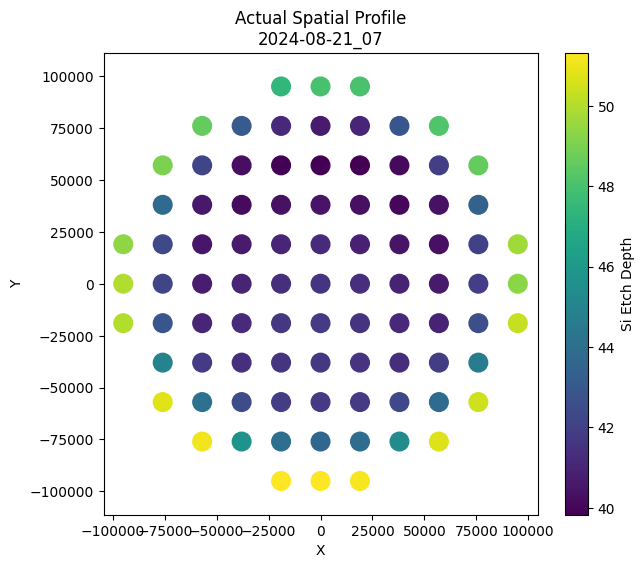

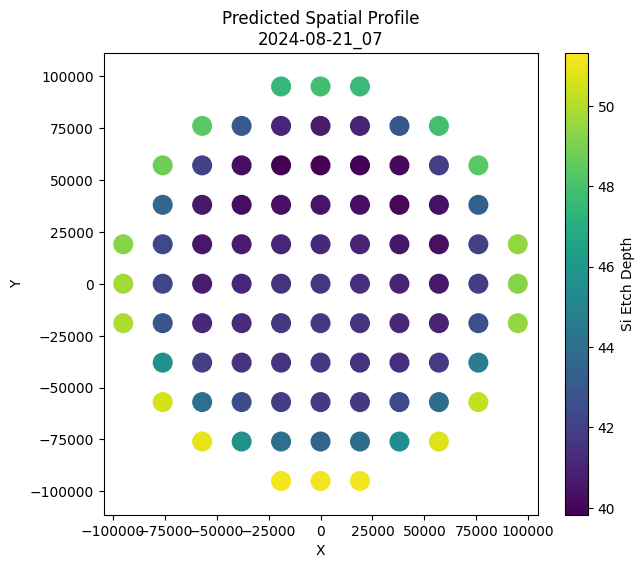

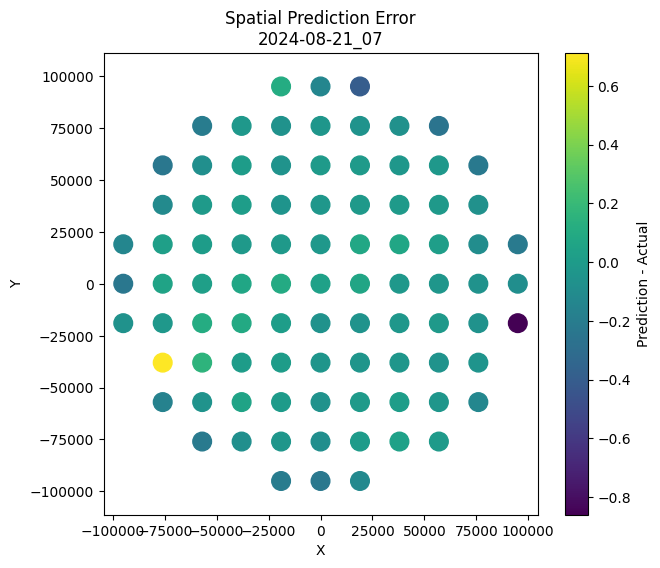

=== Worst Spatial Prediction ===
2024-08-21_05


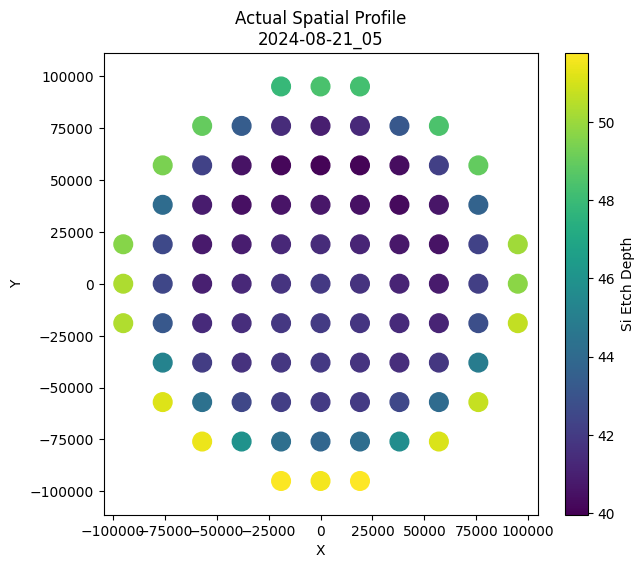

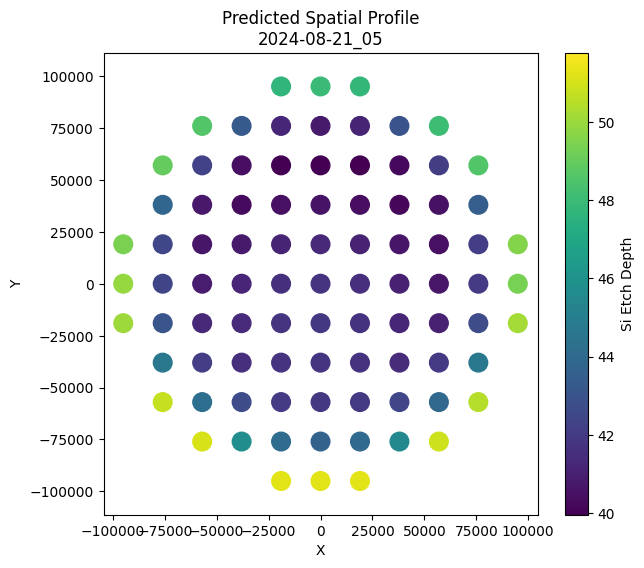

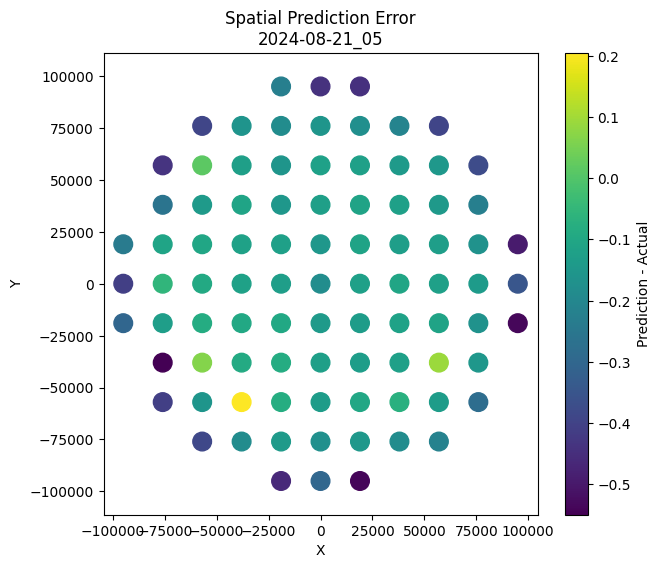

In [ ]:
# ============================================================
# Cell 48. Best / Worst Spatial Prediction Visualization
# ============================================================

# ------------------------------------------------------------
# 1. Best / Worst Wafer Index
# ------------------------------------------------------------

best_key = (
    spatial_wafer_results_df
    .sort_values("point_MAE")
    .iloc[0]["experiment_key"]
)

worst_key = (
    spatial_wafer_results_df
    .sort_values(
        "point_MAE",
        ascending=False
    )
    .iloc[0]["experiment_key"]
)


best_idx = (
    spatial_final_test_df[
        spatial_final_test_df[
            "experiment_key"
        ] == best_key
    ]
    .index[0]
)


worst_idx = (
    spatial_final_test_df[
        spatial_final_test_df[
            "experiment_key"
        ] == worst_key
    ]
    .index[0]
)


# ------------------------------------------------------------
# 2. Visualization Function
# ------------------------------------------------------------

def visualize_actual_vs_predicted(
    wafer_idx,
    wafer_name
):

    actual = (
        Y_spatial_test_np[
            wafer_idx
        ]
    )

    predicted = (
        spatial_test_pred[
            wafer_idx
        ]
    )

    error = (
        predicted
        -
        actual
    )


    profile_min = min(
        actual.min(),
        predicted.min()
    )

    profile_max = max(
        actual.max(),
        predicted.max()
    )


    # Actual
    plt.figure(
        figsize=(7, 6)
    )

    plot_spatial_map(
        actual,
        spatial_coordinates_df,
        f"Actual Spatial Profile\n{wafer_name}",
        vmin=profile_min,
        vmax=profile_max
    )

    plt.show()


    # Predicted
    plt.figure(
        figsize=(7, 6)
    )

    plot_spatial_map(
        predicted,
        spatial_coordinates_df,
        f"Predicted Spatial Profile\n{wafer_name}",
        vmin=profile_min,
        vmax=profile_max
    )

    plt.show()


    # Error
    plt.figure(
        figsize=(7, 6)
    )

    plt.scatter(
        spatial_coordinates_df["X"],
        spatial_coordinates_df["Y"],
        c=error,
        s=180
    )

    plt.colorbar(
        label="Prediction - Actual"
    )

    plt.xlabel("X")
    plt.ylabel("Y")

    plt.title(
        f"Spatial Prediction Error\n{wafer_name}"
    )

    plt.axis("equal")

    plt.show()


# ------------------------------------------------------------
# 3. Best Wafer
# ------------------------------------------------------------

print(
    "=== Best Spatial Prediction ==="
)

print(
    best_key
)

visualize_actual_vs_predicted(
    best_idx,
    best_key
)


# ------------------------------------------------------------
# 4. Worst Wafer
# ------------------------------------------------------------

print(
    "=== Worst Spatial Prediction ==="
)

print(
    worst_key
)

visualize_actual_vs_predicted(
    worst_idx,
    worst_key
)

## Final Project Summary

### Plasma Etch Virtual Metrology and Process Drift Analysis

본 프로젝트에서는 Plasma Etch 공정의 Chamber-level Process Sensor Data를 이용하여 공정 후 Si Etch 결과를 예측하고, Wafer Sequence에 따른 Process Drift와 주요 Process–Etch Relationship을 분석하였다.

전체 분석 Pipeline은 다음과 같다.

Process Sensor Time-series  
→ Dictionary Decoding  
→ Main Etch Active Window Detection  
→ Wafer-level Feature Engineering  
→ Lot-aware Model Validation  
→ Mean Si Etch Depth Virtual Metrology  
→ Robust Non-uniformity Prediction  
→ Unseen Lot Final Test  
→ Ridge Feature Interpretation  
→ Wafer Sequence Process Drift Analysis  
→ Process–Etch Relationship Analysis  
→ 89-point Spatial Etch Profile Prediction

### Main Results

Mean Si Etch Depth Prediction에서는 Ridge Regression이 가장 안정적인 성능을 보였다. Development Lot 1–8을 이용한 Lot-aware Cross Validation에서 MAE 0.111을 기록하였으며, 한 번도 사용하지 않은 Final Test Lot 9–10에서도 MAE 0.108, R² 0.892를 기록하였다.

Wafer Sequence에 따라 Platen RF Tuning Capacitor, Source RF Reflected Power, Pressure Variation 등의 Process Feature에서 일관된 Drift가 관찰되었으며, 이러한 Feature의 변화 방향은 Mean Si Etch Depth 변화 및 Ridge Regression coefficient의 방향과 대체로 일치하였다.

반면 Robust Non-uniformity Prediction은 Development Cross Validation에서는 일부 개선이 나타났으나, Unseen Lot Final Test에서는 Dummy Baseline보다 성능이 저하되어 안정적인 Generalization에 실패하였다.

추가적으로 Multi-output Ridge Regression을 이용하여 89-point Si Etch Depth를 예측한 결과, Final Test에서 Mean Spatial Profile Baseline 대비 Point MAE가 0.402에서 0.142로 감소하였다. 그러나 Wafer Mean Depth를 제거한 Centered Spatial Profile에서는 Baseline 대비 거의 개선되지 않았으며, Predicted Spatial Profile로부터 계산한 Uniformity 역시 안정적으로 개선되지 않았다.

따라서 현재 Chamber-level Process Sensor Feature는 Wafer의 Global Etch Depth와 Process Drift를 설명하는 데에는 충분한 정보를 포함하지만, Within-wafer Spatial Uniformity를 예측하기 위해서는 추가적인 Spatial Process Information이 필요한 것으로 판단하였다.